# 1. Part I: Language Model Training and Comparison

Run from the project folder. Run All retrains models and overwrites artifacts; use scripts/verify_*.py to inspect saved results without training. The random-frozen run is cached when complete. All experiments and the report are complete. See README for data, dependencies, configurations and execution limits.

## 1.1 Data Preparation

### 1.1.1 Load and Inspect the Raw Corpus

Use Jane Austen’s Pride and Prejudice from Project Gutenberg (ebook 1342). Record the raw-file hash and use the same corpus, splits and vocabulary for every language model.

In [1]:
from pathlib import Path
import hashlib
import random
import re
SEED = 42
random.seed(SEED)
CORPUS_FILENAME = 'pride_and_prejudice_gutenberg_1342.txt'
data_candidates = (Path.cwd() / CORPUS_FILENAME, Path.cwd() / 'Assignment1_project' / CORPUS_FILENAME)
DATA_PATH = next((candidate for candidate in data_candidates if candidate.is_file()), data_candidates[0])
if not DATA_PATH.is_file():
    raise FileNotFoundError(f'Cannot find the corpus: {DATA_PATH.resolve()}')
raw_bytes = DATA_PATH.read_bytes()
raw_text = raw_bytes.decode('utf-8-sig')
corpus_sha256 = hashlib.sha256(raw_bytes).hexdigest()
print('Corpus:', DATA_PATH.name)
print('Source: Project Gutenberg, ebook 1342')
print(f'Characters: {len(raw_text):,}')


Corpus: pride_and_prejudice_gutenberg_1342.txt
Source: Project Gutenberg, ebook 1342
Characters: 728,846


### 1.1.2 Extract and Clean the Narrative

Extract the narrative and remove Gutenberg metadata, printer information, illustration blocks, chapter headings and emphasis underscores. Preserve paragraph boundaries; normalize whitespace without changing paragraph order.

In [2]:
opening = 'It is a truth universally acknowledged,'
end_marker = '*** END OF THE PROJECT GUTENBERG EBOOK 1342 ***'
start_index = raw_text.find(opening)
end_index = raw_text.find(end_marker)
if start_index < 0 or end_index < start_index:
    raise ValueError('Expected corpus boundaries were not found. Inspect the source file.')
body_text = raw_text[start_index:end_index]
printer_marker = 'CHISWICK PRESS:--CHARLES WHITTINGHAM AND CO.'
printer_index = body_text.rfind(printer_marker)
if printer_index >= 0:
    body_text = body_text[:printer_index]
illustration_pattern = '\\[Illustration\\b.*?\\]'
illustration_count = len(re.findall(illustration_pattern, body_text, flags=re.DOTALL))
clean_text = re.sub(illustration_pattern, '', body_text, flags=re.DOTALL)
clean_text = re.sub('(?m)^[ \\t]*Chapter[ \\t]+[IVXLCDM]+\\.[ \\t]*$', '', clean_text)
clean_text = clean_text.replace('_', '')
paragraphs = [re.sub('\\s+', ' ', paragraph).strip() for paragraph in re.split('\\n[ \\t]*\\n', clean_text.strip()) if paragraph.strip()]
clean_text = '\n\n'.join(paragraphs)
assert clean_text.startswith(opening)
assert 'Illustration' not in clean_text
assert 'CHISWICK PRESS' not in clean_text
assert '*** END OF' not in clean_text
assert 'had been the means of uniting them.' in paragraphs[-1]
print(f'Raw characters: {len(raw_text):,}')
print(f'Clean characters: {len(clean_text):,}')
print(f'Illustration blocks removed: {illustration_count}')
print(f'Paragraphs: {len(paragraphs):,}')


Raw characters: 728,846
Clean characters: 685,095
Illustration blocks removed: 155
Paragraphs: 2,154


### 1.1.3 Tokenize and Split the Corpus

Lowercase and regex-tokenize words, internal apostrophes, numbers and punctuation. Split complete paragraphs chronologically at approximately 80/10/10% of tokens. No paragraph or context crosses a split boundary.

In [3]:
from bisect import bisect_left
from itertools import accumulate
TRAIN_FRACTION = 0.8
VALIDATION_FRACTION = 0.1
TOKEN_PATTERN = re.compile("[a-z]+(?:'[a-z]+)*|[0-9]+|[^\\w\\s]", flags=re.ASCII)

def tokenize(text):
    normalized = text.lower().translate(str.maketrans({'’': "'", '‘': "'", '“': '"', '”': '"'}))
    return TOKEN_PATTERN.findall(normalized)
tokenized_paragraphs = [tokenize(paragraph) for paragraph in paragraphs]
assert all(tokenized_paragraphs), 'Empty tokenized paragraph found.'
cumulative_tokens = list(accumulate((len(tokens) for tokens in tokenized_paragraphs)))
total_tokens = cumulative_tokens[-1]
train_end = bisect_left(cumulative_tokens, total_tokens * TRAIN_FRACTION) + 1
validation_end = bisect_left(cumulative_tokens, total_tokens * (TRAIN_FRACTION + VALIDATION_FRACTION)) + 1
assert 0 < train_end < validation_end < len(tokenized_paragraphs)
split_paragraphs = {'train': tokenized_paragraphs[:train_end], 'validation': tokenized_paragraphs[train_end:validation_end], 'test': tokenized_paragraphs[validation_end:]}
split_ranges = {'train': (0, train_end), 'validation': (train_end, validation_end), 'test': (validation_end, len(tokenized_paragraphs))}
assert sum((len(items) for items in split_paragraphs.values())) == len(paragraphs)
print('Split        Paragraphs    Tokens    Token share')
for name, items in split_paragraphs.items():
    count = sum((len(tokens) for tokens in items))
    print(f'{name:<12} {len(items):>10,} {count:>9,} {count / total_tokens:>13.2%}')


Split        Paragraphs    Tokens    Token share
train             1,674   116,727        80.11%
validation          236    14,413         9.89%
test                244    14,567        10.00%


### 1.1.4 Build the Training Vocabulary and Encode Paragraphs

Build the vocabulary from training tokens only (minimum frequency 2), adding PAD/UNK/BOS/EOS. Map unseen words to UNK. Use the same token IDs for all models and report each split’s unknown-token rate.

In [4]:
from collections import Counter
MIN_FREQUENCY = 2
SPECIAL_TOKENS = ['<pad>', '<unk>', '<bos>', '<eos>']
train_counts = Counter((token for paragraph in split_paragraphs['train'] for token in paragraph))
vocabulary_tokens = sorted((token for token, count in train_counts.items() if count >= MIN_FREQUENCY), key=lambda token: (-train_counts[token], token))
id_to_token = SPECIAL_TOKENS + vocabulary_tokens
token_to_id = {token: index for index, token in enumerate(id_to_token)}
PAD_ID, UNK_ID, BOS_ID, EOS_ID = [token_to_id[token] for token in SPECIAL_TOKENS]
VOCAB_SIZE = len(id_to_token)

def encode_paragraph(tokens):
    return [BOS_ID] + [token_to_id.get(token, UNK_ID) for token in tokens] + [EOS_ID]
encoded_paragraphs = {name: [encode_paragraph(tokens) for tokens in items] for name, items in split_paragraphs.items()}
assert len(token_to_id) == len(id_to_token)
assert all((train_counts[token] >= MIN_FREQUENCY for token in vocabulary_tokens))
assert all((ids[0] == BOS_ID and ids[-1] == EOS_ID for items in encoded_paragraphs.values() for ids in items))
print(f'Minimum training frequency: {MIN_FREQUENCY}')
print(f'Vocabulary size including special tokens: {VOCAB_SIZE:,}')
print('Special token IDs:', {token: token_to_id[token] for token in SPECIAL_TOKENS})
print('\nSplit        Tokens    Unknown tokens    Unknown share')
for name, items in split_paragraphs.items():
    count = sum((len(tokens) for tokens in items))
    unknown = sum((token not in token_to_id for tokens in items for token in tokens))
    print(f'{name:<12} {count:>7,} {unknown:>17,} {unknown / count:>16.2%}')
print(' '.join((id_to_token[index] for index in encoded_paragraphs['train'][0])))


Minimum training frequency: 2
Vocabulary size including special tokens: 3,620
Special token IDs: {'<pad>': 0, '<unk>': 1, '<bos>': 2, '<eos>': 3}

Split        Tokens    Unknown tokens    Unknown share
train        116,727             2,348            2.01%
validation    14,413               431            2.99%
test          14,567               468            3.21%
<bos> it is a truth universally acknowledged , that a single man in possession of a good fortune must be in want of a wife . <eos>


## 1.2 N-gram Baseline

### 1.2.1 Train an Interpolated N-gram Baseline

Fit unigram, bigram and trigram counts on training paragraphs. Reset context at each paragraph, score body tokens and EOS, and use BOS only as context. Smooth each order before interpolation; the resulting distribution covers the full vocabulary.

In [5]:
required_names = ('VOCAB_SIZE', 'encoded_paragraphs', 'BOS_ID', 'PAD_ID')
missing_names = [name for name in required_names if name not in globals()]
if missing_names:
    raise RuntimeError('Data preparation has not been completed in this kernel. Run sections 1.1.1 through 1.1.4 first, or use Restart Kernel and Run All.' + ' Missing: ' + ', '.join(missing_names))
import math
import time
from collections import Counter, defaultdict

class InterpolatedNGramLM:

    def __init__(self, vocab_size, order=3, alpha=0.1, weights=(0.1, 0.3, 0.6)):
        if order < 1 or vocab_size < 1 or alpha <= 0:
            raise ValueError('Invalid model dimensions or smoothing parameter.')
        if len(weights) != order or any((weight < 0 for weight in weights)):
            raise ValueError('Provide one nonnegative weight per n-gram order.')
        if not math.isclose(sum(weights), 1.0):
            raise ValueError('Interpolation weights must sum to one.')
        self.vocab_size = vocab_size
        self.order = order
        self.alpha = alpha
        self.weights = tuple(weights)
        self.counts = [defaultdict(Counter) for _ in range(order)]
        self.totals = [Counter() for _ in range(order)]
        self.target_count = 0

    def fit(self, sequences):
        self.counts = [defaultdict(Counter) for _ in range(self.order)]
        self.totals = [Counter() for _ in range(self.order)]
        self.target_count = 0
        for sequence in sequences:
            for position in range(1, len(sequence)):
                target = sequence[position]
                for context_length in range(self.order):
                    context = tuple(sequence[max(0, position - context_length):position]) if context_length else ()
                    self.counts[context_length][context][target] += 1
                    self.totals[context_length][context] += 1
                self.target_count += 1
        return self

    def probability(self, target, preceding_tokens):
        if not 0 <= target < self.vocab_size:
            raise ValueError('Target ID is outside the vocabulary.')
        probability = 0.0
        for context_length, weight in enumerate(self.weights):
            context = tuple(preceding_tokens[-context_length:]) if context_length else ()
            successors = self.counts[context_length].get(context)
            count = successors.get(target, 0) if successors is not None else 0
            total = self.totals[context_length].get(context, 0)
            smoothed = (count + self.alpha) / (total + self.alpha * self.vocab_size)
            probability += weight * smoothed
        return probability
NGRAM_ORDER = 3
NGRAM_ALPHA = 0.1
NGRAM_WEIGHTS = (0.1, 0.3, 0.6)
ngram_model = InterpolatedNGramLM(VOCAB_SIZE, order=NGRAM_ORDER, alpha=NGRAM_ALPHA, weights=NGRAM_WEIGHTS)
start_time = time.perf_counter()
ngram_model.fit(encoded_paragraphs['train'])
ngram_training_seconds = time.perf_counter() - start_time
for history in ([BOS_ID], encoded_paragraphs['train'][0][:5], [PAD_ID, PAD_ID]):
    mass = sum((ngram_model.probability(target, history) for target in range(VOCAB_SIZE)))
    assert math.isclose(mass, 1.0, rel_tol=1e-09, abs_tol=1e-09)
assert ngram_model.target_count == sum((len(ids) - 1 for ids in encoded_paragraphs['train']))
ngram_stored_entries = sum((len(successors) for table in ngram_model.counts for successors in table.values()))
print('Model: interpolated trigram with additive smoothing')
print('Alpha:', NGRAM_ALPHA)
print('Weights (unigram, bigram, trigram):', NGRAM_WEIGHTS)
print(f'Training targets: {ngram_model.target_count:,}')
print(f'Stored context-target entries across orders: {ngram_stored_entries:,}')
print(f'Count-building time: {ngram_training_seconds:.3f} seconds')


Model: interpolated trigram with additive smoothing
Alpha: 0.1
Weights (unigram, bigram, trigram): (0.1, 0.3, 0.6)
Training targets: 118,401
Stored context-target entries across orders: 130,110
Count-building time: 0.325 seconds


### 1.2.2 Define Evaluation and Select N-gram Hyperparameters

Select smoothing and interpolation weights using validation CE across nine candidates. CE is total negative log probability divided by valid target count; PPL=exp(CE). Test data do not select settings.

In [6]:
required_names = ('ngram_model', 'encoded_paragraphs', 'PAD_ID', 'math', 'time')
missing_names = [name for name in required_names if name not in globals()]
if missing_names:
    raise RuntimeError('Run sections 1.1.1 through 1.2.1 successfully before validation selection.' + ' Missing: ' + ', '.join(missing_names))

def evaluate_ngram(model, sequences):
    total_nll = 0.0
    target_count = 0
    for sequence in sequences:
        for position in range(1, len(sequence)):
            target = sequence[position]
            if target == PAD_ID:
                continue
            history_start = max(0, position - (model.order - 1))
            history = sequence[history_start:position]
            probability = model.probability(target, history)
            if not 0.0 < probability <= 1.0:
                raise ValueError('The model returned an invalid target probability.')
            total_nll -= math.log(probability)
            target_count += 1
    if target_count == 0:
        raise ValueError('No valid targets were provided for evaluation.')
    cross_entropy = total_nll / target_count
    return {'cross_entropy': cross_entropy, 'perplexity': math.exp(cross_entropy), 'target_count': target_count, 'total_nll': total_nll}
NGRAM_ALPHA_CANDIDATES = (0.001, 0.01, 0.1)
NGRAM_WEIGHT_CANDIDATES = ((0.1, 0.3, 0.6), (0.2, 0.4, 0.4), (0.3, 0.5, 0.2))
validation_trials = []
selection_start = time.perf_counter()
for alpha in NGRAM_ALPHA_CANDIDATES:
    for weights in NGRAM_WEIGHT_CANDIDATES:
        ngram_model.alpha = alpha
        ngram_model.weights = weights
        metrics = evaluate_ngram(ngram_model, encoded_paragraphs['validation'])
        validation_trials.append({'alpha': alpha, 'weights': weights, **metrics})
ngram_selection_seconds = time.perf_counter() - selection_start
best_ngram_trial = min(validation_trials, key=lambda trial: trial['cross_entropy'])
ngram_model.alpha = best_ngram_trial['alpha']
ngram_model.weights = best_ngram_trial['weights']
NGRAM_ALPHA = ngram_model.alpha
NGRAM_WEIGHTS = ngram_model.weights
print('Validation-only hyperparameter comparison')
print('Alpha    Weights                  CE (nats)     PPL')
for trial in validation_trials:
    print(f"{trial['alpha']:<8g} {str(trial['weights']):<24} {trial['cross_entropy']:>9.4f} {trial['perplexity']:>9.2f}")
print('\nSelected alpha:', NGRAM_ALPHA)
print('Selected weights:', NGRAM_WEIGHTS)
print(f'Validation selection time: {ngram_selection_seconds:.3f} seconds')


Validation-only hyperparameter comparison
Alpha    Weights                  CE (nats)     PPL
0.001    (0.1, 0.3, 0.6)             4.7314    113.45
0.001    (0.2, 0.4, 0.4)             4.6144    100.93
0.001    (0.3, 0.5, 0.2)             4.5815     97.66
0.01     (0.1, 0.3, 0.6)             4.9304    138.43
0.01     (0.2, 0.4, 0.4)             4.7987    121.35
0.01     (0.3, 0.5, 0.2)             4.7365    114.03
0.1      (0.1, 0.3, 0.6)             5.4367    229.67
0.1      (0.2, 0.4, 0.4)             5.2370    188.11
0.1      (0.3, 0.5, 0.2)             5.1067    165.12

Selected alpha: 0.001
Selected weights: (0.3, 0.5, 0.2)
Validation selection time: 0.330 seconds


### 1.2.3 Evaluate the Selected N-gram Model

Evaluate the validation-selected n-gram on train, validation and test. Use identical body+EOS targets and token-weighted CE/PPL for all models; report counts to confirm the evaluation scope.

In [7]:
required_names = ('ngram_model', 'encoded_paragraphs', 'evaluate_ngram', 'best_ngram_trial', 'ngram_selection_seconds', 'ngram_training_seconds', 'ngram_stored_entries', 'NGRAM_ORDER', 'VOCAB_SIZE', 'SEED', 'corpus_sha256', 'math')
missing_names = [name for name in required_names if name not in globals()]
if missing_names:
    raise RuntimeError('Run section 1.2.2 (evaluation and validation selection) before section 1.7. Missing: ' + ', '.join(missing_names))
ngram_model.alpha = best_ngram_trial['alpha']
ngram_model.weights = tuple(best_ngram_trial['weights'])
NGRAM_ALPHA = ngram_model.alpha
NGRAM_WEIGHTS = ngram_model.weights
ngram_metrics = {'train': evaluate_ngram(ngram_model, encoded_paragraphs['train']), 'validation': evaluate_ngram(ngram_model, encoded_paragraphs['validation']), 'test': evaluate_ngram(ngram_model, encoded_paragraphs['test'])}
for name, metrics in ngram_metrics.items():
    expected_targets = sum((len(sequence) - 1 for sequence in encoded_paragraphs[name]))
    assert metrics['target_count'] == expected_targets
    assert math.isclose(math.log(metrics['perplexity']), metrics['cross_entropy'])
print('Split         Targets     CE (nats)       PPL')
for name, metrics in ngram_metrics.items():
    print(f"{name:<12} {metrics['target_count']:>8,} {metrics['cross_entropy']:>13.4f} {metrics['perplexity']:>9.2f}")
ngram_result = {'model': 'Interpolated trigram', 'order': NGRAM_ORDER, 'alpha': NGRAM_ALPHA, 'weights': NGRAM_WEIGHTS, 'vocab_size': VOCAB_SIZE, 'seed': SEED, 'corpus_sha256': corpus_sha256, 'count_building_seconds': ngram_training_seconds, 'validation_selection_seconds': ngram_selection_seconds, 'stored_entries': ngram_stored_entries, 'metrics': ngram_metrics}


Split         Targets     CE (nats)       PPL
train         118,401        3.0913     22.01
validation     14,649        4.5815     97.66
test           14,811        4.6932    109.20


### 1.2.4 Save the N-gram Model and Measure Inference Cost

Save sparse counts and metadata, then verify restored predictions. Measure the shared 128-prefix, batch-1 workload with full-vocabulary probabilities, eight warm-ups and three repeats. Report median time, throughput and serialized size; Python implementation costs limit architecture-level conclusions.

In [8]:
required_names = ('DATA_PATH', 'VOCAB_SIZE', 'ngram_model', 'id_to_token', 'corpus_sha256', 'split_ranges', 'InterpolatedNGramLM', 'Counter', 'evaluate_ngram', 'encoded_paragraphs', 'ngram_metrics', 'ngram_result', 'math', 'time')
missing_names = [name for name in required_names if name not in globals()]
if missing_names:
    raise RuntimeError('Run sections 1.1.1 through 1.2.3 in the same kernel before section 1.8. Saved outputs do not initialize variables. Missing: ' + ', '.join(missing_names))
if ngram_model.alpha != ngram_result['alpha'] or tuple(ngram_model.weights) != tuple(ngram_result['weights']):
    raise RuntimeError('Model settings differ from the evaluated settings. Rerun section 1.2.3 before saving.')
import json
import platform
import statistics
import sys
ARTIFACT_DIR = DATA_PATH.resolve().parent / 'artifacts'
ARTIFACT_DIR.mkdir(exist_ok=True)
NGRAM_MODEL_PATH = ARTIFACT_DIR / 'ngram_model.json'
ngram_snapshot = {'format_version': 1, 'vocab_size': VOCAB_SIZE, 'order': ngram_model.order, 'alpha': ngram_model.alpha, 'weights': list(ngram_model.weights), 'target_count': ngram_model.target_count, 'id_to_token': id_to_token, 'corpus_sha256': corpus_sha256, 'split_ranges': split_ranges, 'counts': [[{'context': list(context), 'successors': list(successors.items())} for context, successors in sorted(table.items())] for table in ngram_model.counts]}
NGRAM_MODEL_PATH.write_text(json.dumps(ngram_snapshot, ensure_ascii=False, separators=(',', ':')), encoding='utf-8')
ngram_model_bytes = NGRAM_MODEL_PATH.stat().st_size
saved_snapshot = json.loads(NGRAM_MODEL_PATH.read_text(encoding='utf-8'))
restored_ngram = InterpolatedNGramLM(saved_snapshot['vocab_size'], saved_snapshot['order'], saved_snapshot['alpha'], saved_snapshot['weights'])
for context_length, rows in enumerate(saved_snapshot['counts']):
    for row in rows:
        context = tuple(row['context'])
        successors = Counter({int(target): count for target, count in row['successors']})
        restored_ngram.counts[context_length][context] = successors
        restored_ngram.totals[context_length][context] = sum(successors.values())
restored_ngram.target_count = saved_snapshot['target_count']
assert saved_snapshot['id_to_token'] == id_to_token
restored_test = evaluate_ngram(restored_ngram, encoded_paragraphs['test'])
assert math.isclose(restored_test['cross_entropy'], ngram_metrics['test']['cross_entropy'], abs_tol=1e-12)
runtime_environment = {'platform': platform.platform(), 'processor': platform.processor() or 'Not reported by the operating system', 'logical_cpu_count': __import__('os').cpu_count(), 'python_version': sys.version, 'device': 'CPU'}
INFERENCE_TARGETS = 128
INFERENCE_CONTEXT_LIMIT = 32
INFERENCE_REPEATS = 3
inference_workload = []
for sequence in encoded_paragraphs['test']:
    for position in range(1, len(sequence)):
        inference_workload.append({'history': sequence[max(0, position - INFERENCE_CONTEXT_LIMIT):position], 'target': sequence[position]})
        if len(inference_workload) == INFERENCE_TARGETS:
            break
    if len(inference_workload) == INFERENCE_TARGETS:
        break
assert len(inference_workload) == INFERENCE_TARGETS

def run_ngram_inference_workload(model, workload):
    checksum = 0.0
    for item in workload:
        probabilities = [model.probability(target, item['history']) for target in range(VOCAB_SIZE)]
        checksum += probabilities[item['target']]
    return checksum
run_ngram_inference_workload(ngram_model, inference_workload[:8])
ngram_inference_times = []
for _ in range(INFERENCE_REPEATS):
    inference_start = time.perf_counter()
    checksum = run_ngram_inference_workload(ngram_model, inference_workload)
    ngram_inference_times.append(time.perf_counter() - inference_start)
    assert math.isfinite(checksum)
ngram_inference_median = statistics.median(ngram_inference_times)
ngram_inference_throughput = INFERENCE_TARGETS / ngram_inference_median
ngram_result.update({'serialized_model_bytes': ngram_model_bytes, 'serialization_format': 'UTF-8 JSON, including vocabulary and split metadata', 'runtime_environment': runtime_environment, 'inference': {'workload_targets': INFERENCE_TARGETS, 'context_limit': INFERENCE_CONTEXT_LIMIT, 'batch_size': 1, 'output': 'Full vocabulary probability distribution', 'repeats': INFERENCE_REPEATS, 'seconds_per_repeat': ngram_inference_times, 'median_seconds': ngram_inference_median, 'predictions_per_second': ngram_inference_throughput}})
(ARTIFACT_DIR / 'inference_workload.json').write_text(json.dumps({'corpus_sha256': corpus_sha256, 'items': inference_workload}, indent=2), encoding='utf-8')
(ARTIFACT_DIR / 'ngram_results.json').write_text(json.dumps(ngram_result, ensure_ascii=False, indent=2), encoding='utf-8')
print(f'Serialized size: {ngram_model_bytes:,} bytes ({ngram_model_bytes / 1024 ** 2:.3f} MiB)')
print('Workload: 128 prefixes, batch size 1, full vocabulary distribution')
print('Measured seconds:', [round(value, 4) for value in ngram_inference_times])
print(f'Median inference time: {ngram_inference_median:.4f} seconds')
print(f'Throughput: {ngram_inference_throughput:.2f} predictions per second')


Serialized size: 2,606,224 bytes (2.485 MiB)
Workload: 128 prefixes, batch size 1, full vocabulary distribution
Measured seconds: [0.6702, 0.6867, 0.6693]
Median inference time: 0.6702 seconds
Throughput: 190.98 predictions per second


### 1.2.5 Generate Text with Shared Decoding Settings

Generate 50 tokens for elizabeth was, mr darcy and she could not, using seeds 42/43/44, temperature 0.8 and top-k 50. Block PAD/BOS/EOS, allow UNK, and preserve unedited tokens. These settings are shared across models; generation probabilities differ from unmasked evaluation probabilities.

In [9]:
required_names = ('ngram_model', 'ngram_result', 'ARTIFACT_DIR', 'tokenize', 'token_to_id', 'id_to_token', 'VOCAB_SIZE', 'BOS_ID', 'PAD_ID', 'EOS_ID', 'UNK_ID', 'SEED')
missing_names = [name for name in required_names if name not in globals()]
if missing_names:
    raise RuntimeError('Run sections 1.1.1 through 1.2.4 first. Missing: ' + ', '.join(missing_names))
if ngram_model.alpha != ngram_result['alpha'] or tuple(ngram_model.weights) != tuple(ngram_result['weights']):
    raise RuntimeError('Rerun sections 1.2.3 and 1.2.4 to use the evaluated model settings.')
GENERATION_PROMPTS = ['elizabeth was', 'mr darcy', 'she could not']
GENERATION_LENGTH = 50
GENERATION_TEMPERATURE = 0.8
GENERATION_TOP_K = 50
GENERATION_BLOCKED_IDS = (PAD_ID, BOS_ID, EOS_ID)

def sample_next_token(probabilities, rng, temperature, top_k, blocked_ids):
    if temperature <= 0 or top_k < 1:
        raise ValueError('Temperature and top-k must be positive.')
    candidates = [token_id for token_id, probability in enumerate(probabilities) if token_id not in blocked_ids and probability > 0]
    candidates.sort(key=lambda token_id: (-probabilities[token_id], token_id))
    candidates = candidates[:top_k]
    if not candidates:
        raise ValueError('No sampling candidates remain.')
    logits = [math.log(probabilities[token_id]) / temperature for token_id in candidates]
    maximum = max(logits)
    weights = [math.exp(logit - maximum) for logit in logits]
    return rng.choices(candidates, weights=weights, k=1)[0]

def generate_ngram(model, prompt, seed):
    prompt_tokens = tokenize(prompt)
    history = [BOS_ID] + [token_to_id.get(token, UNK_ID) for token in prompt_tokens]
    rng = random.Random(seed)
    generated_ids = []
    for _ in range(GENERATION_LENGTH):
        probabilities = [model.probability(target, history) for target in range(VOCAB_SIZE)]
        next_id = sample_next_token(probabilities, rng, GENERATION_TEMPERATURE, GENERATION_TOP_K, GENERATION_BLOCKED_IDS)
        generated_ids.append(next_id)
        history.append(next_id)
    return generated_ids
generation_start = time.perf_counter()
ngram_generations = []
for index, prompt in enumerate(GENERATION_PROMPTS):
    seed = SEED + index
    ids = generate_ngram(ngram_model, prompt, seed)
    assert len(ids) == GENERATION_LENGTH
    assert not any((token_id in GENERATION_BLOCKED_IDS for token_id in ids))
    tokens = [id_to_token[token_id] for token_id in ids]
    ngram_generations.append({'prompt': prompt, 'seed': seed, 'generated_ids': ids, 'generated_tokens': tokens, 'continuation': ' '.join(tokens)})
    print('Prompt:', prompt)
    print('Continuation (space-separated tokens):', ' '.join(tokens))
generation_config = {'prompts': GENERATION_PROMPTS, 'length': GENERATION_LENGTH, 'temperature': GENERATION_TEMPERATURE, 'top_k': GENERATION_TOP_K, 'blocked_token_ids': list(GENERATION_BLOCKED_IDS), 'blocked_tokens': [id_to_token[token_id] for token_id in GENERATION_BLOCKED_IDS], 'seeds': [sample['seed'] for sample in ngram_generations], 'stop_at_eos': False, 'vocabulary_size': VOCAB_SIZE}
(ARTIFACT_DIR / 'generation_config.json').write_text(json.dumps(generation_config, indent=2), encoding='utf-8')
(ARTIFACT_DIR / 'ngram_generations.json').write_text(json.dumps({'config': generation_config, 'samples': ngram_generations}, indent=2), encoding='utf-8')
generation_seconds = time.perf_counter() - generation_start


Prompt: elizabeth was
Continuation (space-separated tokens): at the same time than any relations , with the , to be the other table , , who had and he had been concerned , and , indeed , my opinion , at her mother had <unk> brought on to be the meaning of her , and in a


Prompt: mr darcy
Continuation (space-separated tokens): , was a few of your time <unk> . the two the first dance , and had sent for the room . to . she , and , and what claims on you have been entirely so was so much better that in his letter which she " yes ,


Prompt: she could not
Continuation (space-separated tokens): to , who had been <unk> , and the to what you , i cannot help laughing that you are not be benefited by no was not , as that he was a very glad ; and , therefore , , " what sort of girl , but <unk> in


## 1.3 Shared Neural Training Setup

### 1.3.1 Prepare PyTorch Batches for Neural Language Models

Keep complete paragraphs without truncation. Inputs are BOS+body and targets are body+EOS. Right-pad batches, retain sequence lengths and exclude PAD targets from loss. RNN/LSTM use packed sequences; state resets at each paragraph.

In [10]:
import numpy as np
import torch
from torch.utils.data import DataLoader, Dataset
required_names = ('encoded_paragraphs', 'PAD_ID', 'BOS_ID', 'SEED')
missing_names = [name for name in required_names if name not in globals()]
if missing_names:
    raise RuntimeError('Run data preparation in sections 1.1.1 through 1.1.4 first. Missing: ' + ', '.join(missing_names))
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
BATCH_SIZE = 16

class ParagraphLMDataset(Dataset):

    def __init__(self, sequences):
        self.sequences = sequences

    def __len__(self):
        return len(self.sequences)

    def __getitem__(self, index):
        sequence = torch.tensor(self.sequences[index], dtype=torch.long)
        return (sequence[:-1], sequence[1:])

def collate_lm_batch(items):
    inputs, targets = zip(*items)
    lengths = torch.tensor([len(sequence) for sequence in inputs], dtype=torch.long)
    padded_inputs = torch.nn.utils.rnn.pad_sequence(inputs, batch_first=True, padding_value=PAD_ID)
    padded_targets = torch.nn.utils.rnn.pad_sequence(targets, batch_first=True, padding_value=PAD_ID)
    return {'inputs': padded_inputs, 'targets': padded_targets, 'lengths': lengths, 'valid_mask': padded_targets.ne(PAD_ID)}
lm_datasets = {name: ParagraphLMDataset(sequences) for name, sequences in encoded_paragraphs.items()}
loader_generator = torch.Generator().manual_seed(SEED)
lm_loaders = {name: DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=name == 'train', collate_fn=collate_lm_batch, num_workers=0, generator=loader_generator if name == 'train' else None) for name, dataset in lm_datasets.items()}
for name, dataset in lm_datasets.items():
    count = 0
    for start in range(0, len(dataset), BATCH_SIZE):
        batch = collate_lm_batch([dataset[index] for index in range(start, min(start + BATCH_SIZE, len(dataset)))])
        count += int(batch['valid_mask'].sum())
        assert torch.equal(batch['valid_mask'].sum(dim=1), batch['lengths'])
        assert torch.all(batch['inputs'][:, 0] == BOS_ID)
    expected = sum((len(sequence) - 1 for sequence in encoded_paragraphs[name]))
    assert count == expected
    maximum = max((len(sequence) - 1 for sequence in encoded_paragraphs[name]))
    print(f'{name}: {len(dataset)} paragraphs, {count} valid targets, longest sequence {maximum}')
example_batch = collate_lm_batch([lm_datasets['train'][index] for index in range(BATCH_SIZE)])
print('PyTorch:', torch.__version__)
print('Device:', DEVICE)
print('Input shape:', tuple(example_batch['inputs'].shape))
print('Target shape:', tuple(example_batch['targets'].shape))
print('Valid targets in example batch:', int(example_batch['valid_mask'].sum()))


train: 1674 paragraphs, 118401 valid targets, longest sequence 2824
validation: 236 paragraphs, 14649 valid targets, longest sequence 2044
test: 244 paragraphs, 14811 valid targets, longest sequence 406
PyTorch: 2.14.0+cpu
Device: cpu
Input shape: (16, 92)
Target shape: (16, 92)
Valid targets in example batch: 363


### 1.3.2 Define Shared Neural Training and Evaluation

Use one neural training/evaluation interface and token-weighted CE. Train with Adam 0.003, batch 8, clip norm 1, seed 42, at most eight epochs and patience three. Restore the minimum-validation-CE checkpoint. Assertions check padding invariance, target counts and finite values without verbose output.

In [11]:
import torch.nn.functional as F
required_names = ('torch', 'lm_datasets', 'collate_lm_batch', 'PAD_ID', 'DEVICE', 'ARTIFACT_DIR')
missing_names = [name for name in required_names if name not in globals()]
if missing_names:
    raise RuntimeError('Run sections 1.1.1 through 1.3.1 first. Missing: ' + ', '.join(missing_names))

def reset_neural_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def make_lm_loaders(seed=SEED, batch_size=BATCH_SIZE):
    generator = torch.Generator().manual_seed(seed)
    return {name: DataLoader(dataset, batch_size=batch_size, shuffle=name == 'train', collate_fn=collate_lm_batch, num_workers=0, generator=generator if name == 'train' else None) for name, dataset in lm_datasets.items()}

def synchronize_device(device):
    if device.type == 'cuda':
        torch.cuda.synchronize(device)

def summed_token_nll(logits, targets, pad_id=PAD_ID):
    if logits.shape[:2] != targets.shape:
        raise ValueError('Expected logits [batch, length, vocabulary] and matching targets.')
    count = int(targets.ne(pad_id).sum().item())
    if count == 0:
        raise ValueError('The batch contains no valid targets.')
    total = F.cross_entropy(logits.reshape(-1, logits.size(-1)), targets.reshape(-1), ignore_index=pad_id, reduction='sum')
    return (total, count)

def run_lm_epoch(model, loader, device=DEVICE, optimizer=None, grad_clip=1.0):
    training = optimizer is not None
    model.train(training)
    total_nll = 0.0
    total_targets = 0
    synchronize_device(device)
    epoch_start = time.perf_counter()
    with torch.set_grad_enabled(training):
        for batch in loader:
            inputs = batch['inputs'].to(device)
            targets = batch['targets'].to(device)
            lengths = batch['lengths']
            if training:
                optimizer.zero_grad(set_to_none=True)
            logits = model(inputs, lengths)
            nll, count = summed_token_nll(logits, targets)
            if not torch.isfinite(nll):
                raise FloatingPointError('Non-finite language-model loss.')
            if training:
                (nll / count).backward()
                torch.nn.utils.clip_grad_norm_([parameter for parameter in model.parameters() if parameter.requires_grad], grad_clip, error_if_nonfinite=True)
                optimizer.step()
            total_nll += float(nll.detach().item())
            total_targets += count
    synchronize_device(device)
    elapsed = time.perf_counter() - epoch_start
    if total_targets == 0:
        raise ValueError('The loader contains no valid targets.')
    cross_entropy = total_nll / total_targets
    return {'cross_entropy': cross_entropy, 'perplexity': math.exp(cross_entropy) if cross_entropy < 700 else float('inf'), 'target_count': total_targets, 'total_nll': total_nll, 'seconds': elapsed}

def train_language_model(model, model_name, config, loaders, device=DEVICE):
    model = model.to(device)
    optimizer = torch.optim.Adam([parameter for parameter in model.parameters() if parameter.requires_grad], lr=config['learning_rate'])
    checkpoint_path = ARTIFACT_DIR / f'{model_name}_best.pt'
    history = []
    best_validation = float('inf')
    best_epoch = None
    epochs_without_improvement = 0
    synchronize_device(device)
    run_start = time.perf_counter()
    for epoch in range(1, config['max_epochs'] + 1):
        train_metrics = run_lm_epoch(model, loaders['train'], device, optimizer, config['grad_clip'])
        validation_metrics = run_lm_epoch(model, loaders['validation'], device)
        history.append({'epoch': epoch, 'train': train_metrics, 'validation': validation_metrics})
        print(f"{model_name} epoch {epoch}: train CE={train_metrics['cross_entropy']:.4f}, validation CE={validation_metrics['cross_entropy']:.4f}, train time={train_metrics['seconds']:.2f}s", flush=True)
        if validation_metrics['cross_entropy'] < best_validation:
            best_validation = validation_metrics['cross_entropy']
            best_epoch = epoch
            epochs_without_improvement = 0
            torch.save({'state_dict': model.state_dict(), 'config': config, 'epoch': epoch, 'validation_cross_entropy': best_validation, 'id_to_token': id_to_token, 'corpus_sha256': corpus_sha256}, checkpoint_path)
        else:
            epochs_without_improvement += 1
        if epochs_without_improvement >= config['patience']:
            print('Early stopping based on validation loss.', flush=True)
            break
    if best_epoch is None:
        raise RuntimeError('No checkpoint was produced; check the training configuration.')
    synchronize_device(device)
    training_wall_seconds = time.perf_counter() - run_start
    checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=True)
    model.load_state_dict(checkpoint['state_dict'])
    model.eval()
    record = {'model': model_name, 'config': config, 'history': history, 'best_epoch': best_epoch, 'best_validation_cross_entropy': best_validation, 'training_wall_seconds': training_wall_seconds, 'training_epoch_seconds': sum((row['train']['seconds'] for row in history)), 'validation_epoch_seconds': sum((row['validation']['seconds'] for row in history)), 'total_parameters': sum((parameter.numel() for parameter in model.parameters())), 'trainable_parameters': sum((parameter.numel() for parameter in model.parameters() if parameter.requires_grad)), 'checkpoint_bytes': checkpoint_path.stat().st_size, 'device': str(device), 'pytorch_version': str(torch.__version__), 'corpus_sha256': corpus_sha256}
    (ARTIFACT_DIR / f'{model_name}_training.json').write_text(json.dumps(record, ensure_ascii=False, indent=2), encoding='utf-8')
    return (model, record)
toy_targets = torch.tensor([[4, EOS_ID, PAD_ID], [UNK_ID, 4, EOS_ID]])
toy_logits = torch.zeros(2, 3, VOCAB_SIZE)
toy_nll, toy_count = summed_token_nll(toy_logits, toy_targets)
assert toy_count == 5
assert math.isclose(float(toy_nll) / toy_count, math.log(VOCAB_SIZE), abs_tol=1e-05)
toy_logits[0, 2, :] = torch.arange(VOCAB_SIZE, dtype=torch.float32)
masked_nll, masked_count = summed_token_nll(toy_logits, toy_targets)
assert torch.equal(masked_nll, toy_nll) and masked_count == toy_count
print('Padding invariance passed; uniform-prediction CE equals log(vocabulary size).')

class UniformPredictionCheck(torch.nn.Module):

    def forward(self, inputs, lengths):
        return torch.zeros(*inputs.shape, VOCAB_SIZE, device=inputs.device)
toy_sequences = [[BOS_ID, 4, EOS_ID], [BOS_ID, UNK_ID, 4, EOS_ID]]
toy_loader = DataLoader(ParagraphLMDataset(toy_sequences), batch_size=1, collate_fn=collate_lm_batch)
toy_metrics = run_lm_epoch(UniformPredictionCheck(), toy_loader, device=torch.device('cpu'))
assert toy_metrics['target_count'] == 5
assert math.isclose(toy_metrics['cross_entropy'], math.log(VOCAB_SIZE), abs_tol=1e-05)
print('Token-weighted evaluation passed for batches with different target counts.')


Padding invariance passed; uniform-prediction CE equals log(vocabulary size).
Token-weighted evaluation passed for batches with different target counts.


## 1.4 RNN Experiments

### 1.4.1 Define the RNN Language Model

Use one unidirectional tanh RNN layer with trainable random 100d inputs, hidden size 128 and dropout 0.2. Project hidden states to the full vocabulary. Check causality and padding behavior before training.

In [12]:
required_names = ('torch', 'VOCAB_SIZE', 'PAD_ID', 'reset_neural_seed', 'make_lm_loaders', 'train_language_model')
missing_names = [name for name in required_names if name not in globals()]
if missing_names:
    raise RuntimeError('Run sections 1.1.1 through 1.3.2 first. Missing: ' + ', '.join(missing_names))

class RNNLanguageModel(torch.nn.Module):

    def __init__(self, vocab_size, embedding_dim=100, hidden_dim=128, dropout=0.2):
        super().__init__()
        self.embedding = torch.nn.Embedding(vocab_size, embedding_dim, padding_idx=PAD_ID)
        self.dropout = torch.nn.Dropout(dropout)
        self.rnn = torch.nn.RNN(embedding_dim, hidden_dim, num_layers=1, nonlinearity='tanh', batch_first=True)
        self.output = torch.nn.Linear(hidden_dim, vocab_size)

    def forward(self, inputs, lengths):
        embeddings = self.dropout(self.embedding(inputs))
        packed = torch.nn.utils.rnn.pack_padded_sequence(embeddings, lengths.cpu(), batch_first=True, enforce_sorted=False)
        packed_states, _ = self.rnn(packed)
        states, _ = torch.nn.utils.rnn.pad_packed_sequence(packed_states, batch_first=True, total_length=inputs.size(1))
        return self.output(self.dropout(states))
RNN_CONFIG = {'architecture': 'single-layer unidirectional tanh RNN', 'embedding_dim': 100, 'hidden_dim': 128, 'dropout': 0.2, 'learning_rate': 0.003, 'batch_size': 8, 'max_epochs': 8, 'patience': 3, 'grad_clip': 1.0, 'seed': SEED, 'context': 'complete paragraph', 'cpu_threads': 4}
torch.set_num_threads(RNN_CONFIG['cpu_threads'])
reset_neural_seed(RNN_CONFIG['seed'])
rnn_model = RNNLanguageModel(VOCAB_SIZE, RNN_CONFIG['embedding_dim'], RNN_CONFIG['hidden_dim'], RNN_CONFIG['dropout'])
assert rnn_model.embedding.weight.requires_grad
rnn_model.eval()
check_inputs = torch.tensor([[BOS_ID, 4, 5, 6]], dtype=torch.long)
changed_inputs = check_inputs.clone()
changed_inputs[0, 3] = 7
check_lengths = torch.tensor([4])
with torch.no_grad():
    first_logits = rnn_model(check_inputs, check_lengths)
    changed_logits = rnn_model(changed_inputs, check_lengths)
assert torch.equal(first_logits[:, :3], changed_logits[:, :3])
print('RNN configuration:', RNN_CONFIG)
print('Parameters:', sum((parameter.numel() for parameter in rnn_model.parameters())))


RNN configuration: {'architecture': 'single-layer unidirectional tanh RNN', 'embedding_dim': 100, 'hidden_dim': 128, 'dropout': 0.2, 'learning_rate': 0.003, 'batch_size': 8, 'max_epochs': 8, 'patience': 3, 'grad_clip': 1.0, 'seed': 42, 'context': 'complete paragraph', 'cpu_threads': 4}
Parameters: 858420


### 1.4.2 Train the RNN and Select a Checkpoint

Train the RNN with the shared seed, optimizer and eight-epoch budget. Select the checkpoint by validation CE, retaining per-epoch train/validation losses and wall time. Test scores do not select the checkpoint.

In [13]:
reset_neural_seed(RNN_CONFIG['seed'])
rnn_run_loaders = make_lm_loaders(RNN_CONFIG['seed'], RNN_CONFIG['batch_size'])
rnn_model, rnn_training_record = train_language_model(rnn_model, 'rnn', RNN_CONFIG, rnn_run_loaders, DEVICE)
print('Best validation epoch:', rnn_training_record['best_epoch'])
print(f"Total training wall time: {rnn_training_record['training_wall_seconds']:.2f} seconds")


Best validation epoch: 7
Total training wall time: 111.54 seconds


### 1.4.3 Evaluate the RNN and Plot Learning Curves

Evaluate the selected RNN checkpoint on all three splits. Verify target counts and selected validation CE, save the numeric results, and plot train/validation curves.

Best-checkpoint results
Split         Targets     CE (nats)       PPL
train         118,401        3.8220     45.69
validation     14,649        4.3451     77.10
test           14,811        4.4222     83.28
n-gram test PPL: 109.20


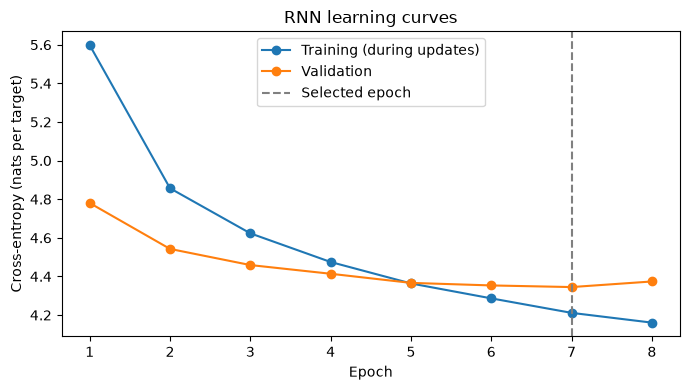

In [14]:
import matplotlib.pyplot as plt
rnn_metrics = {name: run_lm_epoch(rnn_model, rnn_run_loaders[name], DEVICE) for name in ('train', 'validation', 'test')}
for name, metrics in rnn_metrics.items():
    expected = sum((len(sequence) - 1 for sequence in encoded_paragraphs[name]))
    assert metrics['target_count'] == expected
assert math.isclose(rnn_metrics['validation']['cross_entropy'], rnn_training_record['best_validation_cross_entropy'], abs_tol=1e-05)
rnn_result = {**rnn_training_record, 'metrics': rnn_metrics}
(ARTIFACT_DIR / 'rnn_results.json').write_text(json.dumps(rnn_result, ensure_ascii=False, indent=2), encoding='utf-8')
print('Best-checkpoint results')
print('Split         Targets     CE (nats)       PPL')
for name, metrics in rnn_metrics.items():
    print(f"{name:<12} {metrics['target_count']:>8,} {metrics['cross_entropy']:>13.4f} {metrics['perplexity']:>9.2f}")
print(f"n-gram test PPL: {ngram_metrics['test']['perplexity']:.2f}")
epochs = [row['epoch'] for row in rnn_training_record['history']]
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(epochs, [row['train']['cross_entropy'] for row in rnn_training_record['history']], marker='o', label='Training (during updates)')
ax.plot(epochs, [row['validation']['cross_entropy'] for row in rnn_training_record['history']], marker='o', label='Validation')
ax.axvline(rnn_training_record['best_epoch'], linestyle='--', color='gray', label='Selected epoch')
ax.set(xlabel='Epoch', ylabel='Cross-entropy (nats per target)', title='RNN learning curves')
ax.legend()
fig.tight_layout()
fig.savefig(ARTIFACT_DIR / 'rnn_loss_curves.png', dpi=160)
plt.show()
plt.close(fig)


The selected checkpoint is epoch 7. Its test cross-entropy is 4.4222 and perplexity is 83.28, compared with 109.20 for the interpolated trigram. This supports better next-token prediction for this RNN configuration, while differences in context and training budget limit architectural conclusions. Validation cross-entropy rises from 4.3451 to 4.3740 in epoch 8 while training loss continues to decline, suggesting possible overfitting or optimization fluctuation. The learning curves do not establish full convergence. Inference timing and matched continuations are reported in the following sections.

### 1.4.4 Measure RNN Inference on the Shared Workload

Measure the same 128 prefixes, batch size, full-vocabulary scoring and repeats as n-gram. Recompute each history without recurrent caching. Report checkpoint size and median time; this measures teacher-forced scoring rather than generation throughput.

In [15]:
required_names = ('rnn_model', 'rnn_result', 'inference_workload', 'synchronize_device', 'DEVICE', 'ARTIFACT_DIR')
missing_names = [name for name in required_names if name not in globals()]
if missing_names:
    raise RuntimeError('Run sections 1.1.1 through 1.4.3 first, or restore the corresponding model and results. Missing: ' + ', '.join(missing_names))

def run_neural_inference_workload(model, workload, device):
    checksum = 0.0
    model.eval()
    with torch.inference_mode():
        for item in workload:
            inputs = torch.tensor([item['history']], dtype=torch.long, device=device)
            lengths = torch.tensor([inputs.size(1)], dtype=torch.long)
            logits = model(inputs, lengths)[:, -1, :]
            probabilities = torch.softmax(logits, dim=-1)
            checksum += float(probabilities[0, item['target']].item())
    return checksum
run_neural_inference_workload(rnn_model, inference_workload[:8], DEVICE)
rnn_inference_times = []
for _ in range(INFERENCE_REPEATS):
    synchronize_device(DEVICE)
    start = time.perf_counter()
    checksum = run_neural_inference_workload(rnn_model, inference_workload, DEVICE)
    synchronize_device(DEVICE)
    rnn_inference_times.append(time.perf_counter() - start)
    assert math.isfinite(checksum)
rnn_inference_median = statistics.median(rnn_inference_times)
rnn_result['inference'] = {'workload_targets': len(inference_workload), 'context_limit': INFERENCE_CONTEXT_LIMIT, 'batch_size': 1, 'output': 'Full vocabulary probability distribution', 'repeats': INFERENCE_REPEATS, 'seconds_per_repeat': rnn_inference_times, 'median_seconds': rnn_inference_median, 'predictions_per_second': len(inference_workload) / rnn_inference_median, 'includes_input_tensor_construction_and_device_transfer': True, 'recurrent_state': 'reset for every prefix; recompute the whole supplied history', 'cpu_threads': torch.get_num_threads()}
rnn_result['runtime_environment'] = {**runtime_environment, 'device': str(DEVICE), 'cpu_threads': torch.get_num_threads(), 'pytorch_version': str(torch.__version__)}
(ARTIFACT_DIR / 'rnn_results.json').write_text(json.dumps(rnn_result, ensure_ascii=False, indent=2), encoding='utf-8')
print('RNN inference seconds:', [round(value, 4) for value in rnn_inference_times])
print(f"RNN median: {rnn_inference_median:.4f}s; {rnn_result['inference']['predictions_per_second']:.2f} predictions/s")
print('Model            Test PPL     Storage MiB    Median inference s')
print(f"n-gram           {ngram_metrics['test']['perplexity']:>8.2f} {ngram_model_bytes / 1024 ** 2:>15.3f} {ngram_inference_median:>21.4f}")
print(f"RNN              {rnn_metrics['test']['perplexity']:>8.2f} {rnn_result['checkpoint_bytes'] / 1024 ** 2:>15.3f} {rnn_inference_median:>21.4f}")


RNN inference seconds: [0.0973, 0.0872, 0.0901]
RNN median: 0.0901s; 1420.48 predictions/s
Model            Test PPL     Storage MiB    Median inference s
n-gram             109.20           2.485                0.6702
RNN                 83.28           3.337                0.0901


### 1.4.5 Generate RNN Continuations for Comparison

Reuse the n-gram prompts, seeds and decoding settings. Generate in evaluation mode, recomputing the supplied history. Display unedited continuations and verify same-seed token IDs.

In [16]:
required_names = ('rnn_model', 'GENERATION_PROMPTS', 'sample_next_token', 'generation_config', 'ARTIFACT_DIR')
missing_names = [name for name in required_names if name not in globals()]
if missing_names:
    raise RuntimeError('Run the model and shared decoding setup first. Missing: ' + ', '.join(missing_names))

def generate_neural_text(model, prompt, seed, device):
    tokens = tokenize(prompt)
    history = [BOS_ID] + [token_to_id.get(token, UNK_ID) for token in tokens]
    rng = random.Random(seed)
    generated_ids = []
    model.eval()
    with torch.inference_mode():
        for _ in range(GENERATION_LENGTH):
            inputs = torch.tensor([history], dtype=torch.long, device=device)
            lengths = torch.tensor([len(history)], dtype=torch.long)
            logits = model(inputs, lengths)[0, -1]
            probabilities = torch.softmax(logits, dim=-1).cpu().tolist()
            next_id = sample_next_token(probabilities, rng, GENERATION_TEMPERATURE, GENERATION_TOP_K, GENERATION_BLOCKED_IDS)
            generated_ids.append(next_id)
            history.append(next_id)
    return generated_ids
rnn_generations = []
for index, prompt in enumerate(GENERATION_PROMPTS):
    seed = SEED + index
    ids = generate_neural_text(rnn_model, prompt, seed, DEVICE)
    assert len(ids) == GENERATION_LENGTH
    assert not any((token_id in GENERATION_BLOCKED_IDS for token_id in ids))
    tokens = [id_to_token[token_id] for token_id in ids]
    rnn_generations.append({'prompt': prompt, 'seed': seed, 'generated_ids': ids, 'generated_tokens': tokens, 'continuation': ' '.join(tokens)})
    print('n-gram:', ngram_generations[index]['continuation'])
    print('RNN:   ', ' '.join(tokens))
(ARTIFACT_DIR / 'rnn_generations.json').write_text(json.dumps({'config': generation_config, 'best_epoch': rnn_result['best_epoch'], 'samples': rnn_generations}, indent=2), encoding='utf-8')


n-gram: at the same time than any relations , with the , to be the other table , , who had and he had been concerned , and , indeed , my opinion , at her mother had <unk> brought on to be the meaning of her , and in a
RNN:    all in the course of <unk> on the whole party , and the <unk> of her uncle . but i think of his own ! " cried elizabeth . " how many things seem so very unlucky , who would not be to be in love with him . "


n-gram: , was a few of your time <unk> . the two the first dance , and had sent for the room . to . she , and , and what claims on you have been entirely so was so much better that in his letter which she " yes ,
RNN:    , for the whole party and aunt , and she continued it . i shall not . it is a most disagreeable old , " cried elizabeth , " this cannot be sorry to be glad to you to be the smallest appearance of <unk> ; and with my uncle


n-gram: to , who had been <unk> , and the to what you , i cannot help laughing that you are not be benefited by no was not , as that he was a very glad ; and , therefore , , " what sort of girl , but <unk> in
RNN:    have been at least to be in the habit of every moment , and i am sure she will be in the farm of this point . " and , i am glad to me in a moment of our being as she , as he had not all ,


On the fixed 128-prefix workload, the RNN takes a median 0.0884 seconds compared with 0.6773 seconds for this n-gram implementation. This is an implementation-level comparison: PyTorch tensor operations and Python vocabulary loops have different overheads. The RNN uses more storage and required about 112 seconds of training. Its continuation after she could not begins with have been rather than to followed by a comma, but other passages still contain repetition and incoherent expressions. These samples illustrate strengths and failures without establishing a general generation-quality ranking.

## 1.5 LSTM Experiments

### 1.5.1 Define the LSTM Language Model

Replace the RNN with one unidirectional LSTM layer. Retain embedding 100, hidden 128, dropout, full paragraphs, initialization seed and training protocol. Check causality and trainable inputs.

In [17]:
required_names = ('torch', 'VOCAB_SIZE', 'PAD_ID', 'RNN_CONFIG', 'reset_neural_seed')
missing_names = [name for name in required_names if name not in globals()]
if missing_names:
    raise RuntimeError('Run the shared setup and RNN configuration first. Missing: ' + ', '.join(missing_names))

class LSTMLanguageModel(torch.nn.Module):

    def __init__(self, vocab_size, embedding_dim=100, hidden_dim=128, dropout=0.2):
        super().__init__()
        self.embedding = torch.nn.Embedding(vocab_size, embedding_dim, padding_idx=PAD_ID)
        self.dropout = torch.nn.Dropout(dropout)
        self.lstm = torch.nn.LSTM(embedding_dim, hidden_dim, num_layers=1, batch_first=True)
        self.output = torch.nn.Linear(hidden_dim, vocab_size)

    def forward(self, inputs, lengths):
        embeddings = self.dropout(self.embedding(inputs))
        packed = torch.nn.utils.rnn.pack_padded_sequence(embeddings, lengths.cpu(), batch_first=True, enforce_sorted=False)
        packed_states, _ = self.lstm(packed)
        states, _ = torch.nn.utils.rnn.pad_packed_sequence(packed_states, batch_first=True, total_length=inputs.size(1))
        return self.output(self.dropout(states))
LSTM_CONFIG = {**RNN_CONFIG, 'architecture': 'single-layer unidirectional LSTM'}
torch.set_num_threads(LSTM_CONFIG['cpu_threads'])
reset_neural_seed(LSTM_CONFIG['seed'])
lstm_model = LSTMLanguageModel(VOCAB_SIZE, LSTM_CONFIG['embedding_dim'], LSTM_CONFIG['hidden_dim'], LSTM_CONFIG['dropout'])
lstm_model.eval()
check_inputs = torch.tensor([[BOS_ID, 4, 5, 6]], dtype=torch.long)
changed_inputs = check_inputs.clone()
changed_inputs[0, 3] = 7
with torch.no_grad():
    first_logits = lstm_model(check_inputs, torch.tensor([4]))
    changed_logits = lstm_model(changed_inputs, torch.tensor([4]))
assert torch.equal(first_logits[:, :3], changed_logits[:, :3])
assert lstm_model.embedding.weight.requires_grad
print('LSTM configuration:', LSTM_CONFIG)
print('LSTM parameters:', sum((parameter.numel() for parameter in lstm_model.parameters())))
print('RNN parameters:', rnn_result['total_parameters'])


LSTM configuration: {'architecture': 'single-layer unidirectional LSTM', 'embedding_dim': 100, 'hidden_dim': 128, 'dropout': 0.2, 'learning_rate': 0.003, 'batch_size': 8, 'max_epochs': 8, 'patience': 3, 'grad_clip': 1.0, 'seed': 42, 'context': 'complete paragraph', 'cpu_threads': 4}
LSTM parameters: 946740
RNN parameters: 858420


### 1.5.2 Train the LSTM and Select a Checkpoint

I use the same seed, fresh shuffle order, Adam learning rate, batch size, gradient clipping, eight-epoch maximum budget, and validation patience as the RNN. Only validation cross-entropy chooses the checkpoint. This is a matched epoch budget, not matched wall time or parameter count. To repeat from scratch, rerun the model definition before this training cell.

In [18]:
reset_neural_seed(LSTM_CONFIG['seed'])
lstm_run_loaders = make_lm_loaders(LSTM_CONFIG['seed'], LSTM_CONFIG['batch_size'])
lstm_model, lstm_training_record = train_language_model(lstm_model, 'lstm', LSTM_CONFIG, lstm_run_loaders, DEVICE)
print('Best LSTM epoch:', lstm_training_record['best_epoch'])
print(f"Total LSTM training wall time: {lstm_training_record['training_wall_seconds']:.2f}s")


Best LSTM epoch: 8
Total LSTM training wall time: 199.88s


### 1.5.3 Evaluate the LSTM and Compare Learning Curves

I restore the validation-selected LSTM and evaluate the same targets on all splits, then plot the RNN and LSTM training histories. Any prediction advantage will be interpreted alongside context, parameter count, and cost. Eight epochs may not fully train either model. LSTM inference timing and continuations are separate steps, so prediction scores alone do not complete the comparison.

LSTM selected-checkpoint metrics
train: targets=118401, CE=3.7827, PPL=43.93
validation: targets=14649, CE=4.2340, PPL=68.99
test: targets=14811, CE=4.3262, PPL=75.66
Test PPL comparison
n-gram: 109.20
RNN: 83.28
LSTM: 75.66


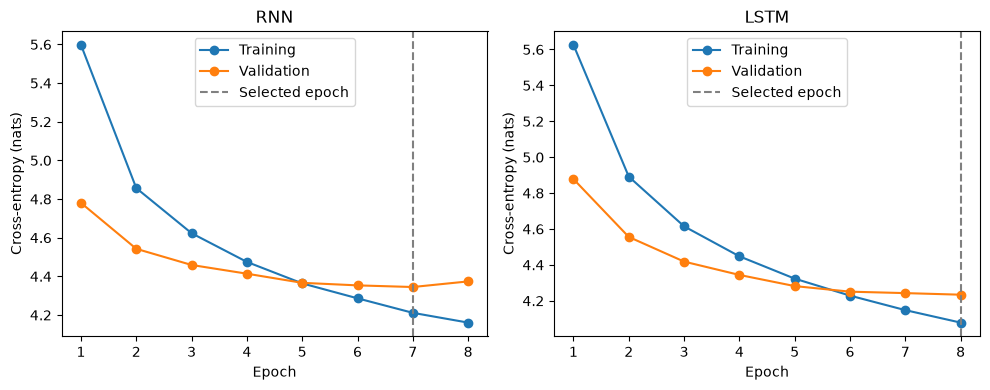

In [19]:
lstm_metrics = {name: run_lm_epoch(lstm_model, lstm_run_loaders[name], DEVICE) for name in ('train', 'validation', 'test')}
for name, metrics in lstm_metrics.items():
    assert metrics['target_count'] == sum((len(sequence) - 1 for sequence in encoded_paragraphs[name]))
assert math.isclose(lstm_metrics['validation']['cross_entropy'], lstm_training_record['best_validation_cross_entropy'], abs_tol=1e-05)
lstm_result = {**lstm_training_record, 'metrics': lstm_metrics}
(ARTIFACT_DIR / 'lstm_results.json').write_text(json.dumps(lstm_result, ensure_ascii=False, indent=2), encoding='utf-8')
print('LSTM selected-checkpoint metrics')
for name, metrics in lstm_metrics.items():
    print(f"{name}: targets={metrics['target_count']}, CE={metrics['cross_entropy']:.4f}, PPL={metrics['perplexity']:.2f}")
print('Test PPL comparison')
for name, metrics in (('n-gram', ngram_metrics), ('RNN', rnn_metrics), ('LSTM', lstm_metrics)):
    print(f"{name}: {metrics['test']['perplexity']:.2f}")
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, name, record in zip(axes, ('RNN', 'LSTM'), (rnn_training_record, lstm_training_record)):
    epochs = [row['epoch'] for row in record['history']]
    ax.plot(epochs, [row['train']['cross_entropy'] for row in record['history']], marker='o', label='Training')
    ax.plot(epochs, [row['validation']['cross_entropy'] for row in record['history']], marker='o', label='Validation')
    ax.axvline(record['best_epoch'], color='gray', linestyle='--', label='Selected epoch')
    ax.set(title=name, xlabel='Epoch', ylabel='Cross-entropy (nats)')
    ax.legend()
fig.tight_layout()
fig.savefig(ARTIFACT_DIR / 'rnn_lstm_loss_curves.png', dpi=160)
plt.show()
plt.close(fig)


The validation-selected LSTM is epoch 8, with test cross-entropy 4.3262 and perplexity 75.66, compared with 83.28 for the RNN and 109.20 for the trigram. LSTM training takes about 200 seconds rather than 112 seconds for the RNN and uses 946,740 rather than 858,420 parameters. Thus better prediction comes with additional cost, and the comparison does not isolate gating from parameter count. Validation loss is still decreasing at the final epoch, so this is the best checkpoint within the stated budget rather than evidence of full convergence.

### 1.5.4 Measure LSTM Inference on the Shared Workload

Restore the existing LSTM checkpoint and verify metadata. Time the saved 128-prefix workload with the common protocol. Earlier n-gram/RNN timings are reference measurements from different sessions.

In [20]:
required_names = ('LSTMLanguageModel', 'LSTM_CONFIG', 'run_neural_inference_workload', 'synchronize_device', 'DEVICE', 'ARTIFACT_DIR', 'id_to_token', 'corpus_sha256')
missing_names = [name for name in required_names if name not in globals()]
if missing_names:
    raise RuntimeError('Run data, shared setup, model definitions, and shared inference helpers first. Missing: ' + ', '.join(missing_names))
lstm_checkpoint = torch.load(ARTIFACT_DIR / 'lstm_best.pt', map_location=DEVICE, weights_only=True)
assert lstm_checkpoint['id_to_token'] == id_to_token
assert lstm_checkpoint['corpus_sha256'] == corpus_sha256
assert lstm_checkpoint['config'] == LSTM_CONFIG
lstm_result = json.loads((ARTIFACT_DIR / 'lstm_results.json').read_text(encoding='utf-8'))
assert lstm_checkpoint['epoch'] == lstm_result['best_epoch']
lstm_model = LSTMLanguageModel(VOCAB_SIZE, LSTM_CONFIG['embedding_dim'], LSTM_CONFIG['hidden_dim'], LSTM_CONFIG['dropout'])
lstm_model.load_state_dict(lstm_checkpoint['state_dict'])
lstm_model.to(DEVICE).eval()
torch.set_num_threads(LSTM_CONFIG['cpu_threads'])
saved_workload = json.loads((ARTIFACT_DIR / 'inference_workload.json').read_text(encoding='utf-8'))
assert saved_workload['corpus_sha256'] == corpus_sha256
inference_workload = saved_workload['items']
expected_workload = []
for sequence in encoded_paragraphs['test']:
    for position in range(1, len(sequence)):
        expected_workload.append({'history': sequence[max(0, position - 32):position], 'target': sequence[position]})
        if len(expected_workload) == 128:
            break
    if len(expected_workload) == 128:
        break
assert inference_workload == expected_workload
run_neural_inference_workload(lstm_model, inference_workload[:8], DEVICE)
lstm_inference_times = []
lstm_inference_checksums = []
for _ in range(3):
    synchronize_device(DEVICE)
    start = time.perf_counter()
    checksum = run_neural_inference_workload(lstm_model, inference_workload, DEVICE)
    synchronize_device(DEVICE)
    lstm_inference_times.append(time.perf_counter() - start)
    assert math.isfinite(checksum)
    lstm_inference_checksums.append(checksum)
assert len(set(lstm_inference_checksums)) == 1
lstm_inference_median = statistics.median(lstm_inference_times)
lstm_result['inference'] = {'workload_targets': 128, 'context_limit': 32, 'batch_size': 1, 'output': 'Full vocabulary probability distribution', 'warmup_targets': 8, 'repeats': 3, 'seconds_per_repeat': lstm_inference_times, 'median_seconds': lstm_inference_median, 'predictions_per_second': 128 / lstm_inference_median, 'includes_input_tensor_construction_and_device_transfer': True, 'recurrent_state': 'hidden and cell states reset for every prefix; recompute the whole supplied history', 'cpu_threads': torch.get_num_threads(), 'checksums': lstm_inference_checksums, 'workload_file': 'inference_workload.json'}
lstm_result['runtime_environment'] = {'platform': platform.platform(), 'processor': platform.processor() or 'Not reported', 'logical_cpu_count': __import__('os').cpu_count(), 'python_version': sys.version, 'device': str(DEVICE), 'cpu_threads': torch.get_num_threads(), 'pytorch_version': str(torch.__version__)}
(ARTIFACT_DIR / 'lstm_results.json').write_text(json.dumps(lstm_result, indent=2), encoding='utf-8')
print(f"Restored LSTM epoch {lstm_checkpoint['epoch']} without training.")
print('LSTM inference seconds:', [round(value, 4) for value in lstm_inference_times])
print(f'LSTM median: {lstm_inference_median:.4f}s; {128 / lstm_inference_median:.2f} predictions/s')
print('Model      Test PPL    Storage MiB    Median inference s')
for name, filename, size_key in (('n-gram', 'ngram_results.json', 'serialized_model_bytes'), ('RNN', 'rnn_results.json', 'checkpoint_bytes'), ('LSTM', 'lstm_results.json', 'checkpoint_bytes')):
    result = json.loads((ARTIFACT_DIR / filename).read_text(encoding='utf-8'))
    print(f"{name:<10} {result['metrics']['test']['perplexity']:>8.2f} {result[size_key] / 1024 ** 2:>14.3f} {result['inference']['median_seconds']:>21.4f}")
print('n-gram and RNN timings are saved reference runs; only LSTM was timed in this execution.')


Restored LSTM epoch 8 without training.
LSTM inference seconds: [0.0915, 0.0713, 0.0878]
LSTM median: 0.0878s; 1458.27 predictions/s
Model      Test PPL    Storage MiB    Median inference s
n-gram       109.20          2.485                0.6702
RNN           83.28          3.337                0.0901
LSTM          75.66          3.673                0.0878
n-gram and RNN timings are saved reference runs; only LSTM was timed in this execution.


### 1.5.5 Generate LSTM Continuations for Comparison

Restore the LSTM and reuse all shared prompts, seeds and decoding settings. Save three unedited 50-token continuations and verify repeatability; compare them with n-gram/RNN samples.

In [21]:
required_names = ('lstm_model', 'lstm_result', 'generate_neural_text', 'sample_next_token', 'ARTIFACT_DIR')
missing_names = [name for name in required_names if name not in globals()]
if missing_names:
    raise RuntimeError('Run section 1.5.4 and the shared generation helpers first. Missing: ' + ', '.join(missing_names))
generation_config = json.loads((ARTIFACT_DIR / 'generation_config.json').read_text(encoding='utf-8'))
assert generation_config['vocabulary_size'] == VOCAB_SIZE
GENERATION_PROMPTS = generation_config['prompts']
GENERATION_LENGTH = generation_config['length']
GENERATION_TEMPERATURE = generation_config['temperature']
GENERATION_TOP_K = generation_config['top_k']
GENERATION_BLOCKED_IDS = tuple(generation_config['blocked_token_ids'])
assert generation_config['blocked_tokens'] == [id_to_token[i] for i in GENERATION_BLOCKED_IDS]
assert not generation_config['stop_at_eos']
comparison_samples = {}
for name, filename in (('n-gram', 'ngram_generations.json'), ('RNN', 'rnn_generations.json')):
    saved = json.loads((ARTIFACT_DIR / filename).read_text(encoding='utf-8'))
    assert saved['config'] == generation_config
    comparison_samples[name] = saved['samples']
lstm_generations = []
for index, (prompt, seed) in enumerate(zip(GENERATION_PROMPTS, generation_config['seeds'], strict=True)):
    ids = generate_neural_text(lstm_model, prompt, seed, DEVICE)
    assert len(ids) == GENERATION_LENGTH
    assert not any((token_id in GENERATION_BLOCKED_IDS for token_id in ids))
    tokens = [id_to_token[token_id] for token_id in ids]
    lstm_generations.append({'prompt': prompt, 'seed': seed, 'generated_ids': ids, 'generated_tokens': tokens, 'continuation': ' '.join(tokens)})
    for name, samples in comparison_samples.items():
        assert samples[index]['prompt'] == prompt and samples[index]['seed'] == seed
        print(name + ':', samples[index]['continuation'])
    print('LSTM:', ' '.join(tokens))
(ARTIFACT_DIR / 'lstm_generations.json').write_text(json.dumps({'config': generation_config, 'best_epoch': lstm_result['best_epoch'], 'samples': lstm_generations}, indent=2), encoding='utf-8')


n-gram: at the same time than any relations , with the , to be the other table , , who had and he had been concerned , and , indeed , my opinion , at her mother had <unk> brought on to be the meaning of her , and in a
RNN: all in the course of <unk> on the whole party , and the <unk> of her uncle . but i think of his own ! " cried elizabeth . " how many things seem so very unlucky , who would not be to be in love with him . "
LSTM: pleased to the subject . elizabeth to be the <unk> of his own , that the whole party have been seen to her . jane was not a circumstance in short ; and and , though jane was scarcely seen the <unk> of the <unk> , and , had been


n-gram: , was a few of your time <unk> . the two the first dance , and had sent for the room . to . she , and , and what claims on you have been entirely so was so much better that in his letter which she " yes ,
RNN: , for the whole party and aunt , and she continued it . i shall not . it is a most disagreeable old , " cried elizabeth , " this cannot be sorry to be glad to you to be the smallest appearance of <unk> ; and with my uncle
LSTM: . he was very strange - - - - shire . there was impossible to be expected ; and , that it would be so ready to be in every power of that part of its contents than it was , it is not <unk> her . and miss bingley


n-gram: to , who had been <unk> , and the to what you , i cannot help laughing that you are not be benefited by no was not , as that he was a very glad ; and , therefore , , " what sort of girl , but <unk> in
RNN: have been at least to be in the habit of every moment , and i am sure she will be in the farm of this point . " and , i am glad to me in a moment of our being as she , as he had not all ,
LSTM: help repeating for the other , and the <unk> of others was the country ; and , at home , and the housekeeper , he listened to see him - - and mrs . collins ; and , when her thoughts were placed by her niece , she might be


LSTM scores 75.66 test PPL and 0.0870 s on the prefix workload. Its continuations still contain “pleased to the subject”, “and and” and inconsistent references. Lower PPL does not guarantee a better individual passage; three prompts and timings across sessions do not establish universal quality or speed rankings.

## 1.6 Transformer Experiments

### 1.6.1 Define and Verify the Causal Transformer

Use one pre-LN causal Transformer block: trainable embedding 100 projected to 128, four heads, FFN 256, sinusoidal positions and dropout 0.2 outside attention. Right padding plus causal attention protects valid positions; padded outputs are masked. Check causality, gradients and the longest paragraph without optimizer updates. Full-paragraph attention has quadratic cost.

In [22]:
required_names = ('torch', 'F', 'VOCAB_SIZE', 'PAD_ID', 'RNN_CONFIG', 'reset_neural_seed', 'encoded_paragraphs', 'collate_lm_batch', 'lm_datasets', 'summed_token_nll', 'ARTIFACT_DIR', 'corpus_sha256')
missing_names = [name for name in required_names if name not in globals()]
if missing_names:
    raise RuntimeError('Run data preparation and shared neural setup first, with RNN_CONFIG available. Missing: ' + ', '.join(missing_names))

class CausalTransformerBlock(torch.nn.Module):

    def __init__(self, model_dim, num_heads, feedforward_dim, dropout):
        super().__init__()
        if model_dim % num_heads:
            raise ValueError('Model dimension must be divisible by the number of heads.')
        self.num_heads = num_heads
        self.head_dim = model_dim // num_heads
        self.attention_norm = torch.nn.LayerNorm(model_dim)
        self.qkv = torch.nn.Linear(model_dim, 3 * model_dim)
        self.attention_output = torch.nn.Linear(model_dim, model_dim)
        self.feedforward_norm = torch.nn.LayerNorm(model_dim)
        self.feedforward = torch.nn.Sequential(torch.nn.Linear(model_dim, feedforward_dim), torch.nn.GELU(), torch.nn.Dropout(dropout), torch.nn.Linear(feedforward_dim, model_dim))
        self.residual_dropout = torch.nn.Dropout(dropout)

    def forward(self, states):
        batch_size, length, model_dim = states.shape
        qkv = self.qkv(self.attention_norm(states)).reshape(batch_size, length, 3, self.num_heads, self.head_dim).permute(2, 0, 3, 1, 4)
        query, key, value = qkv.unbind(dim=0)
        attended = F.scaled_dot_product_attention(query, key, value, dropout_p=0.0, is_causal=True)
        attended = attended.transpose(1, 2).reshape(batch_size, length, model_dim)
        states = states + self.residual_dropout(self.attention_output(attended))
        return states + self.residual_dropout(self.feedforward(self.feedforward_norm(states)))

class TransformerLanguageModel(torch.nn.Module):

    def __init__(self, vocab_size, embedding_dim=100, model_dim=128, num_heads=4, feedforward_dim=256, num_layers=1, dropout=0.2):
        super().__init__()
        if model_dim % 2:
            raise ValueError('Sinusoidal position encoding requires an even model dimension here.')
        self.model_dim = model_dim
        self.embedding = torch.nn.Embedding(vocab_size, embedding_dim, padding_idx=PAD_ID)
        self.input_projection = torch.nn.Linear(embedding_dim, model_dim)
        self.embedding_dropout = torch.nn.Dropout(dropout)
        self.blocks = torch.nn.ModuleList([CausalTransformerBlock(model_dim, num_heads, feedforward_dim, dropout) for _ in range(num_layers)])
        self.final_norm = torch.nn.LayerNorm(model_dim)
        self.output = torch.nn.Linear(model_dim, vocab_size)

    def position_encoding(self, length, device, dtype):
        positions = torch.arange(length, device=device, dtype=torch.float32).unsqueeze(1)
        frequencies = torch.exp(torch.arange(0, self.model_dim, 2, device=device, dtype=torch.float32) * (-math.log(10000.0) / self.model_dim))
        encoding = torch.empty(length, self.model_dim, device=device, dtype=torch.float32)
        encoding[:, 0::2] = torch.sin(positions * frequencies)
        encoding[:, 1::2] = torch.cos(positions * frequencies)
        return encoding.to(dtype=dtype)

    def forward(self, inputs, lengths):
        if inputs.ndim != 2 or lengths.ndim != 1 or len(lengths) != inputs.size(0):
            raise ValueError('Expected inputs [batch, length] and one length per sequence.')
        if bool((lengths < 1).any()) or bool((lengths > inputs.size(1)).any()):
            raise ValueError('Lengths must describe nonempty sequences within the padded input.')
        states = self.input_projection(self.embedding_dropout(self.embedding(inputs)))
        states = states + self.position_encoding(inputs.size(1), inputs.device, states.dtype)
        for block in self.blocks:
            states = block(states)
        logits = self.output(self.final_norm(states))
        valid = torch.arange(inputs.size(1), device=inputs.device)[None, :] < lengths.to(inputs.device)[:, None]
        return logits.masked_fill(~valid[:, :, None], 0.0)
TRANSFORMER_CONFIG = {**RNN_CONFIG, 'architecture': 'single-layer causal Transformer with pre-normalization', 'model_dim': 128, 'num_heads': 4, 'feedforward_dim': 256, 'num_layers': 1, 'position_encoding': 'sinusoidal; paragraph positions start at zero', 'attention_dropout': 0.0, 'context': 'complete paragraph; no truncation', 'attention_backend': 'PyTorch scaled_dot_product_attention with is_causal=True'}
TRANSFORMER_CONFIG.pop('hidden_dim')
torch.set_num_threads(TRANSFORMER_CONFIG['cpu_threads'])
reset_neural_seed(TRANSFORMER_CONFIG['seed'])
transformer_model = TransformerLanguageModel(VOCAB_SIZE, TRANSFORMER_CONFIG['embedding_dim'], TRANSFORMER_CONFIG['model_dim'], TRANSFORMER_CONFIG['num_heads'], TRANSFORMER_CONFIG['feedforward_dim'], TRANSFORMER_CONFIG['num_layers'], TRANSFORMER_CONFIG['dropout']).to(DEVICE)
transformer_model.eval()
assert transformer_model.embedding.weight.requires_grad
check_inputs = torch.tensor([[BOS_ID, 4, 5, 6], [BOS_ID, 7, PAD_ID, PAD_ID]], device=DEVICE)
check_lengths = torch.tensor([4, 2])
changed_inputs = check_inputs.clone()
changed_inputs[0, 3] = 8
changed_inputs[1, 2:] = 9
with torch.inference_mode():
    first_logits = transformer_model(check_inputs, check_lengths)
    changed_logits = transformer_model(changed_inputs, check_lengths)
    alone_logits = transformer_model(check_inputs[1:2, :2], torch.tensor([2]))
assert first_logits.shape == (2, 4, VOCAB_SIZE)
assert torch.allclose(first_logits[0, :3], changed_logits[0, :3], atol=1e-06, rtol=1e-05)
assert torch.allclose(first_logits[1, :2], changed_logits[1, :2], atol=1e-06, rtol=1e-05)
assert torch.allclose(first_logits[1, :2], alone_logits[0], atol=1e-06, rtol=1e-05)
assert torch.count_nonzero(first_logits[1, 2:]) == 0
longest_index = max(range(len(lm_datasets['train'])), key=lambda i: len(encoded_paragraphs['train'][i]))
long_batch = collate_lm_batch([lm_datasets['train'][longest_index]])
parameters_before = {name: parameter.detach().clone() for name, parameter in transformer_model.named_parameters()}
transformer_model.train()
probe_start = time.perf_counter()
long_logits = transformer_model(long_batch['inputs'].to(DEVICE), long_batch['lengths'])
probe_nll, probe_count = summed_token_nll(long_logits, long_batch['targets'].to(DEVICE))
(probe_nll / probe_count).backward()
synchronize_device(DEVICE)
probe_seconds = time.perf_counter() - probe_start
assert probe_count == len(encoded_paragraphs['train'][longest_index]) - 1
assert torch.isfinite(probe_nll)
assert all((parameter.grad is not None and torch.isfinite(parameter.grad).all() for parameter in transformer_model.parameters()))
assert float(transformer_model.embedding.weight.grad.abs().sum()) > 0
assert all((torch.equal(parameter, parameters_before[name]) for name, parameter in transformer_model.named_parameters()))
transformer_model.zero_grad(set_to_none=True)
transformer_model.eval()
del long_logits, probe_nll, parameters_before
maximum_length = probe_count
dense_scores_mib = TRANSFORMER_CONFIG['batch_size'] * TRANSFORMER_CONFIG['num_heads'] * maximum_length ** 2 * 4 / 1024 ** 2
output_logits_mib = TRANSFORMER_CONFIG['batch_size'] * maximum_length * VOCAB_SIZE * 4 / 1024 ** 2
transformer_setup = {'config': TRANSFORMER_CONFIG, 'corpus_sha256': corpus_sha256, 'total_parameters': sum((parameter.numel() for parameter in transformer_model.parameters())), 'trainable_parameters': sum((parameter.numel() for parameter in transformer_model.parameters() if parameter.requires_grad)), 'checks': {'causality': True, 'right_padding_invariance': True, 'standalone_vs_batched': True, 'trainable_embedding_gradient': True, 'longest_paragraph_forward_backward': True, 'parameters_unchanged': True}, 'longest_training_targets': maximum_length, 'probe_batch_size': 1, 'probe_forward_backward_seconds': probe_seconds, 'hypothetical_dense_attention_scores_mib_at_batch_size_8': dense_scores_mib, 'output_logits_mib_at_batch_size_8': output_logits_mib, 'planned_training_batch_size': TRANSFORMER_CONFIG['batch_size'], 'batch_size_8_training_feasibility': 'not yet measured; verify before the training run', 'device': str(DEVICE), 'pytorch_version': str(torch.__version__), 'status': 'definition and checks only; no optimizer steps, checkpoint, or trained metrics'}
(ARTIFACT_DIR / 'transformer_setup.json').write_text(json.dumps(transformer_setup, indent=2), encoding='utf-8')
print('Transformer configuration:', TRANSFORMER_CONFIG)
print('Parameters:', transformer_setup['total_parameters'])
print(f'Longest training paragraph: {probe_count} targets; forward/backward probe (batch 1): {probe_seconds:.3f}s')
print(f'Hypothetical dense attention scores at batch 8: {dense_scores_mib:.1f} MiB')
print(f'Output logits alone at batch 8 and maximum length: {output_logits_mib:.1f} MiB')


Transformer configuration: {'architecture': 'single-layer causal Transformer with pre-normalization', 'embedding_dim': 100, 'dropout': 0.2, 'learning_rate': 0.003, 'batch_size': 8, 'max_epochs': 8, 'patience': 3, 'grad_clip': 1.0, 'seed': 42, 'context': 'complete paragraph; no truncation', 'cpu_threads': 4, 'model_dim': 128, 'num_heads': 4, 'feedforward_dim': 256, 'num_layers': 1, 'position_encoding': 'sinusoidal; paragraph positions start at zero', 'attention_dropout': 0.0, 'attention_backend': 'PyTorch scaled_dot_product_attention with is_causal=True'}
Parameters: 974644
Longest training paragraph: 2824 targets; forward/backward probe (batch 1): 0.141s
Hypothetical dense attention scores at batch 8: 973.5 MiB
Output logits alone at batch 8 and maximum length: 312.0 MiB


The untrained Transformer has 974,644 trainable parameters. Causality, right-padding invariance, and standalone/batched equivalence checks passed. The complete longest training paragraph (2,824 targets) completed a batch-one forward/backward probe in 0.213 seconds with finite gradients and unchanged parameters.

This verifies the implementation, not prediction quality or batch-eight training feasibility. Theoretical maximum-length output logits at batch eight occupy 312.0 MiB; a hypothetical dense four-head attention-score tensor would occupy 973.5 MiB. These are tensor-size estimates, not measured peak process memory. Check the actual long-paragraph batches before section 1.6.2 training.

### 1.6.2 Train the Transformer and Select a Checkpoint

Probe the eight longest training paragraphs at the planned batch size eight, without optimizer updates. Then recreate the seeded model and fresh loaders. Reuse Adam, learning rate 0.003, gradient clipping 1.0, at most eight epochs, and validation patience three. Preserve complete paragraphs and every target; only validation CE selects the checkpoint. Resetting initialization here makes this cell a fresh training run. The resource probe is excluded from recorded training wall time.

In [23]:
required_names = ('TransformerLanguageModel', 'TRANSFORMER_CONFIG', 'make_lm_loaders', 'train_language_model')
missing_names = [name for name in required_names if name not in globals()]
if missing_names:
    raise RuntimeError('Run section 1.6.1 and shared setup first. Missing: ' + ', '.join(missing_names))
probe_indices = sorted(range(len(lm_datasets['train'])), key=lambda i: len(encoded_paragraphs['train'][i]), reverse=True)[:8]
probe_batch = collate_lm_batch([lm_datasets['train'][i] for i in probe_indices])
transformer_model.train()
transformer_model.zero_grad(set_to_none=True)
probe_start = time.perf_counter()
probe_logits = transformer_model(probe_batch['inputs'].to(DEVICE), probe_batch['lengths'])
probe_nll, probe_count = summed_token_nll(probe_logits, probe_batch['targets'].to(DEVICE))
(probe_nll / probe_count).backward()
synchronize_device(DEVICE)
assert torch.isfinite(probe_nll)
assert all((p.grad is not None and torch.isfinite(p.grad).all() for p in transformer_model.parameters()))
transformer_resource_probe = {'batch_size': len(probe_indices), 'padded_length': int(probe_batch['inputs'].size(1)), 'valid_targets': probe_count, 'seconds': time.perf_counter() - probe_start, 'finite_loss_and_gradients': True, 'optimizer_steps': 0, 'scope': 'eight longest training paragraphs; maximum padded shape; not measured peak memory'}
(ARTIFACT_DIR / 'transformer_resource_probe.json').write_text(json.dumps(transformer_resource_probe, indent=2), encoding='utf-8')
transformer_model.zero_grad(set_to_none=True)
del probe_logits, probe_nll, probe_batch
reset_neural_seed(TRANSFORMER_CONFIG['seed'])
transformer_model = TransformerLanguageModel(VOCAB_SIZE, TRANSFORMER_CONFIG['embedding_dim'], TRANSFORMER_CONFIG['model_dim'], TRANSFORMER_CONFIG['num_heads'], TRANSFORMER_CONFIG['feedforward_dim'], TRANSFORMER_CONFIG['num_layers'], TRANSFORMER_CONFIG['dropout']).to(DEVICE)
reset_neural_seed(TRANSFORMER_CONFIG['seed'])
transformer_run_loaders = make_lm_loaders(TRANSFORMER_CONFIG['seed'], TRANSFORMER_CONFIG['batch_size'])
transformer_model, transformer_training_record = train_language_model(transformer_model, 'transformer', TRANSFORMER_CONFIG, transformer_run_loaders, DEVICE)
for row in transformer_training_record['history']:
    for split in ('train', 'validation'):
        assert row[split]['target_count'] == sum((len(s) - 1 for s in encoded_paragraphs[split]))
print('Best Transformer epoch:', transformer_training_record['best_epoch'])
print(f"Training wall time: {transformer_training_record['training_wall_seconds']:.2f}s")


Best Transformer epoch: 6
Training wall time: 172.20s


### 1.6.3 Evaluate the Transformer and Compare Learning Curves

Reload and verify the validation-selected checkpoint, evaluate all three splits with token-weighted loss excluding padding, and check target counts and validation CE. Plot all three neural histories. Online training CE includes dropout and changing parameters; fixed-checkpoint training CE is a different measurement. Preserve previous baseline results and do not tune after looking at test scores.

Transformer selected-checkpoint metrics
train: targets=118401, CE=3.7897, PPL=44.24
validation: targets=14649, CE=4.4564, PPL=86.18
test: targets=14811, CE=4.5679, PPL=96.34


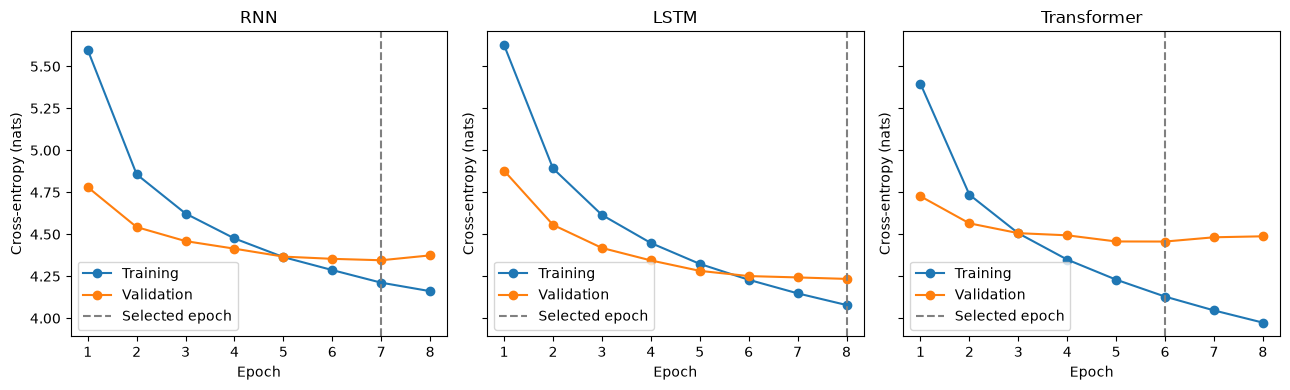

In [24]:
import matplotlib.pyplot as plt
checkpoint = torch.load(ARTIFACT_DIR / 'transformer_best.pt', map_location=DEVICE, weights_only=True)
assert checkpoint['config'] == TRANSFORMER_CONFIG
assert checkpoint['id_to_token'] == id_to_token
assert checkpoint['corpus_sha256'] == corpus_sha256
transformer_model.load_state_dict(checkpoint['state_dict'])
transformer_model.to(DEVICE).eval()
transformer_metrics = {name: run_lm_epoch(transformer_model, transformer_run_loaders[name], DEVICE) for name in ('train', 'validation', 'test')}
for name, metrics in transformer_metrics.items():
    assert metrics['target_count'] == sum((len(s) - 1 for s in encoded_paragraphs[name]))
assert math.isclose(transformer_metrics['validation']['cross_entropy'], checkpoint['validation_cross_entropy'], abs_tol=1e-05)
transformer_result = {**transformer_training_record, 'metrics': transformer_metrics, 'resource_probe': json.loads((ARTIFACT_DIR / 'transformer_resource_probe.json').read_text(encoding='utf-8'))}
(ARTIFACT_DIR / 'transformer_results.json').write_text(json.dumps(transformer_result, indent=2), encoding='utf-8')
print('Transformer selected-checkpoint metrics')
for name, metrics in transformer_metrics.items():
    print(f"{name}: targets={metrics['target_count']}, CE={metrics['cross_entropy']:.4f}, PPL={metrics['perplexity']:.2f}")
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for ax, name, filename in zip(axes, ('RNN', 'LSTM', 'Transformer'), ('rnn_training.json', 'lstm_training.json', 'transformer_training.json')):
    record = json.loads((ARTIFACT_DIR / filename).read_text(encoding='utf-8'))
    epochs = [row['epoch'] for row in record['history']]
    ax.plot(epochs, [row['train']['cross_entropy'] for row in record['history']], marker='o', label='Training')
    ax.plot(epochs, [row['validation']['cross_entropy'] for row in record['history']], marker='o', label='Validation')
    ax.axvline(record['best_epoch'], linestyle='--', color='gray', label='Selected epoch')
    ax.set(title=name, xlabel='Epoch', ylabel='Cross-entropy (nats)')
    ax.legend()
fig.tight_layout()
fig.savefig(ARTIFACT_DIR / 'part1_neural_loss_curves.png', dpi=160)
plt.show()
plt.close(fig)


### 1.6.4 Measure Transformer Inference on the Shared Workload

Reuse the same 128 saved test prefixes, with at most 32 history tokens, batch size one, and a full-vocabulary distribution. Warm up eight prefixes and take the median of three synchronized measurements. Include tensor construction, device transfer, and probability extraction. Recompute each prefix with positions starting at zero and no KV cache. This workload is separate from full-paragraph evaluation and generated-text throughput.

In [25]:
import os
required_names = ('transformer_model', 'transformer_result', 'run_neural_inference_workload')
missing_names = [name for name in required_names if name not in globals()]
if missing_names:
    raise RuntimeError('Run Transformer evaluation and shared inference helper first. Missing: ' + ', '.join(missing_names))
saved_workload = json.loads((ARTIFACT_DIR / 'inference_workload.json').read_text(encoding='utf-8'))
assert saved_workload['corpus_sha256'] == corpus_sha256
inference_workload = saved_workload['items']
expected_workload = []
for sequence in encoded_paragraphs['test']:
    for position in range(1, len(sequence)):
        expected_workload.append({'history': sequence[max(0, position - 32):position], 'target': sequence[position]})
        if len(expected_workload) == 128:
            break
    if len(expected_workload) == 128:
        break
assert inference_workload == expected_workload
run_neural_inference_workload(transformer_model, inference_workload[:8], DEVICE)
transformer_inference_times = []
checksums = []
for _ in range(3):
    synchronize_device(DEVICE)
    start = time.perf_counter()
    checksum = run_neural_inference_workload(transformer_model, inference_workload, DEVICE)
    synchronize_device(DEVICE)
    transformer_inference_times.append(time.perf_counter() - start)
    assert math.isfinite(checksum)
    checksums.append(checksum)
assert len(set(checksums)) == 1
transformer_inference_median = statistics.median(transformer_inference_times)
transformer_result['inference'] = {'workload_targets': 128, 'context_limit': 32, 'batch_size': 1, 'warmup_targets': 8, 'output': 'Full vocabulary probability distribution', 'repeats': 3, 'seconds_per_repeat': transformer_inference_times, 'median_seconds': transformer_inference_median, 'predictions_per_second': 128 / transformer_inference_median, 'checksums': checksums, 'includes_input_tensor_construction_and_device_transfer': True, 'context_handling': 'recompute each supplied prefix; positions start at zero; no KV cache', 'cpu_threads': torch.get_num_threads(), 'workload_file': 'inference_workload.json'}
transformer_result['runtime_environment'] = {'platform': platform.platform(), 'processor': platform.processor() or 'Not reported', 'logical_cpu_count': os.cpu_count(), 'python_version': sys.version, 'device': str(DEVICE), 'cpu_threads': torch.get_num_threads(), 'pytorch_version': str(torch.__version__)}
(ARTIFACT_DIR / 'transformer_results.json').write_text(json.dumps(transformer_result, indent=2), encoding='utf-8')
print('Transformer inference seconds:', [round(v, 4) for v in transformer_inference_times])
print(f'Median: {transformer_inference_median:.4f}s; {128 / transformer_inference_median:.2f} predictions/s')
print('Teacher-forced prefix timing, not generation throughput; checkpoint loading excluded.')


Transformer inference seconds: [0.0878, 0.0951, 0.0873]
Median: 0.0878s; 1457.66 predictions/s
Teacher-forced prefix timing, not generation throughput; checkpoint loading excluded.


### 1.6.5 Generate Transformer Continuations for Comparison

Load the same prompts, 50-token length, temperature 0.8, top-k 50, seeds, and blocked tokens from generation_config.json. Reuse the shared sampler in evaluation mode, recomputing the complete generated history. Display all four unedited model outputs and save IDs, tokens, and text. Verify all three samples reproduce the same IDs with the same seeds. Specific samples illustrate repetition, local fluency, and consistency; they do not establish a universal quality ranking.

In [26]:
generation_config = json.loads((ARTIFACT_DIR / 'generation_config.json').read_text(encoding='utf-8'))
assert generation_config['vocabulary_size'] == VOCAB_SIZE
GENERATION_PROMPTS = generation_config['prompts']
GENERATION_LENGTH = generation_config['length']
GENERATION_TEMPERATURE = generation_config['temperature']
GENERATION_TOP_K = generation_config['top_k']
GENERATION_BLOCKED_IDS = tuple(generation_config['blocked_token_ids'])
assert generation_config['blocked_tokens'] == [id_to_token[i] for i in GENERATION_BLOCKED_IDS]
assert not generation_config['stop_at_eos']
baseline_samples = {}
for name, filename in (('n-gram', 'ngram_generations.json'), ('RNN', 'rnn_generations.json'), ('LSTM', 'lstm_generations.json')):
    saved = json.loads((ARTIFACT_DIR / filename).read_text(encoding='utf-8'))
    assert saved['config'] == generation_config
    baseline_samples[name] = saved['samples']
transformer_generations = []
for index, (prompt, seed) in enumerate(zip(GENERATION_PROMPTS, generation_config['seeds'], strict=True)):
    ids = generate_neural_text(transformer_model, prompt, seed, DEVICE)
    assert len(ids) == GENERATION_LENGTH
    assert not any((i in GENERATION_BLOCKED_IDS for i in ids))
    tokens = [id_to_token[i] for i in ids]
    transformer_generations.append({'prompt': prompt, 'seed': seed, 'generated_ids': ids, 'generated_tokens': tokens, 'continuation': ' '.join(tokens)})
    for name, samples in baseline_samples.items():
        assert samples[index]['prompt'] == prompt and samples[index]['seed'] == seed
        print(name + ':', samples[index]['continuation'])
    print('Transformer:', ' '.join(tokens))
(ARTIFACT_DIR / 'transformer_generations.json').write_text(json.dumps({'config': generation_config, 'best_epoch': transformer_result['best_epoch'], 'samples': transformer_generations}, indent=2), encoding='utf-8')
for sample in transformer_generations:
    assert sample['generated_ids'] == generate_neural_text(transformer_model, sample['prompt'], sample['seed'], DEVICE)


n-gram: at the same time than any relations , with the , to be the other table , , who had and he had been concerned , and , indeed , my opinion , at her mother had <unk> brought on to be the meaning of her , and in a
RNN: all in the course of <unk> on the whole party , and the <unk> of her uncle . but i think of his own ! " cried elizabeth . " how many things seem so very unlucky , who would not be to be in love with him . "
LSTM: pleased to the subject . elizabeth to be the <unk> of his own , that the whole party have been seen to her . jane was not a circumstance in short ; and and , though jane was scarcely seen the <unk> of the <unk> , and , had been
Transformer: convinced that she had the former in the subject of the evening , and had been a family of the lodges of the <unk> on the <unk> of having just over it was gratifying as they might be expected ; and the carriage drove to be able to make the


n-gram: , was a few of your time <unk> . the two the first dance , and had sent for the room . to . she , and , and what claims on you have been entirely so was so much better that in his letter which she " yes ,
RNN: , for the whole party and aunt , and she continued it . i shall not . it is a most disagreeable old , " cried elizabeth , " this cannot be sorry to be glad to you to be the smallest appearance of <unk> ; and with my uncle
LSTM: . he was very strange - - - - shire . there was impossible to be expected ; and , that it would be so ready to be in every power of that part of its contents than it was , it is not <unk> her . and miss bingley
Transformer: smiled ; and , when jane was impossible to the house of her brother , and a wife , and she was convinced her for her to her sister she began to say , and a subject by a <unk> . but when she had the whole room in the


n-gram: to , who had been <unk> , and the to what you , i cannot help laughing that you are not be benefited by no was not , as that he was a very glad ; and , therefore , , " what sort of girl , but <unk> in
RNN: have been at least to be in the habit of every moment , and i am sure she will be in the farm of this point . " and , i am glad to me in a moment of our being as she , as he had not all ,
LSTM: help repeating for the other , and the <unk> of others was the country ; and , at home , and the housekeeper , he listened to see him - - and mrs . collins ; and , when her thoughts were placed by her niece , she might be
Transformer: go on their own , and elizabeth , and , i know no longer . she was absolutely necessary to the whole attention . it entirely of her <unk> that she was <unk> , to their <unk> , that it had been much <unk> in the <unk> of a couple


## 1.7 Part I Comparison

### 1.7.1 Summarize Quality and Cost across Four Models

Collect the four saved models on the common evaluation targets and export a comparison table. n-gram counting and validation-search costs are recorded separately from neural training wall time. Saved baseline inference measurements use the same workload but were taken in earlier runs. Interpret prediction quality, learning behavior, storage, inference cost, and sample quality jointly; separate observations from architecture hypotheses.

In [27]:
import csv
part1_comparison = []
print('Model         Test CE   Test PPL   Parameters   Storage MiB   Train wall s   Prefix median s')
for name, filename in (('n-gram', 'ngram_results.json'), ('RNN', 'rnn_results.json'), ('LSTM', 'lstm_results.json'), ('Transformer', 'transformer_results.json')):
    result = json.loads((ARTIFACT_DIR / filename).read_text(encoding='utf-8'))
    for split, metrics in result['metrics'].items():
        assert metrics['target_count'] == sum((len(s) - 1 for s in encoded_paragraphs[split]))
    inference = result['inference']
    assert inference['workload_targets'] == 128 and inference['context_limit'] == 32
    assert inference['batch_size'] == 1 and inference['repeats'] == 3
    neural = name != 'n-gram'
    row = {'model': name, 'test_cross_entropy': result['metrics']['test']['cross_entropy'], 'test_perplexity': result['metrics']['test']['perplexity'], 'parameters': result.get('total_parameters'), 'best_epoch': result.get('best_epoch'), 'stored_bytes': result['checkpoint_bytes' if neural else 'serialized_model_bytes'], 'training_wall_seconds': result.get('training_wall_seconds'), 'ngram_count_seconds': result.get('count_building_seconds'), 'ngram_selection_seconds': result.get('validation_selection_seconds'), 'inference_median_seconds': inference['median_seconds'], 'predictions_per_second': inference['predictions_per_second'], 'inference_source': 'current run' if name == 'Transformer' else 'saved earlier run'}
    part1_comparison.append(row)
    train_text = f"{row['training_wall_seconds']:.2f}" if neural else 'count+search'
    param_text = str(row['parameters']) if neural else 'sparse counts'
    print(f"{name:<12} {row['test_cross_entropy']:>8.4f} {row['test_perplexity']:>10.2f} {param_text:>12} {row['stored_bytes'] / 1024 ** 2:>13.3f} {train_text:>14} {row['inference_median_seconds']:>17.4f}")
(ARTIFACT_DIR / 'part1_comparison.json').write_text(json.dumps({'corpus_sha256': corpus_sha256, 'rows': part1_comparison, 'timing_note': 'Common workload; baseline measurements are earlier runs. n-gram count/search costs have separate scopes, not neural wall-time equivalents.'}, indent=2), encoding='utf-8')
with (ARTIFACT_DIR / 'part1_comparison.csv').open('w', encoding='utf-8', newline='') as handle:
    writer = csv.DictWriter(handle, fieldnames=list(part1_comparison[0]))
    writer.writeheader()
    writer.writerows(part1_comparison)


Model         Test CE   Test PPL   Parameters   Storage MiB   Train wall s   Prefix median s
n-gram         4.6932     109.20 sparse counts         2.485   count+search            0.6702
RNN            4.4222      83.28       858420         3.337         111.54            0.0901
LSTM           4.3262      75.66       946740         3.673         199.88            0.0878
Transformer    4.5679      96.34       974644         3.784         172.20            0.0878


Transformer selects epoch 6/8: test CE 4.5679, PPL 96.34, training 172.20 s, checkpoint 3.784 MiB, prefix time 0.1389 s. Later validation loss rises while training loss falls, consistent with overfitting or optimization variation. Fluent openings still drift into repetition and incoherence. Parameter counts, context, regularization and one seed prevent causal architecture claims.

# 2. Part II: Embedding Variants and Ablation

## 2.1 LSTM Embedding Comparison Setup

### 2.1.1 Fix the LSTM Comparison and Reuse the Random Baseline

Compare three LSTM input settings: random/trainable, training-only Skip-gram/frozen and public GloVe/frozen. Reuse the Part I baseline and hold dimensions, data, optimizer and budget fixed. Train remaining weights from scratch for new variants; report embedding-training costs separately.

In [28]:
required_names = ('torch', 'LSTMLanguageModel', 'LSTM_CONFIG', 'ARTIFACT_DIR', 'id_to_token', 'corpus_sha256', 'make_lm_loaders', 'run_lm_epoch')
missing_names = [name for name in required_names if name not in globals()]
if missing_names:
    raise RuntimeError('Load data preparation, shared setup, and the LSTM definition first. Missing: ' + ', '.join(missing_names))
part2_checkpoint = torch.load(ARTIFACT_DIR / 'lstm_best.pt', map_location=DEVICE, weights_only=True)
part2_baseline_result = json.loads((ARTIFACT_DIR / 'lstm_results.json').read_text(encoding='utf-8'))
assert part2_checkpoint['config'] == LSTM_CONFIG == part2_baseline_result['config']
assert part2_checkpoint['id_to_token'] == id_to_token
assert part2_checkpoint['corpus_sha256'] == corpus_sha256 == part2_baseline_result['corpus_sha256']
assert part2_checkpoint['epoch'] == part2_baseline_result['best_epoch']
PART2_LM_CONFIG = dict(LSTM_CONFIG)
torch.set_num_threads(PART2_LM_CONFIG['cpu_threads'])
part2_baseline_model = LSTMLanguageModel(VOCAB_SIZE, PART2_LM_CONFIG['embedding_dim'], PART2_LM_CONFIG['hidden_dim'], PART2_LM_CONFIG['dropout']).to(DEVICE)
part2_baseline_model.load_state_dict(part2_checkpoint['state_dict'])
part2_baseline_model.eval()
assert part2_baseline_model.embedding.weight.requires_grad
part2_loaders = make_lm_loaders(PART2_LM_CONFIG['seed'], PART2_LM_CONFIG['batch_size'])
part2_baseline_validation = run_lm_epoch(part2_baseline_model, part2_loaders['validation'], DEVICE)
assert math.isclose(part2_baseline_validation['cross_entropy'], part2_baseline_result['metrics']['validation']['cross_entropy'], abs_tol=1e-05)
target_counts = {name: sum((len(s) - 1 for s in sequences)) for name, sequences in encoded_paragraphs.items()}
for name, count in target_counts.items():
    assert count == part2_baseline_result['metrics'][name]['target_count']
PART2_EMBEDDING_PLAN = {'architecture': 'LSTM', 'architecture_selection': 'user-selected after Part I', 'common_lm_config': PART2_LM_CONFIG, 'corpus_sha256': corpus_sha256, 'vocabulary_size': VOCAB_SIZE, 'embedding_dim': 100, 'target_counts': target_counts, 'vocabulary_sha256': hashlib.sha256(json.dumps(id_to_token, ensure_ascii=False).encode('utf-8')).hexdigest(), 'variants': [{'name': 'random_trainable', 'status': 'reused trained Part I baseline', 'checkpoint': 'lstm_best.pt', 'input_trainable': True}, {'name': 'self_trained_frozen', 'status': 'planned; embeddings and LM not trained', 'method': 'Skip-gram with negative sampling', 'input_trainable': False}, {'name': 'public_pretrained_frozen', 'status': 'planned; vectors not acquired; LM not trained', 'source': 'GloVe 6B 100d', 'input_trainable': False}], 'self_embedding_training': {'data': 'training paragraphs only; no cross-paragraph pairs', 'embedding_dim': 100, 'window': 5, 'negative_samples': 5, 'negative_distribution': 'training token frequency raised to 0.75', 'epochs': 5, 'batch_size': 1024, 'learning_rate': 0.003, 'optimizer': 'Adam', 'seed': 42, 'subsampling': False, 'boundaries': 'exclude pad/bos/eos; allow training tokens mapped to unk', 'vector_choice': 'input/center embedding; output/context table is not transferred', 'cost': 'record separately from language-model training'}, 'public_embeddings': {'name': 'GloVe 6B 100d', 'dimension': 100, 'source_url': 'https://nlp.stanford.edu/projects/glove/', 'source_corpus': 'Wikipedia 2014 and Gigaword 5; external training data', 'expected_member': 'glove.6B.100d.txt', 'status': 'not downloaded; coverage not measured'}, 'alignment': {'lookup': 'exact match against existing lowercase vocabulary tokens', 'missing_and_special_rows': 'same seeded N(0,1) fallback matrix in both frozen variants; pad row zero', 'freeze': 'entire input table, including missing and special rows', 'coverage': 'report matched ordinary vocabulary types and train/validation/test token occurrence coverage; special tokens excluded'}, 'training_control': 'same non-embedding initialization, fresh seeded loaders, Adam/budget/validation selection; no trained Part I recurrent or output weights transferred', 'evaluation': 'same CE/PPL, curves, shared generation config; report stability with single-seed limitation', 'interpretation': 'source and trainability vary together; public embeddings add external data; not an isolated data-source effect'}
(ARTIFACT_DIR / 'part2_plan.json').write_text(json.dumps(PART2_EMBEDDING_PLAN, indent=2), encoding='utf-8')
part2_baseline_reference = {'source': 'Part I random/trainable LSTM; no retraining', 'checkpoint': 'lstm_best.pt', 'best_epoch': part2_checkpoint['epoch'], 'checkpoint_sha256': hashlib.sha256((ARTIFACT_DIR / 'lstm_best.pt').read_bytes()).hexdigest(), 'config': PART2_LM_CONFIG, 'corpus_sha256': corpus_sha256, 'vocabulary_sha256': PART2_EMBEDDING_PLAN['vocabulary_sha256'], 'metrics': part2_baseline_result['metrics'], 'restored_validation_cross_entropy': part2_baseline_validation['cross_entropy'], 'training_wall_seconds': part2_baseline_result['training_wall_seconds'], 'training_history_file': 'lstm_training.json', 'generation_file': 'lstm_generations.json'}
(ARTIFACT_DIR / 'part2_baseline_reference.json').write_text(json.dumps(part2_baseline_reference, indent=2), encoding='utf-8')
print('Selected architecture: LSTM; input dimension 100; hidden dimension 128.')
print(f"Validation CE: {part2_baseline_validation['cross_entropy']:.4f}; recorded test PPL: {part2_baseline_result['metrics']['test']['perplexity']:.2f}")


Selected architecture: LSTM; input dimension 100; hidden dimension 128.
Validation CE: 4.2340; recorded test PPL: 75.66


### 2.1.2 Define Aligned Input Tables and Verify Full Freezing

Create common seeded N(0,1) fallback rows with PAD zero. Replace matched ordinary rows, then freeze the entire table, including special and missing rows. Match remaining-layer initialization across variants and verify gradients and bitwise input invariance.

In [29]:
def make_part2_fallback_table(seed=42):
    generator = torch.Generator(device='cpu').manual_seed(seed)
    table = torch.randn(VOCAB_SIZE, PART2_LM_CONFIG['embedding_dim'], generator=generator)
    table[PAD_ID].zero_()
    return table

def make_part2_lstm(input_table=None, freeze_input=False):
    if freeze_input and input_table is None:
        raise ValueError('A frozen variant requires an explicitly aligned input table.')
    if input_table is not None:
        expected = (VOCAB_SIZE, PART2_LM_CONFIG['embedding_dim'])
        if tuple(input_table.shape) != expected or not torch.isfinite(input_table).all():
            raise ValueError('Expected a finite, vocabulary-aligned input table of shape ' + str(expected))
        if torch.count_nonzero(input_table[PAD_ID]):
            raise ValueError('The padding row must be zero.')
    reset_neural_seed(PART2_LM_CONFIG['seed'])
    model = LSTMLanguageModel(VOCAB_SIZE, PART2_LM_CONFIG['embedding_dim'], PART2_LM_CONFIG['hidden_dim'], PART2_LM_CONFIG['dropout'])
    if input_table is not None:
        with torch.no_grad():
            model.embedding.weight.copy_(input_table.detach().to(device='cpu', dtype=model.embedding.weight.dtype))
    model.embedding.weight.requires_grad_(not freeze_input)
    return model.to(DEVICE)
part2_fallback_table = make_part2_fallback_table()
assert torch.equal(part2_fallback_table, make_part2_fallback_table())
check_random_model = make_part2_lstm()
check_frozen_model = make_part2_lstm(part2_fallback_table, freeze_input=True)
assert check_random_model.embedding.weight.requires_grad
assert not check_frozen_model.embedding.weight.requires_grad
for name, parameter in check_random_model.named_parameters():
    if name != 'embedding.weight':
        assert torch.equal(parameter, dict(check_frozen_model.named_parameters())[name])
frozen_before = check_frozen_model.embedding.weight.detach().clone()
smoke_batch = collate_lm_batch([lm_datasets['train'][0], lm_datasets['train'][1]])
check_frozen_model.train()
smoke_logits = check_frozen_model(smoke_batch['inputs'].to(DEVICE), smoke_batch['lengths'])
smoke_nll, smoke_count = summed_token_nll(smoke_logits, smoke_batch['targets'].to(DEVICE))
(smoke_nll / smoke_count).backward()
assert check_frozen_model.embedding.weight.grad is None
assert torch.equal(frozen_before, check_frozen_model.embedding.weight)
assert all((p.grad is not None and torch.isfinite(p.grad).all() for name, p in check_frozen_model.named_parameters() if name != 'embedding.weight'))
optimizer_parameter_ids = {id(p) for p in check_frozen_model.parameters() if p.requires_grad}
assert id(check_frozen_model.embedding.weight) not in optimizer_parameter_ids
assert len(optimizer_parameter_ids) == len(list(check_frozen_model.parameters())) - 1
part2_freeze_checks = {'full_input_table_frozen': True, 'no_embedding_gradient': True, 'embedding_unchanged': True, 'non_embedding_initialization_matches': True, 'non_embedding_gradients_finite': True, 'embedding_excluded_from_optimizer_parameter_list': True, 'fallback_reproducible': True, 'optimizer_steps': 0, 'total_parameters': sum((p.numel() for p in check_frozen_model.parameters())), 'frozen_input_parameters': check_frozen_model.embedding.weight.numel(), 'trainable_parameters': sum((p.numel() for p in check_frozen_model.parameters() if p.requires_grad)), 'scope': 'fallback-only smoke test; no pretrained vectors or new experimental LM trained'}
(ARTIFACT_DIR / 'part2_freeze_checks.json').write_text(json.dumps(part2_freeze_checks, indent=2), encoding='utf-8')
print('Frozen input parameters:', part2_freeze_checks['frozen_input_parameters'])
print('Trainable remaining parameters:', part2_freeze_checks['trainable_parameters'])
del check_random_model, check_frozen_model, frozen_before, smoke_logits, smoke_nll


Frozen input parameters: 362000
Trainable remaining parameters: 584740


## 2.2 Self-trained Input Embeddings

### 2.2.1 Build Training-only Skip-gram Pairs

Use the predefined symmetric window five within each training paragraph. Exclude boundaries and padding, retain mapped unk body tokens, and build the training-frequency^0.75 negative distribution. Verify the exact pair count. Validation/test data never enter embedding training. Pair construction cost is recorded separately.

In [30]:
SG_CONFIG = PART2_EMBEDDING_PLAN['self_embedding_training']
pair_start = time.perf_counter()
pair_rows = []
sg_frequencies = torch.zeros(VOCAB_SIZE, dtype=torch.float64)
for sequence in encoded_paragraphs['train']:
    body = sequence[1:-1]
    assert not any((i in (PAD_ID, BOS_ID, EOS_ID) for i in body))
    for position, center in enumerate(body):
        sg_frequencies[center] += 1
        for context_position in range(max(0, position - SG_CONFIG['window']), min(len(body), position + SG_CONFIG['window'] + 1)):
            if context_position != position:
                pair_rows.append((center, body[context_position]))
sg_pairs = torch.tensor(pair_rows, dtype=torch.long)
del pair_rows
expected_pairs = sum((sum((min(5, p) + min(5, len(s) - 3 - p) for p in range(len(s) - 2))) for s in encoded_paragraphs['train']))
assert len(sg_pairs) == expected_pairs
assert int(sg_frequencies.sum()) == sum((len(s) - 2 for s in encoded_paragraphs['train']))
sg_negative_probabilities = sg_frequencies.pow(0.75)
sg_negative_probabilities /= sg_negative_probabilities.sum()
assert not sg_negative_probabilities[[PAD_ID, BOS_ID, EOS_ID]].any()
sg_pair_record = {'pair_count': len(sg_pairs), 'body_tokens': int(sg_frequencies.sum()), 'construction_seconds': time.perf_counter() - pair_start, 'config': SG_CONFIG, 'corpus_sha256': corpus_sha256, 'split': 'train only', 'cross_paragraph_pairs': False}
(ARTIFACT_DIR / 'skipgram_pairs.json').write_text(json.dumps(sg_pair_record, indent=2), encoding='utf-8')
print('Training-only Skip-gram pairs:', len(sg_pairs), 'from', int(sg_frequencies.sum()), 'body tokens.', flush=True)


Training-only Skip-gram pairs: 1117958 from 116727 body tokens.


### 2.2.2 Train Skip-gram with Negative Sampling

Train input/center and context/output tables for five fixed epochs with five replacement negatives, batch 1024, Adam lr 0.003, seed 42, and no subsampling. Negative samples may coincide with a positive context, as in the implemented SGNS objective. Save only the input vectors for LM transfer and report embedding training cost separately. The SGNS loss is not language-model CE.

Method reference: Mikolov et al. (2013), [Distributed Representations of Words and Phrases and their Compositionality](https://arxiv.org/abs/1310.4546). The specific small-corpus hyperparameters and no-subsampling choice are recorded for this experiment.

In [31]:
class SkipGramNegativeSampling(torch.nn.Module):

    def __init__(self, vocabulary_size, dimension):
        super().__init__()
        self.center = torch.nn.Embedding(vocabulary_size, dimension)
        self.context = torch.nn.Embedding(vocabulary_size, dimension)
        torch.nn.init.uniform_(self.center.weight, -0.5 / dimension, 0.5 / dimension)
        torch.nn.init.zeros_(self.context.weight)

    def forward(self, centers, contexts, negatives):
        center_vectors = self.center(centers)
        positive = (center_vectors * self.context(contexts)).sum(-1)
        negative = torch.bmm(self.context(negatives), center_vectors.unsqueeze(-1)).squeeze(-1)
        return -(F.logsigmoid(positive) + F.logsigmoid(-negative).sum(-1)).mean()
reset_neural_seed(SG_CONFIG['seed'])
sg_model = SkipGramNegativeSampling(VOCAB_SIZE, 100).to(DEVICE)
sg_optimizer = torch.optim.Adam(sg_model.parameters(), lr=SG_CONFIG['learning_rate'])
sg_generator = torch.Generator().manual_seed(SG_CONFIG['seed'])
sg_history = []
sg_start = time.perf_counter()
for epoch in range(1, SG_CONFIG['epochs'] + 1):
    epoch_start = time.perf_counter()
    order = torch.randperm(len(sg_pairs), generator=sg_generator)
    total_loss = 0.0
    for start in range(0, len(order), SG_CONFIG['batch_size']):
        batch_pairs = sg_pairs[order[start:start + SG_CONFIG['batch_size']]]
        negatives = torch.multinomial(sg_negative_probabilities, len(batch_pairs) * SG_CONFIG['negative_samples'], replacement=True, generator=sg_generator).reshape(len(batch_pairs), -1)
        sg_optimizer.zero_grad(set_to_none=True)
        loss = sg_model(batch_pairs[:, 0].to(DEVICE), batch_pairs[:, 1].to(DEVICE), negatives.to(DEVICE))
        assert torch.isfinite(loss)
        loss.backward()
        sg_optimizer.step()
        total_loss += float(loss.detach()) * len(batch_pairs)
    sg_history.append({'epoch': epoch, 'mean_negative_sampling_loss': total_loss / len(sg_pairs), 'seconds': time.perf_counter() - epoch_start})
    print(f"Skip-gram epoch {epoch}: loss={total_loss / len(sg_pairs):.4f}; seconds={sg_history[-1]['seconds']:.2f}", flush=True)
sg_training_seconds = time.perf_counter() - sg_start
sg_input_vectors = sg_model.center.weight.detach().cpu().clone()
assert torch.isfinite(sg_input_vectors).all()
sg_record = {**sg_pair_record, 'history': sg_history, 'training_seconds': sg_training_seconds, 'total_preparation_and_training_seconds': sg_pair_record['construction_seconds'] + sg_training_seconds, 'objective': 'SGNS positive + five negative logistic terms; not LM cross-entropy', 'negative_sampling': 'with replacement; accidental positives permitted', 'vector_choice': 'center/input table', 'output_context_table_transferred': False, 'device': str(DEVICE), 'cpu_threads': torch.get_num_threads()}
torch.save({'input_vectors': sg_input_vectors, 'id_to_token': id_to_token, 'corpus_sha256': corpus_sha256, 'config': SG_CONFIG}, ARTIFACT_DIR / 'skipgram_input_vectors.pt')
(ARTIFACT_DIR / 'skipgram_training.json').write_text(json.dumps(sg_record, indent=2), encoding='utf-8')
del sg_optimizer, sg_model
print(f'Self-trained embedding cost: {sg_training_seconds:.2f}s, reported separately from LM training.')


Skip-gram epoch 1: loss=2.6264; seconds=3.45


Skip-gram epoch 2: loss=2.5056; seconds=3.27


Skip-gram epoch 3: loss=2.4590; seconds=3.34


Skip-gram epoch 4: loss=2.4187; seconds=3.30


Skip-gram epoch 5: loss=2.3836; seconds=3.49


Self-trained embedding cost: 16.85s, reported separately from LM training.


### 2.2.3 Align Self-trained Vectors and Measure Coverage

Replace ordinary-vocabulary rows in the common fallback matrix with learned center vectors; leave all four special rows at shared fallback, with pad zero. Measure ordinary-type coverage, raw body-token coverage including out-of-vocabulary occurrences as unmatched, and coverage conditional on ordinary in-vocabulary tokens. Save the aligned table and missing-word list.

In [32]:
def embedding_coverage(matched_ids):
    ordinary_ids = set(range(4, VOCAB_SIZE))
    matched_ids = set(matched_ids) & ordinary_ids
    matched_words = {id_to_token[i] for i in matched_ids}
    per_split = {}
    for split, paragraphs in split_paragraphs.items():
        total = sum((len(p) for p in paragraphs))
        matched = sum((token in matched_words for p in paragraphs for token in p))
        in_vocabulary = sum((token_to_id.get(token, UNK_ID) >= 4 for p in paragraphs for token in p))
        per_split[split] = {'body_token_count': total, 'matched_body_occurrences': matched, 'body_token_coverage': matched / total, 'ordinary_in_vocabulary_occurrences': in_vocabulary, 'conditional_in_vocabulary_coverage': matched / in_vocabulary}
    return {'ordinary_vocabulary_types': len(ordinary_ids), 'matched_types': len(matched_ids), 'type_coverage': len(matched_ids) / len(ordinary_ids), 'token_coverage': per_split, 'missing_tokens': [id_to_token[i] for i in sorted(ordinary_ids - matched_ids)], 'special_rows': 'all retain shared fallback, including unk; pad zero'}
self_snapshot = torch.load(ARTIFACT_DIR / 'skipgram_input_vectors.pt', map_location='cpu', weights_only=True)
assert self_snapshot['id_to_token'] == id_to_token and self_snapshot['corpus_sha256'] == corpus_sha256
assert self_snapshot['config'] == SG_CONFIG
self_input_table = make_part2_fallback_table()
self_matched_ids = [i for i in range(4, VOCAB_SIZE) if sg_frequencies[i] > 0]
self_input_table[self_matched_ids] = self_snapshot['input_vectors'][self_matched_ids]
self_coverage = embedding_coverage(self_matched_ids)
torch.save({'table': self_input_table, 'matched_ids': self_matched_ids, 'id_to_token': id_to_token, 'corpus_sha256': corpus_sha256}, ARTIFACT_DIR / 'part2_self_table.pt')
(ARTIFACT_DIR / 'part2_self_coverage.json').write_text(json.dumps(self_coverage, indent=2), encoding='utf-8')
print('Self-trained type coverage:', f"{self_coverage['type_coverage']:.2%}")
for split, record in self_coverage['token_coverage'].items():
    print(split, 'body-token coverage:', f"{record['body_token_coverage']:.2%}")


Self-trained type coverage: 100.00%
train body-token coverage: 97.99%
validation body-token coverage: 97.01%
test body-token coverage: 96.79%


## 2.3 LSTM with Self-trained Frozen Inputs

### 2.3.1 Train the LSTM with a Fully Frozen Skip-gram Table

Initialize all remaining LSTM weights from scratch using the same seed as the other new variant. Freeze the entire input table, train with the unchanged LM settings, and verify every input row is bitwise unchanged after training. Only validation CE selects the checkpoint; record LM cost separately from Skip-gram cost.

In [33]:
lstm_self_frozen_model = make_part2_lstm(self_input_table, freeze_input=True)
lstm_self_frozen_config = {**PART2_LM_CONFIG, 'input_embedding_variant': 'lstm_self_frozen', 'input_embedding_trainable': False, 'aligned_embedding_sha256': hashlib.sha256(self_input_table.numpy().tobytes()).hexdigest()}
lstm_self_frozen_input_before = lstm_self_frozen_model.embedding.weight.detach().cpu().clone()
reset_neural_seed(PART2_LM_CONFIG['seed'])
lstm_self_frozen_loaders = make_lm_loaders(PART2_LM_CONFIG['seed'], PART2_LM_CONFIG['batch_size'])
lstm_self_frozen_model, lstm_self_frozen_record = train_language_model(lstm_self_frozen_model, 'lstm_self_frozen', lstm_self_frozen_config, lstm_self_frozen_loaders, DEVICE)
assert torch.equal(lstm_self_frozen_input_before, lstm_self_frozen_model.embedding.weight.detach().cpu())
assert not lstm_self_frozen_model.embedding.weight.requires_grad and lstm_self_frozen_model.embedding.weight.grad is None
assert lstm_self_frozen_record['trainable_parameters'] == 584740
lstm_self_frozen_record['full_input_table_unchanged_after_training'] = True
for row in lstm_self_frozen_record['history']:
    for split in ('train', 'validation'):
        assert row[split]['target_count'] == sum((len(s) - 1 for s in encoded_paragraphs[split]))
(ARTIFACT_DIR / 'lstm_self_frozen_training.json').write_text(json.dumps(lstm_self_frozen_record, indent=2), encoding='utf-8')
print('Full-table freezing verified after training; best epoch:', lstm_self_frozen_record['best_epoch'])


Full-table freezing verified after training; best epoch: 8


## 2.4 LSTM with Public Pretrained Frozen Inputs

### 2.4.1 Load GloVe 6B 100d and Measure Coverage

Load the checksum-verified Gensim-data redistribution of Stanford GloVe 6B 100d, with a word2vec-format header. This changes the distribution format, not the planned vector source. Stream all 400,000 rows, match existing lowercase tokens exactly, and leave missing/special rows at the identical fallback. Record source, hashes, missing words, and coverage. No public vectors are trained here. References: [Stanford GloVe](https://nlp.stanford.edu/projects/glove/), [Gensim-data metadata](https://github.com/piskvorky/gensim-data/blob/master/list.json).

In [34]:
import gzip
source_record = json.loads((DATA_PATH.resolve().parent / 'external_embeddings/glove_source.json').read_text(encoding='utf-8'))
source_path = DATA_PATH.resolve().parent / 'external_embeddings' / source_record['file']
with source_path.open('rb') as handle:
    assert hashlib.file_digest(handle, 'sha256').hexdigest() == source_record['sha256']
glove_input_table = make_part2_fallback_table()
glove_matched_ids = []
glove_start = time.perf_counter()
with gzip.open(source_path, 'rt', encoding='utf-8') as handle:
    header = handle.readline().split()
    assert header == ['400000', '100']
    scanned_rows = 0
    for line in handle:
        word, _, values = line.rstrip().partition(' ')
        scanned_rows += 1
        token_id = token_to_id.get(word)
        if token_id is not None and token_id >= 4:
            vector = torch.tensor([float(value) for value in values.split()], dtype=torch.float32)
            assert vector.shape == (100,) and torch.isfinite(vector).all()
            glove_input_table[token_id] = vector
            glove_matched_ids.append(token_id)
assert scanned_rows == 400000 and len(set(glove_matched_ids)) == len(glove_matched_ids)
glove_coverage = {**embedding_coverage(glove_matched_ids), 'source': source_record, 'alignment_seconds': time.perf_counter() - glove_start, 'scanned_vectors': scanned_rows, 'conversion_note': 'Gensim-data redistributes GloVe 6B100d as headered word2vec text; no gensim package required'}
torch.save({'table': glove_input_table, 'matched_ids': glove_matched_ids, 'id_to_token': id_to_token, 'corpus_sha256': corpus_sha256}, ARTIFACT_DIR / 'part2_glove_table.pt')
(ARTIFACT_DIR / 'part2_glove_coverage.json').write_text(json.dumps(glove_coverage, indent=2), encoding='utf-8')
assert torch.equal(self_input_table[:4], glove_input_table[:4])
fallback_ids = sorted(set(range(VOCAB_SIZE)) - set(glove_matched_ids))
assert torch.equal(glove_input_table[fallback_ids], make_part2_fallback_table()[fallback_ids])
init_self = make_part2_lstm(self_input_table, True)
init_glove = make_part2_lstm(glove_input_table, True)
for name, value in init_self.named_parameters():
    if name != 'embedding.weight':
        assert torch.equal(value, dict(init_glove.named_parameters())[name])
del init_self, init_glove
print('GloVe matched types:', len(glove_matched_ids), '/', VOCAB_SIZE - 4, f"({glove_coverage['type_coverage']:.2%})")
for split, record in glove_coverage['token_coverage'].items():
    print(split, 'body-token coverage:', f"{record['body_token_coverage']:.2%}")


GloVe matched types: 3531 / 3616 (97.65%)
train body-token coverage: 97.31%
validation body-token coverage: 96.52%
test body-token coverage: 96.21%


### 2.4.2 Train the LSTM with the Fully Frozen GloVe Table

Keep the same data, dimensions, remaining initialization, optimizer, dropout, batch size, budget, and selection procedure. Freeze all input rows, including missing words and special tokens, and verify bitwise equality after training. GloVe adds external training data; it is not a corpus-matched source-only ablation.

In [35]:
lstm_glove_frozen_model = make_part2_lstm(glove_input_table, freeze_input=True)
lstm_glove_frozen_config = {**PART2_LM_CONFIG, 'input_embedding_variant': 'lstm_glove_frozen', 'input_embedding_trainable': False, 'aligned_embedding_sha256': hashlib.sha256(glove_input_table.numpy().tobytes()).hexdigest()}
lstm_glove_frozen_input_before = lstm_glove_frozen_model.embedding.weight.detach().cpu().clone()
reset_neural_seed(PART2_LM_CONFIG['seed'])
lstm_glove_frozen_loaders = make_lm_loaders(PART2_LM_CONFIG['seed'], PART2_LM_CONFIG['batch_size'])
lstm_glove_frozen_model, lstm_glove_frozen_record = train_language_model(lstm_glove_frozen_model, 'lstm_glove_frozen', lstm_glove_frozen_config, lstm_glove_frozen_loaders, DEVICE)
assert torch.equal(lstm_glove_frozen_input_before, lstm_glove_frozen_model.embedding.weight.detach().cpu())
assert not lstm_glove_frozen_model.embedding.weight.requires_grad and lstm_glove_frozen_model.embedding.weight.grad is None
assert lstm_glove_frozen_record['trainable_parameters'] == 584740
lstm_glove_frozen_record['full_input_table_unchanged_after_training'] = True
for row in lstm_glove_frozen_record['history']:
    for split in ('train', 'validation'):
        assert row[split]['target_count'] == sum((len(s) - 1 for s in encoded_paragraphs[split]))
(ARTIFACT_DIR / 'lstm_glove_frozen_training.json').write_text(json.dumps(lstm_glove_frozen_record, indent=2), encoding='utf-8')
print('Full-table freezing verified after training; best epoch:', lstm_glove_frozen_record['best_epoch'])


Full-table freezing verified after training; best epoch: 8


## 2.5 Embedding Variant Evaluation and Comparison

### 2.5.1 Evaluate Selected Checkpoints and Compare Learning Curves

Reload verified checkpoints, preserve full-input-table freezing, and score every shared target with token-weighted CE/PPL. Compare online training and validation histories, and report single-seed numerical stability without claiming across-seed robustness. Keep vector scales unchanged and report row-norm statistics as a potential interpretation factor.

lstm_self_frozen selected checkpoint metrics
train: targets=118401, CE=4.1149, PPL=61.24
validation: targets=14649, CE=4.3469, PPL=77.24
test: targets=14811, CE=4.4285, PPL=83.81


lstm_glove_frozen selected checkpoint metrics
train: targets=118401, CE=4.1317, PPL=62.28
validation: targets=14649, CE=4.3553, PPL=77.89
test: targets=14811, CE=4.4202, PPL=83.11


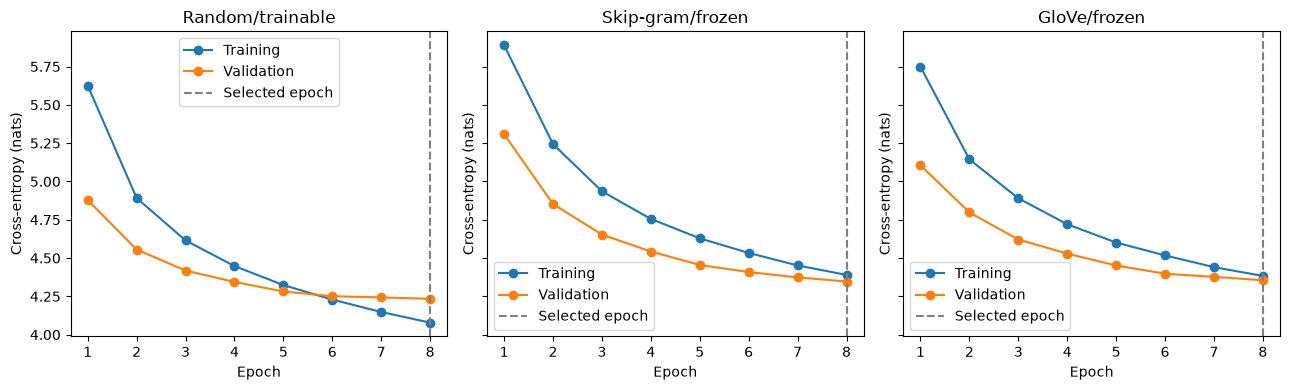

In [36]:
import matplotlib.pyplot as plt
part2_results = {'random_trainable': json.loads((ARTIFACT_DIR / 'lstm_results.json').read_text(encoding='utf-8'))}
for name, model, loaders, record, config, table, coverage in (('lstm_self_frozen', lstm_self_frozen_model, lstm_self_frozen_loaders, lstm_self_frozen_record, lstm_self_frozen_config, self_input_table, self_coverage), ('lstm_glove_frozen', lstm_glove_frozen_model, lstm_glove_frozen_loaders, lstm_glove_frozen_record, lstm_glove_frozen_config, glove_input_table, glove_coverage)):
    checkpoint = torch.load(ARTIFACT_DIR / f'{name}_best.pt', map_location=DEVICE, weights_only=True)
    assert checkpoint['config'] == config and checkpoint['id_to_token'] == id_to_token
    assert checkpoint['corpus_sha256'] == corpus_sha256
    model.load_state_dict(checkpoint['state_dict'])
    model.eval()
    assert not model.embedding.weight.requires_grad
    assert torch.equal(model.embedding.weight.detach().cpu(), table)
    metrics = {split: run_lm_epoch(model, loaders[split], DEVICE) for split in ('train', 'validation', 'test')}
    for split, values in metrics.items():
        assert values['target_count'] == sum((len(s) - 1 for s in encoded_paragraphs[split]))
    assert math.isclose(metrics['validation']['cross_entropy'], checkpoint['validation_cross_entropy'], abs_tol=1e-05)
    result = {**record, 'metrics': metrics, 'embedding_coverage': coverage, 'embedding_statistics': {'mean_row_norm': float(table.norm(dim=1).mean()), 'global_std': float(table.std())}}
    (ARTIFACT_DIR / f'{name}_results.json').write_text(json.dumps(result, indent=2), encoding='utf-8')
    part2_results[name] = result
    print(name, 'selected checkpoint metrics')
    for split, values in metrics.items():
        print(f"{split}: targets={values['target_count']}, CE={values['cross_entropy']:.4f}, PPL={values['perplexity']:.2f}")
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for ax, label, result in zip(axes, ('Random/trainable', 'Skip-gram/frozen', 'GloVe/frozen'), part2_results.values()):
    history = result['history']
    epochs = [row['epoch'] for row in history]
    ax.plot(epochs, [row['train']['cross_entropy'] for row in history], marker='o', label='Training')
    ax.plot(epochs, [row['validation']['cross_entropy'] for row in history], marker='o', label='Validation')
    ax.axvline(result['best_epoch'], linestyle='--', color='gray', label='Selected epoch')
    ax.set(title=label, xlabel='Epoch', ylabel='Cross-entropy (nats)')
    ax.legend()
fig.tight_layout()
fig.savefig(ARTIFACT_DIR / 'part2_lstm_loss_curves.png', dpi=160)
plt.show()
plt.close(fig)


### 2.5.2 Compare Continuations with Matched Decoding

Reuse the exact saved prompts, 50-token length, temperature 0.8, top-k 50, blocked boundaries, and seeds. Save unedited token IDs/text; verify same-seed reproduction for all six new samples. Load existing baseline continuations without rewriting them. Discuss concrete local fluency, repetition, and meaning continuity.

In [37]:
generation_config = json.loads((ARTIFACT_DIR / 'generation_config.json').read_text(encoding='utf-8'))
GENERATION_LENGTH = generation_config['length']
GENERATION_TEMPERATURE = generation_config['temperature']
GENERATION_TOP_K = generation_config['top_k']
GENERATION_BLOCKED_IDS = tuple(generation_config['blocked_token_ids'])
baseline_samples = json.loads((ARTIFACT_DIR / 'lstm_generations.json').read_text(encoding='utf-8'))
assert baseline_samples['config'] == generation_config
part2_samples = {'random_trainable': baseline_samples['samples']}
for name, model in (('lstm_self_frozen', lstm_self_frozen_model), ('lstm_glove_frozen', lstm_glove_frozen_model)):
    samples = []
    for prompt, seed in zip(generation_config['prompts'], generation_config['seeds'], strict=True):
        ids = generate_neural_text(model, prompt, seed, DEVICE)
        assert len(ids) == 50 and (not any((i in GENERATION_BLOCKED_IDS for i in ids)))
        tokens = [id_to_token[i] for i in ids]
        samples.append({'prompt': prompt, 'seed': seed, 'generated_ids': ids, 'generated_tokens': tokens, 'continuation': ' '.join(tokens)})
    for sample in samples:
        assert sample['generated_ids'] == generate_neural_text(model, sample['prompt'], sample['seed'], DEVICE)
    (ARTIFACT_DIR / f'{name}_generations.json').write_text(json.dumps({'config': generation_config, 'best_epoch': part2_results[name]['best_epoch'], 'samples': samples}, indent=2), encoding='utf-8')
    part2_samples[name] = samples
for index, prompt in enumerate(generation_config['prompts']):
    print('Prompt:', prompt)
    for name, samples in part2_samples.items():
        print(name + ':', samples[index]['continuation'])


Prompt: elizabeth was
random_trainable: pleased to the subject . elizabeth to be the <unk> of his own , that the whole party have been seen to her . jane was not a circumstance in short ; and and , though jane was scarcely seen the <unk> of the <unk> , and , had been
lstm_self_frozen: over the day of a ball a few minutes , and <unk> , and his brother , , it was an an <unk> of seeing . she was by her niece on his house , the younger , at least to be , to the other of the same .
lstm_glove_frozen: so much , and to it of the country , and her mother was quite . she would be <unk> him ; and , by the <unk> of its feelings and she could it a most moments in this subject . she was a very <unk> , and a very
Prompt: mr darcy
random_trainable: . he was very strange - - - - shire . there was impossible to be expected ; and , that it would be so ready to be in every power of that part of its contents than it was , it is not <unk> her . and miss bingley
lstm_self_frozen: bennet ; and when elizabeth

### 2.5.3 Summarize LSTM Embedding Tradeoffs

Export matched evaluation results and LM training costs, with independent Skip-gram training cost and public-source provenance. Input trainability changes with vector source, public training uses more data, missing rows differ from matched rows, and vector norms are not normalized. These factors limit causal attribution.

In [38]:
import csv
part2_rows = []
print('Variant                  Test CE   Test PPL  Best epoch  LM wall s   Trainable parameters')
for name, result in part2_results.items():
    coverage = result.get('embedding_coverage')
    row = {'variant': name, 'test_cross_entropy': result['metrics']['test']['cross_entropy'], 'test_perplexity': result['metrics']['test']['perplexity'], 'best_epoch': result['best_epoch'], 'lm_training_wall_seconds': result['training_wall_seconds'], 'total_parameters': result['total_parameters'], 'trainable_parameters': result['trainable_parameters'], 'checkpoint_bytes': result['checkpoint_bytes'], 'type_coverage': None if coverage is None else coverage['type_coverage'], 'test_body_token_coverage': None if coverage is None else coverage['token_coverage']['test']['body_token_coverage']}
    part2_rows.append(row)
    print(f"{name:<24} {row['test_cross_entropy']:>8.4f} {row['test_perplexity']:>10.2f} {row['best_epoch']:>10} {row['lm_training_wall_seconds']:>10.2f} {row['trainable_parameters']:>22}")
sg_record = json.loads((ARTIFACT_DIR / 'skipgram_training.json').read_text(encoding='utf-8'))
comparison = {'architecture': 'LSTM', 'common_config': PART2_LM_CONFIG, 'corpus_sha256': corpus_sha256, 'rows': part2_rows, 'self_embedding_training_seconds': sg_record['training_seconds'], 'self_embedding_pair_construction_seconds': sg_record['construction_seconds'], 'public_acquisition': source_record, 'interpretation_limits': PART2_EMBEDDING_PLAN['interpretation'], 'stability_scope': 'one seed; finite losses and curves checked, not across-seed variance'}
(ARTIFACT_DIR / 'part2_comparison.json').write_text(json.dumps(comparison, indent=2), encoding='utf-8')
with (ARTIFACT_DIR / 'part2_comparison.csv').open('w', encoding='utf-8', newline='') as handle:
    writer = csv.DictWriter(handle, fieldnames=list(part2_rows[0]))
    writer.writeheader()
    writer.writerows(part2_rows)
print(f"Skip-gram training alone: {sg_record['training_seconds']:.2f}s; separate from frozen-LSTM training.")


Variant                  Test CE   Test PPL  Best epoch  LM wall s   Trainable parameters
random_trainable           4.3262      75.66          8     199.88                 946740
lstm_self_frozen           4.4285      83.81          8     171.31                 584740
lstm_glove_frozen          4.4202      83.11          8     173.46                 584740
Skip-gram training alone: 16.85s; separate from frozen-LSTM training.


All three LSTMs select epoch 8 while validation CE is still improving. Random/trainable achieves PPL 75.66, GloVe/frozen 83.11 and Skip-gram/frozen 83.81. Frozen inputs remain unchanged. Coverage, vector scales, external data and trainability confound source-only claims. Generated text remains repetitive or ungrammatical; one seed cannot establish stable rankings.

## 2.6 Exploratory Random-frozen Input Control

### 2.6.1 Train the Matched Random-frozen Control

Recreate the original seed-42 LSTM constructor and its complete random input table. Freeze only the table; retain the original optimizer, data, budget and validation selection. Train the remaining layers from scratch. A completed new checkpoint is restored on rerun; original checkpoints are never retrained. This single-seed, post-hoc control tests input trainability more directly, without eliminating every vector-source or scale confound.

In [39]:
rf_name = 'lstm_random_frozen'
rf_config = dict(json.loads((ARTIFACT_DIR / 'lstm_training.json').read_text(encoding='utf-8'))['config'])
rf_config.update({'embedding_source': 'random initialization', 'input_embedding_frozen': True})
torch.set_num_threads(rf_config['cpu_threads'])
reset_neural_seed(rf_config['seed'])
rf_model = LSTMLanguageModel(VOCAB_SIZE, rf_config['embedding_dim'], rf_config['hidden_dim'], rf_config['dropout'])
rf_initial = {k: v.detach().clone() for k, v in rf_model.state_dict().items()}
reset_neural_seed(rf_config['seed'])
rf_reference = LSTMLanguageModel(VOCAB_SIZE, rf_config['embedding_dim'], rf_config['hidden_dim'], rf_config['dropout'])
assert all((torch.equal(v, rf_reference.state_dict()[k]) for k, v in rf_initial.items()))
del rf_reference
rf_model.embedding.weight.requires_grad_(False)
rf_initial_table = rf_model.embedding.weight.detach().clone()
rf_model = rf_model.to(DEVICE)
rf_loaders = make_lm_loaders(rf_config['seed'], rf_config['batch_size'])
rf_checkpoint_path = ARTIFACT_DIR / f'{rf_name}_best.pt'
rf_record_path = ARTIFACT_DIR / f'{rf_name}_training.json'
if rf_record_path.exists():
    rf_record = json.loads(rf_record_path.read_text(encoding='utf-8'))
    rf_checkpoint = torch.load(rf_checkpoint_path, map_location=DEVICE, weights_only=True)
    assert rf_checkpoint['config'] == rf_config
    assert rf_checkpoint['id_to_token'] == id_to_token and rf_checkpoint['corpus_sha256'] == corpus_sha256
    rf_model.load_state_dict(rf_checkpoint['state_dict'])
    rf_model.eval()
else:
    if rf_checkpoint_path.exists():
        raise RuntimeError('Partial run found. Inspect it explicitly; do not silently overwrite or resume without optimizer state.')
    reset_neural_seed(rf_config['seed'])
    rf_model, rf_record = train_language_model(rf_model, rf_name, rf_config, rf_loaders, DEVICE)
assert torch.equal(rf_model.embedding.weight.detach().cpu(), rf_initial_table)
assert rf_model.embedding.weight.grad is None and (not rf_model.embedding.weight.requires_grad)
assert rf_record['trainable_parameters'] == 584740
rf_metrics = {split: run_lm_epoch(rf_model, rf_loaders[split], DEVICE) for split in ('train', 'validation', 'test')}
assert abs(rf_metrics['validation']['cross_entropy'] - rf_record['best_validation_cross_entropy']) < 1e-05
assert rf_metrics['test']['target_count'] == 14811
rf_result = {k: rf_record[k] for k in ('config', 'best_epoch', 'training_wall_seconds', 'total_parameters', 'trainable_parameters', 'checkpoint_bytes')}
rf_result.update({'metrics': rf_metrics, 'whole_table_unchanged': True, 'initial_state_matches_seed42_baseline_constructor': True, 'initial_embedding_sha256': hashlib.sha256(rf_initial_table.numpy().tobytes()).hexdigest(), 'checkpoint_sha256': hashlib.sha256(rf_checkpoint_path.read_bytes()).hexdigest(), 'corpus_sha256': corpus_sha256, 'actual_epochs': len(rf_record['history']), 'scope': 'single-seed exploratory control; same original initialization and training protocol, only input trainability changes'})
(ARTIFACT_DIR / f'{rf_name}_results.json').write_text(json.dumps(rf_result, indent=2), encoding='utf-8')
print('Random-frozen test:', rf_metrics['test'], 'best epoch:', rf_record['best_epoch'])


Random-frozen test: {'cross_entropy': 4.453147974208095, 'perplexity': 85.89692012943073, 'target_count': 14811, 'total_nll': 65955.5746459961, 'seconds': 0.5229542999986734} best epoch: 8


### 2.6.2 Compare Prediction, Learning and Generation

Compare the four input settings using original saved results and the new checkpoint. Plot training/validation curves and export numeric tables. Generate three matched 50-token continuations using the original prompts, seeds, temperature and top-k. Costs come from different sessions; no universal ranking is claimed.

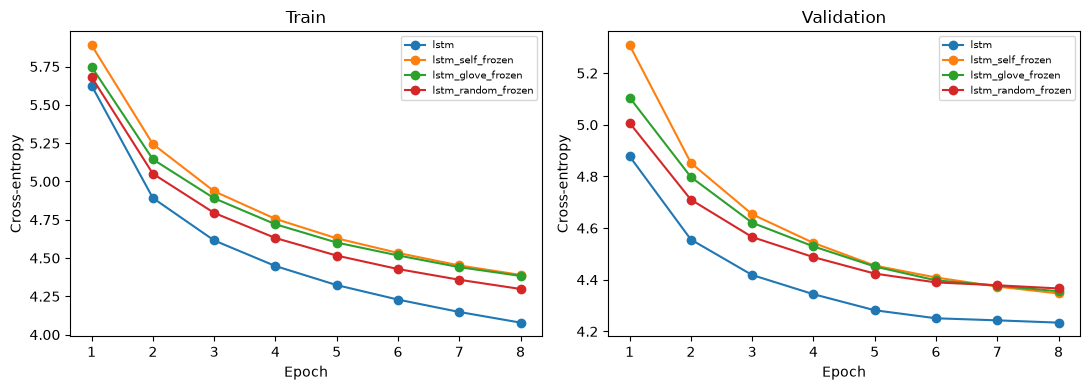

lstm: CE=4.3262, PPL=75.66, best epoch=8
lstm_self_frozen: CE=4.4285, PPL=83.81, best epoch=8
lstm_glove_frozen: CE=4.4202, PPL=83.11, best epoch=8
lstm_random_frozen: CE=4.4531, PPL=85.90, best epoch=8


elizabeth was => only to her to speak of some time , and <unk> in the <unk> , which was to a <unk> manner . the first expression of the evening were of them at rosings at longbourn , for she should have been <unk> , and <unk> to the whole of his


mr darcy => , to the ladies . miss bingley was not at all it , with the same which and her mother was the door , the last week of the appearance . the contrary was <unk> for her spirits were to say at once . it was not that there was


she could not => have been known to her , and the <unk> of wickham's to be of <unk> . " they had been <unk> to jane , but had been in a servant , she was not much engaged . she would be of his hand . it was not the door ,


In [40]:
import matplotlib.pyplot as plt
import csv
rf_comparison = []
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name in ('lstm', 'lstm_self_frozen', 'lstm_glove_frozen', 'lstm_random_frozen'):
    result = json.loads((ARTIFACT_DIR / f'{name}_results.json').read_text(encoding='utf-8'))
    record = json.loads((ARTIFACT_DIR / f'{name}_training.json').read_text(encoding='utf-8'))
    rf_comparison.append({'model': name, 'test_cross_entropy': result['metrics']['test']['cross_entropy'], 'test_perplexity': result['metrics']['test']['perplexity'], 'best_epoch': record['best_epoch'], 'actual_epochs': len(record['history']), 'training_wall_seconds': record['training_wall_seconds'], 'trainable_parameters': record['trainable_parameters']})
    for ax, split in zip(axes, ('train', 'validation')):
        ax.plot([r['epoch'] for r in record['history']], [r[split]['cross_entropy'] for r in record['history']], marker='o', label=name)
        ax.set(xlabel='Epoch', ylabel='Cross-entropy', title=split.capitalize())
        ax.legend(fontsize=7)
fig.tight_layout()
fig.savefig(ARTIFACT_DIR / 'part2_random_frozen_loss_curves.png', dpi=160)
plt.show()
plt.close(fig)
(ARTIFACT_DIR / 'part2_random_frozen_comparison.json').write_text(json.dumps({'rows': rf_comparison, 'scope': 'exploratory single-seed control; original three runs reused', 'timing': 'different execution sessions; not a causal speed comparison'}, indent=2), encoding='utf-8')
with (ARTIFACT_DIR / 'part2_random_frozen_comparison.csv').open('w', encoding='utf-8', newline='') as handle:
    writer = csv.DictWriter(handle, fieldnames=list(rf_comparison[0]))
    writer.writeheader()
    writer.writerows(rf_comparison)
for row in rf_comparison:
    print(f"{row['model']}: CE={row['test_cross_entropy']:.4f}, PPL={row['test_perplexity']:.2f}, best epoch={row['best_epoch']}")
generation_config = json.loads((ARTIFACT_DIR / 'generation_config.json').read_text(encoding='utf-8'))
GENERATION_LENGTH = generation_config['length']
GENERATION_TEMPERATURE = generation_config['temperature']
GENERATION_TOP_K = generation_config['top_k']
GENERATION_BLOCKED_IDS = tuple(generation_config['blocked_token_ids'])
rf_samples = []
for prompt, seed in zip(generation_config['prompts'], generation_config['seeds'], strict=True):
    generated = generate_neural_text(rf_model, prompt, seed, DEVICE)
    assert generated == generate_neural_text(rf_model, prompt, seed, DEVICE)
    assert len(generated) == 50 and (not set(generated) & set(GENERATION_BLOCKED_IDS))
    sample = {'prompt': prompt, 'seed': seed, 'generated_ids': generated, 'continuation': ' '.join((id_to_token[i] for i in generated))}
    rf_samples.append(sample)
    print(prompt, '=>', sample['continuation'])
(ARTIFACT_DIR / 'lstm_random_frozen_generations.json').write_text(json.dumps({'config': generation_config, 'best_epoch': rf_record['best_epoch'], 'samples': rf_samples}, indent=2), encoding='utf-8')


The random-frozen control achieved test PPL 85.90, compared with 75.66 for random/trainable inputs. It completed 8 epochs and selected epoch 8 by validation CE. The entire random input table remained bitwise unchanged. This paired initialization makes the trainability comparison more direct, but the single seed and finite budget limit generalization. Frozen-source comparisons still mix pretraining data and vector scales. The final validation CE change was -0.0123; do not infer full convergence from the budget alone. Generated continuations remain illustrative, and times across sessions do not isolate freezing-related speed changes.

# 3. Part III: Downstream Representation Analysis

## 3.1 Sentiment Task and Evaluation Setup

### 3.1.1 Fix the Representation Comparison and Classifier Protocol

Compare the three fully frozen LSTMs on the same sentiment split. Mean-pool 128d contextual body states, excluding BOS/EOS/PAD. Use identical StandardScaler + logistic regression protocols: train-only fitting, validation macro-F1 selection, then train+validation refit. No LM fine-tuning or test-based selection.

In [41]:
import json, hashlib
from pathlib import Path
required_names = ('tokenize', 'token_to_id', 'id_to_token', 'VOCAB_SIZE', 'DATA_PATH', 'corpus_sha256')
missing_names = [name for name in required_names if name not in globals()]
if missing_names:
    raise RuntimeError('Run the shared data preparation first. Missing: ' + ', '.join(missing_names))
ARTIFACT_DIR = DATA_PATH.resolve().parent / 'artifacts'
PART3_DATA_DIR = DATA_PATH.resolve().parent / 'downstream_data'
PART3_PLAN = {'task': 'binary sentiment classification', 'dataset': 'UCI Sentiment Labelled Sentences', 'dataset_source': 'https://archive.ics.uci.edu/dataset/331/sentiment+labelled+sentences', 'seed': 42, 'split_fractions': {'train': 0.6, 'validation': 0.2, 'test': 0.2}, 'representation_selection': 'three Part II LSTM variants; fixed before downstream metrics', 'representations': [{'name': 'random_trainable_lm', 'checkpoint': 'lstm_best.pt', 'results': 'lstm_results.json'}, {'name': 'skipgram_frozen_lm', 'checkpoint': 'lstm_self_frozen_best.pt', 'results': 'lstm_self_frozen_results.json'}, {'name': 'glove_frozen_lm', 'checkpoint': 'lstm_glove_frozen_best.pt', 'results': 'lstm_glove_frozen_results.json'}], 'feature': 'mean of trained LSTM hidden states at body-token positions; exclude bos/eos/pad', 'dimension': 128, 'language_models': 'fully frozen; eval mode; no fine-tuning', 'input': 'original tokenizer/vocabulary; prepend bos; append eos; no sentence truncation', 'classifier': {'family': 'LogisticRegression', 'solver': 'lbfgs', 'max_iter': 2000, 'C_grid': [0.1, 1.0, 10.0], 'selection': 'validation macro-F1; ties choose smaller C', 'scaling': 'StandardScaler fit only on classifier training rows', 'final_fit': 'after validation selection, refit pipeline on train+validation; evaluate test once'}, 'primary_metric': 'test macro-F1', 'secondary_metric': 'test accuracy', 'diagnostics': 'per-class metrics, confusion matrices, source-level performance, representative errors', 'data_controls': 'deduplicate shared tokenizer keys globally before split; remove conflicting-label groups; stratify source+label', 'limitations': 'novel-to-review domain shift; original vocabulary OOV; one split/seed; source-mixed rather than unseen-domain evaluation', 'question': 'Does the language-model PPL ranking agree with frozen-representation sentiment performance?', 'lm_corpus_sha256': corpus_sha256, 'vocabulary_sha256': hashlib.sha256(json.dumps(id_to_token, ensure_ascii=False).encode('utf-8')).hexdigest(), 'status': 'design and data preparation only; no features/classifiers/test metrics yet'}
for representation in PART3_PLAN['representations']:
    result = json.loads((ARTIFACT_DIR / representation['results']).read_text(encoding='utf-8'))
    assert result['corpus_sha256'] == corpus_sha256
    assert result['config']['hidden_dim'] == 128 and result['config']['embedding_dim'] == 100
    assert (ARTIFACT_DIR / representation['checkpoint']).is_file()
    representation['checkpoint_sha256'] = hashlib.sha256((ARTIFACT_DIR / representation['checkpoint']).read_bytes()).hexdigest()
    representation['recorded_lm_test_ppl'] = result['metrics']['test']['perplexity']
(ARTIFACT_DIR / 'part3_plan.json').write_text(json.dumps(PART3_PLAN, indent=2), encoding='utf-8')
print('Part III: compare three fully frozen LSTM encoders on one labelled sentiment task.')
print('Classifier: identical scaled Logistic Regression family/grid and evaluation protocol.')


Part III: compare three fully frozen LSTM encoders on one labelled sentiment task.
Classifier: identical scaled Logistic Regression family/grid and evaluation protocol.


### 3.1.2 Prepare Labelled Sentences and Freeze Disjoint Splits

Use UCI Sentiment Labelled Sentences (Kotzias, 2015; DOI 10.24432/C57604; CC BY 4.0). Parse physical LF records, deduplicate original tokens before UNK mapping, and stratify by source+label with seed 42. Preserve fixed indices; report UNK and encoded collisions. This is mixed-source evaluation, not unseen-domain transfer.

In [42]:
import zipfile
from collections import Counter, defaultdict
import sklearn
from sklearn.model_selection import train_test_split
part3_source = json.loads((PART3_DATA_DIR / 'uci_source.json').read_text(encoding='utf-8'))
archive_path = PART3_DATA_DIR / part3_source['archive_file']
assert hashlib.sha256(archive_path.read_bytes()).hexdigest() == part3_source['sha256']
raw_rows = []
with zipfile.ZipFile(archive_path) as archive:
    for source, filename in (('amazon', 'amazon_cells_labelled.txt'), ('imdb', 'imdb_labelled.txt'), ('yelp', 'yelp_labelled.txt')):
        member = next((name for name in archive.namelist() if name.endswith('/' + filename)))
        lines = archive.read(member).decode('utf-8-sig').split('\n')
        source_rows = []
        for line_number, line in enumerate(lines, start=1):
            line = line.rstrip('\r')
            if not line.strip():
                continue
            sentence, label = line.rsplit('\t', 1)
            assert label in ('0', '1') and sentence.strip()
            tokens = tokenize(sentence)
            assert tokens
            key = json.dumps(tokens, ensure_ascii=False, separators=(',', ':'))
            source_rows.append({'source': source, 'line': line_number, 'text': sentence, 'label': int(label), 'tokens': tokens, 'id': hashlib.sha256(key.encode('utf-8')).hexdigest(), 'key': key})
        assert len(source_rows) == 1000
        assert Counter((row['label'] for row in source_rows)) == {0: 500, 1: 500}
        raw_rows.extend(source_rows)
groups = defaultdict(list)
for row in raw_rows:
    groups[row['key']].append(row)
clean_rows = []
duplicate_removed = 0
conflicting_removed = 0
for rows in groups.values():
    if len({row['label'] for row in rows}) > 1:
        conflicting_removed += len(rows)
        continue
    duplicate_removed += len(rows) - 1
    chosen = dict(rows[0])
    chosen.pop('key')
    clean_rows.append(chosen)
assert len(clean_rows) + duplicate_removed + conflicting_removed == len(raw_rows)
assert len({row['id'] for row in clean_rows}) == len(clean_rows)
indices = list(range(len(clean_rows)))
strata = [row['source'] + '_' + str(row['label']) for row in clean_rows]
train_ids, holdout_ids = train_test_split(indices, test_size=0.4, stratify=strata, random_state=42)
validation_ids, test_ids = train_test_split(holdout_ids, test_size=0.5, stratify=[strata[i] for i in holdout_ids], random_state=42)
part3_split_indices = {'train': sorted(train_ids), 'validation': sorted(validation_ids), 'test': sorted(test_ids)}
part3_split_rows = {split: [clean_rows[i] for i in ids] for split, ids in part3_split_indices.items()}
assert sum((len(ids) for ids in part3_split_indices.values())) == len(clean_rows)
for first, second in (('train', 'validation'), ('train', 'test'), ('validation', 'test')):
    assert not set((row['id'] for row in part3_split_rows[first])) & set((row['id'] for row in part3_split_rows[second]))
encoded_keys = {split: {tuple((token_to_id.get(t, UNK_ID) for t in row['tokens'])) for row in rows} for split, rows in part3_split_rows.items()}
encoded_collisions = {first + '_' + second: len(encoded_keys[first] & encoded_keys[second]) for first, second in (('train', 'validation'), ('train', 'test'), ('validation', 'test'))}
part3_data_statistics = {}
for split, rows in part3_split_rows.items():
    token_count = sum((len(row['tokens']) for row in rows))
    unknown_count = sum((token not in token_to_id for row in rows for token in row['tokens']))
    part3_data_statistics[split] = {'sentences': len(rows), 'labels': dict(Counter((str(row['label']) for row in rows))), 'source_label_counts': dict(Counter((row['source'] + '_' + str(row['label']) for row in rows))), 'body_tokens': token_count, 'unknown_body_tokens': unknown_count, 'unknown_rate': unknown_count / token_count, 'maximum_body_length': max((len(row['tokens']) for row in rows)), 'mean_body_length': token_count / len(rows)}
part3_dataset = {'source': part3_source, 'seed': 42, 'raw_rows': len(raw_rows), 'retained_rows': len(clean_rows), 'same_label_duplicates_removed': duplicate_removed, 'conflicting_group_rows_removed': conflicting_removed, 'deduplication_key': 'JSON of original LM tokenizer output before unk mapping', 'encoded_cross_split_collisions': encoded_collisions, 'rows': clean_rows, 'split_indices': part3_split_indices, 'statistics': part3_data_statistics, 'sklearn_version': sklearn.__version__, 'lm_vocabulary_sha256': PART3_PLAN['vocabulary_sha256']}
(ARTIFACT_DIR / 'part3_sentiment_data.json').write_text(json.dumps(part3_dataset, ensure_ascii=False, indent=2), encoding='utf-8')
print(f'Raw labelled rows: {len(raw_rows)}; retained: {len(clean_rows)}; duplicate rows removed: {duplicate_removed}; conflicting-label rows removed: {conflicting_removed}')
for split, record in part3_data_statistics.items():
    print(f"{split}: sentences={record['sentences']}, labels={record['labels']}, unk={record['unknown_rate']:.2%}, max body tokens={record['maximum_body_length']}")
print('Cross-split encoded collisions after unk mapping:', encoded_collisions)


Raw labelled rows: 3000; retained: 2979; duplicate rows removed: 21; conflicting-label rows removed: 0
train: sentences=1787, labels={'0': 894, '1': 893}, unk=21.28%, max body tokens=79
validation: sentences=596, labels={'0': 299, '1': 297}, unk=21.41%, max body tokens=51
test: sentences=596, labels={'1': 298, '0': 298}, unk=21.71%, max body tokens=85
Cross-split encoded collisions after unk mapping: {'train_validation': 2, 'train_test': 3, 'validation_test': 3}


## 3.2 Frozen Language-model Representations

### 3.2.1 Restore Encoders and Verify Mean Hidden-state Pooling

Restore the three hash-verified checkpoints and freeze every parameter, not only their input tables. Extract contextual states directly from each trained LSTM layer in evaluation mode. Mean-pool positions 1 through length-2: exclude bos, eos, and padding. Verify single/batched equivalence, eos exclusion, and a one-body-token reference. No language-model weights are trained.

In [43]:
import numpy as np
PART3_PLAN = json.loads((ARTIFACT_DIR / 'part3_plan.json').read_text(encoding='utf-8'))
part3_dataset = json.loads((ARTIFACT_DIR / 'part3_sentiment_data.json').read_text(encoding='utf-8'))
assert PART3_PLAN['lm_corpus_sha256'] == corpus_sha256
vocabulary_hash = hashlib.sha256(json.dumps(id_to_token, ensure_ascii=False).encode('utf-8')).hexdigest()
assert vocabulary_hash == PART3_PLAN['vocabulary_sha256'] == part3_dataset['lm_vocabulary_sha256']
part3_rows = part3_dataset['rows']
part3_indices = {split: np.array(indices, dtype=np.int64) for split, indices in part3_dataset['split_indices'].items()}
assert len(set(np.concatenate(list(part3_indices.values())).tolist())) == len(part3_rows)
part3_encoders = {}
for specification in PART3_PLAN['representations']:
    checkpoint_path = ARTIFACT_DIR / specification['checkpoint']
    assert hashlib.sha256(checkpoint_path.read_bytes()).hexdigest() == specification['checkpoint_sha256']
    checkpoint = torch.load(checkpoint_path, map_location=DEVICE, weights_only=True)
    assert checkpoint['id_to_token'] == id_to_token and checkpoint['corpus_sha256'] == corpus_sha256
    config = checkpoint['config']
    encoder = LSTMLanguageModel(VOCAB_SIZE, config['embedding_dim'], config['hidden_dim'], config['dropout']).to(DEVICE)
    encoder.load_state_dict(checkpoint['state_dict'])
    encoder.requires_grad_(False)
    encoder.eval()
    assert not any((parameter.requires_grad for parameter in encoder.parameters()))
    part3_encoders[specification['name']] = encoder
torch.set_num_threads(4)

def extract_part3_mean_states(encoder, sequences, batch_size=32):
    if encoder.training or any((p.requires_grad for p in encoder.parameters())):
        raise ValueError('The complete encoder must be frozen and in evaluation mode.')
    output = []
    with torch.inference_mode():
        for start in range(0, len(sequences), batch_size):
            items = [torch.tensor(s, dtype=torch.long) for s in sequences[start:start + batch_size]]
            lengths = torch.tensor([len(s) for s in items], dtype=torch.long)
            if bool((lengths < 3).any()):
                raise ValueError('Require bos, at least one body token, and eos.')
            inputs = torch.nn.utils.rnn.pad_sequence(items, batch_first=True, padding_value=PAD_ID).to(DEVICE)
            embeddings = encoder.dropout(encoder.embedding(inputs))
            packed = torch.nn.utils.rnn.pack_padded_sequence(embeddings, lengths, batch_first=True, enforce_sorted=False)
            packed_states, _ = encoder.lstm(packed)
            states, _ = torch.nn.utils.rnn.pad_packed_sequence(packed_states, batch_first=True, total_length=inputs.size(1))
            positions = torch.arange(inputs.size(1), device=DEVICE)[None, :]
            body_mask = (positions >= 1) & (positions < lengths.to(DEVICE)[:, None] - 1)
            assert torch.equal(body_mask.sum(1).cpu(), lengths - 2)
            features = (states * body_mask[:, :, None]).sum(1) / (lengths.to(DEVICE) - 2)[:, None]
            assert features.shape == (len(items), 128) and torch.isfinite(features).all()
            output.append(features.cpu())
    return torch.cat(output, dim=0)
probe_sequences = [[BOS_ID, 4, EOS_ID], [BOS_ID, 5, 6, 7, EOS_ID]]
part3_encoder_checks = {}
for name, encoder in part3_encoders.items():
    batch_features = extract_part3_mean_states(encoder, probe_sequences)
    single_features = torch.cat([extract_part3_mean_states(encoder, [s]) for s in probe_sequences])
    assert torch.allclose(batch_features, single_features, atol=1e-06, rtol=1e-05)
    changed_eos = [s[:-1] + [8] for s in probe_sequences]
    assert torch.allclose(batch_features, extract_part3_mean_states(encoder, changed_eos), atol=1e-06, rtol=1e-05)
    inputs = torch.tensor([probe_sequences[0]], device=DEVICE)
    with torch.inference_mode():
        states, _ = encoder.lstm(encoder.embedding(inputs))
    assert torch.allclose(batch_features[0], states[0, 1], atol=1e-06, rtol=1e-05)
    part3_encoder_checks[name] = {'fully_frozen': True, 'eval_mode': True, 'single_vs_batched': True, 'eos_exclusion_and_causality': True, 'single_body_position_pooling': True}
print('Frozen encoders:', len(part3_encoders), '| pooled feature dimension: 128')


Frozen encoders: 3 | pooled feature dimension: 128


### 3.2.2 Extract Matched Sentence Features

Encode the same retained sentence rows with the original vocabulary, no truncation. Extract 128-dimensional features in batches of 32 and preserve row IDs and labels. Verify finite values, repeated extraction, and bitwise-unchanged encoder weights. Downstream labels do not enter feature extraction; output projection logits are not used.

In [44]:
part3_sequences = [[BOS_ID] + [token_to_id.get(token, UNK_ID) for token in row['tokens']] + [EOS_ID] for row in part3_rows]
part3_labels = np.array([row['label'] for row in part3_rows], dtype=np.int64)
part3_features = {}
part3_feature_records = {}
for name, encoder in part3_encoders.items():
    weights_before = {key: value.detach().cpu().clone() for key, value in encoder.state_dict().items()}
    start = time.perf_counter()
    matrix = extract_part3_mean_states(encoder, part3_sequences, batch_size=32)
    elapsed = time.perf_counter() - start
    assert matrix.shape == (2979, 128)
    repeated = extract_part3_mean_states(encoder, part3_sequences[:32], batch_size=16)
    assert torch.allclose(matrix[:32], repeated, atol=1e-06, rtol=1e-05)
    assert all((torch.equal(value.detach().cpu(), weights_before[key]) for key, value in encoder.state_dict().items()))
    part3_features[name] = matrix.numpy()
    part3_feature_records[name] = {'shape': list(matrix.shape), 'seconds': elapsed, 'batch_size': 32, 'features_sha256': hashlib.sha256(matrix.numpy().tobytes()).hexdigest(), 'encoder_weights_unchanged': True, 'repeat_consistent': True, 'checks': part3_encoder_checks[name]}
    torch.save({'features': matrix, 'row_ids': [row['id'] for row in part3_rows], 'labels': torch.tensor(part3_labels), 'specification': next((s for s in PART3_PLAN['representations'] if s['name'] == name)), 'vocabulary_sha256': vocabulary_hash}, ARTIFACT_DIR / f'part3_{name}_features.pt')
    print(name, 'feature shape:', tuple(matrix.shape), f'extraction={elapsed:.3f}s; frozen weights unchanged.', flush=True)
(ARTIFACT_DIR / 'part3_feature_checks.json').write_text(json.dumps(part3_feature_records, indent=2), encoding='utf-8')


random_trainable_lm feature shape: (2979, 128) extraction=0.302s; frozen weights unchanged.


skipgram_frozen_lm feature shape: (2979, 128) extraction=0.339s; frozen weights unchanged.


glove_frozen_lm feature shape: (2979, 128) extraction=0.316s; frozen weights unchanged.


## 3.3 Shared Classifier Training and Evaluation

### 3.3.1 Select Logistic Regression Regularization on Validation

Use the predeclared C grid and identical StandardScaler+LogisticRegression pipelines. Fit scaling on training rows only and inspect convergence. Select by validation macro-F1, breaking ties with smaller C. Different representations may choose different C using the same procedure. No test scores are consulted. Reference: [scikit-learn leakage guidance](https://scikit-learn.org/stable/common_pitfalls.html).

In [45]:
import warnings
import sklearn
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
from sklearn.exceptions import ConvergenceWarning
from threadpoolctl import threadpool_limits

def make_part3_classifier(C):
    return Pipeline([('scaler', StandardScaler()), ('classifier', LogisticRegression(C=C, solver=PART3_PLAN['classifier']['solver'], max_iter=PART3_PLAN['classifier']['max_iter'], random_state=42))])
part3_selection = {}
train_indices, val_indices, test_indices = [part3_indices[split] for split in ('train', 'validation', 'test')]
for name, matrix in part3_features.items():
    trials = []
    for C in PART3_PLAN['classifier']['C_grid']:
        pipeline = make_part3_classifier(C)
        start = time.perf_counter()
        with warnings.catch_warnings(), threadpool_limits(limits=4):
            warnings.simplefilter('error', ConvergenceWarning)
            pipeline.fit(matrix[train_indices], part3_labels[train_indices])
        assert int(pipeline.named_steps['scaler'].n_samples_seen_) == len(train_indices)
        assert np.allclose(pipeline.named_steps['scaler'].mean_, matrix[train_indices].mean(axis=0, dtype=np.float64))
        predictions = pipeline.predict(matrix[val_indices])
        trials.append({'C': C, 'validation_macro_f1': float(f1_score(part3_labels[val_indices], predictions, average='macro')), 'validation_accuracy': float(accuracy_score(part3_labels[val_indices], predictions)), 'fit_seconds': time.perf_counter() - start, 'iterations': pipeline.named_steps['classifier'].n_iter_.tolist(), 'converged': True})
    best = min(trials, key=lambda row: (-row['validation_macro_f1'], row['C']))
    part3_selection[name] = {'trials': trials, 'selected_C': best['C'], 'selected_validation_macro_f1': best['validation_macro_f1']}
    print(f"{name}: selected C={best['C']:g}, validation macro-F1={best['validation_macro_f1']:.4f}")
(ARTIFACT_DIR / 'part3_classifier_selection.json').write_text(json.dumps(part3_selection, indent=2), encoding='utf-8')


random_trainable_lm: selected C=0.1, validation macro-F1=0.6325


skipgram_frozen_lm: selected C=0.1, validation macro-F1=0.6154
glove_frozen_lm: selected C=0.1, validation macro-F1=0.6727


### 3.3.2 Refit Selected Pipelines and Evaluate the Held-out Test Set

After validation selection, refit the full pipeline on train+validation, keeping test rows outside scaling and fitting. Report test accuracy/macro-F1, per-class/source metrics, confusion matrices and saved predictions. Save numeric classifier/scaler state without executable pickle artifacts. A majority-label reference chooses its label using fit rows only. Do not revise settings after test evaluation.

In [46]:
fit_indices = np.sort(np.concatenate([train_indices, val_indices]))
assert not set(fit_indices.tolist()) & set(test_indices.tolist())
part3_results = {}
part3_predictions = {}
part3_fitted_pipelines = {}
for specification in PART3_PLAN['representations']:
    name = specification['name']
    matrix = part3_features[name]
    pipeline = make_part3_classifier(part3_selection[name]['selected_C'])
    start = time.perf_counter()
    with warnings.catch_warnings(), threadpool_limits(limits=4):
        warnings.simplefilter('error', ConvergenceWarning)
        pipeline.fit(matrix[fit_indices], part3_labels[fit_indices])
    elapsed = time.perf_counter() - start
    scaler, classifier = (pipeline.named_steps['scaler'], pipeline.named_steps['classifier'])
    assert int(scaler.n_samples_seen_) == len(fit_indices)
    assert np.allclose(scaler.mean_, matrix[fit_indices].mean(axis=0, dtype=np.float64))
    probabilities = pipeline.predict_proba(matrix[test_indices])[:, 1]
    predictions = pipeline.predict(matrix[test_indices])
    part3_fitted_pipelines[name] = pipeline
    source_metrics = {}
    for source in ('amazon', 'imdb', 'yelp'):
        mask = np.array([part3_rows[i]['source'] == source for i in test_indices])
        source_metrics[source] = {'count': int(mask.sum()), 'accuracy': float(accuracy_score(part3_labels[test_indices][mask], predictions[mask])), 'macro_f1': float(f1_score(part3_labels[test_indices][mask], predictions[mask], average='macro'))}
    part3_results[name] = {'selected_C': part3_selection[name]['selected_C'], 'validation_macro_f1_before_refit': part3_selection[name]['selected_validation_macro_f1'], 'test_accuracy': float(accuracy_score(part3_labels[test_indices], predictions)), 'test_macro_f1': float(f1_score(part3_labels[test_indices], predictions, average='macro')), 'confusion_matrix': confusion_matrix(part3_labels[test_indices], predictions, labels=[0, 1]).tolist(), 'classification_report': classification_report(part3_labels[test_indices], predictions, labels=[0, 1], output_dict=True, zero_division=0), 'source_metrics': source_metrics, 'lm_test_ppl': specification['recorded_lm_test_ppl'], 'refit_seconds': elapsed, 'refit_samples': len(fit_indices), 'test_samples': len(test_indices), 'final_iterations': classifier.n_iter_.tolist(), 'convergence_warnings': 0}
    part3_predictions[name] = [{'row_index': int(index), 'id': part3_rows[index]['id'], 'source': part3_rows[index]['source'], 'text': part3_rows[index]['text'], 'label': int(part3_labels[index]), 'predicted_label': int(prediction), 'positive_probability': float(probability), 'unknown_tokens': [token for token in part3_rows[index]['tokens'] if token not in token_to_id], 'unknown_rate': sum((token not in token_to_id for token in part3_rows[index]['tokens'])) / len(part3_rows[index]['tokens'])} for index, prediction, probability in zip(test_indices, predictions, probabilities, strict=True)]
    np.savez(ARTIFACT_DIR / f'part3_{name}_classifier.npz', scaler_mean=scaler.mean_, scaler_scale=scaler.scale_, scaler_var=scaler.var_, coefficient=classifier.coef_, intercept=classifier.intercept_, classes=classifier.classes_, selected_C=np.array([part3_selection[name]['selected_C']]))
    print(f"{name}: C={part3_selection[name]['selected_C']}, test accuracy={part3_results[name]['test_accuracy']:.4f}, macro-F1={part3_results[name]['test_macro_f1']:.4f}")
    print('Confusion matrix (true rows, predicted columns; negative/positive):', part3_results[name]['confusion_matrix'])
majority_label = int(np.bincount(part3_labels[fit_indices]).argmax())
majority_predictions = np.full(len(test_indices), majority_label)
part3_result_payload = {'task': PART3_PLAN['task'], 'rows': part3_results, 'protocol': PART3_PLAN, 'feature_records': part3_feature_records, 'sklearn_version': sklearn.__version__, 'dataset_file': 'part3_sentiment_data.json', 'seed': 42, 'majority_baseline': {'label_selected_from_fit_rows': majority_label, 'test_accuracy': float(accuracy_score(part3_labels[test_indices], majority_predictions)), 'test_macro_f1': float(f1_score(part3_labels[test_indices], majority_predictions, average='macro'))}, 'evaluation_note': 'Hyperparameters fixed by validation before final refit; no subsequent test-driven retuning.'}
(ARTIFACT_DIR / 'part3_results.json').write_text(json.dumps(part3_result_payload, indent=2), encoding='utf-8')
(ARTIFACT_DIR / 'part3_test_predictions.json').write_text(json.dumps(part3_predictions, ensure_ascii=False, indent=2), encoding='utf-8')


random_trainable_lm: C=0.1, test accuracy=0.6326, macro-F1=0.6325
Confusion matrix (true rows, predicted columns; negative/positive): [[188, 110], [109, 189]]
skipgram_frozen_lm: C=0.1, test accuracy=0.6359, macro-F1=0.6357
Confusion matrix (true rows, predicted columns; negative/positive): [[182, 116], [101, 197]]


glove_frozen_lm: C=0.1, test accuracy=0.6862, macro-F1=0.6861
Confusion matrix (true rows, predicted columns; negative/positive): [[211, 87], [100, 198]]


## 3.4 Representation Comparison and Error Analysis

### 3.4.1 Inspect Representative Classification Errors

Select one most-confident false positive and false negative for each model by a deterministic rule, retaining text, truth, prediction, probability and unknown-token diagnostics. Also save three deterministic examples where representations disagree. These post-evaluation cases aid interpretation, not hyperparameter tuning; error causes remain hypotheses. Plot all three confusion matrices.

random_trainable_lm representative errors (0=negative, 1=positive):
truth=0, prediction=1, p(positive)=0.903, unk=33.3%
His losing his marbles so early in the proceedings is totally implausible and unconvincing.  
Unknown tokens: ['losing', 'marbles', 'proceedings', 'implausible', 'unconvincing']
truth=1, prediction=0, p(positive)=0.023, unk=20.0%
Not too screamy not to masculine but just right.  
Unknown tokens: ['screamy', 'masculine']
skipgram_frozen_lm representative errors (0=negative, 1=positive):
truth=0, prediction=1, p(positive)=0.942, unk=12.5%
say bye bye to your tip lady!
Unknown tokens: ['tip']
truth=1, prediction=0, p(positive)=0.043, unk=20.0%
Not too screamy not to masculine but just right.  
Unknown tokens: ['screamy', 'masculine']
glove_frozen_lm representative errors (0=negative, 1=positive):
truth=0, prediction=1, p(positive)=0.946, unk=11.1%
I dressed up to be treated so rudely!
Unknown tokens: ['rudely']
truth=1, prediction=0, p(positive)=0.039, unk=28.6%
Def comi

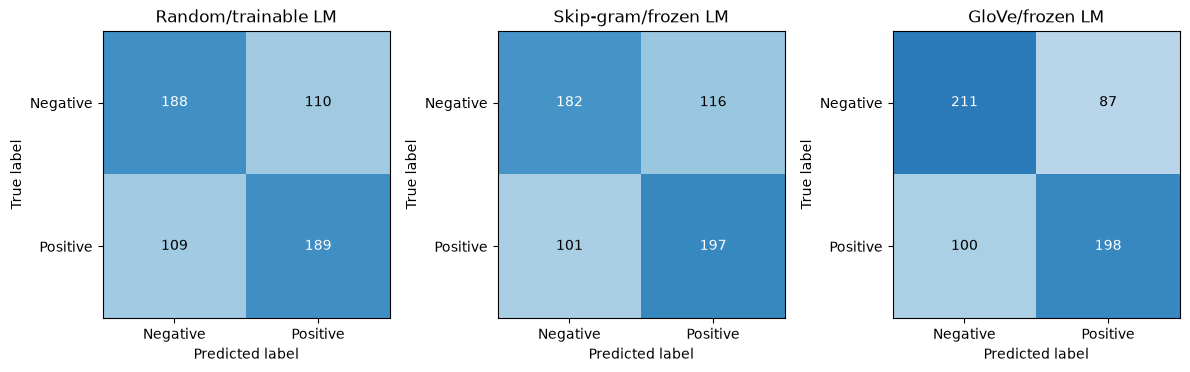

Disagreeing test sentences: 285 ; representative errors and confusion matrices saved.


In [47]:
import matplotlib.pyplot as plt
part3_errors = {}
for name, predictions in part3_predictions.items():
    wrong = [row for row in predictions if row['label'] != row['predicted_label']]
    examples = []
    for true_label in (0, 1):
        candidates = [row for row in wrong if row['label'] == true_label]
        candidates.sort(key=lambda row: (-abs(row['positive_probability'] - 0.5), row['id']))
        examples.extend(candidates[:1])
    part3_errors[name] = {'total_errors': len(wrong), 'examples': examples, 'example_selection': 'one most-confident false positive and false negative; deterministic ID tie break'}
    print(name, 'representative errors (0=negative, 1=positive):')
    for example in examples:
        print(f"truth={example['label']}, prediction={example['predicted_label']}, p(positive)={example['positive_probability']:.3f}, unk={example['unknown_rate']:.1%}")
        print(example['text'])
        print('Unknown tokens:', example['unknown_tokens'])
names = list(part3_predictions)
disagreements = []
for position in range(len(test_indices)):
    rows = {name: part3_predictions[name][position] for name in names}
    if len({row['predicted_label'] for row in rows.values()}) > 1:
        first = rows[names[0]]
        disagreements.append({'id': first['id'], 'text': first['text'], 'source': first['source'], 'label': first['label'], 'predictions': {name: row['predicted_label'] for name, row in rows.items()}})
part3_errors['disagreements'] = {'count': len(disagreements), 'examples': sorted(disagreements, key=lambda row: row['id'])[:3]}
(ARTIFACT_DIR / 'part3_error_analysis.json').write_text(json.dumps(part3_errors, ensure_ascii=False, indent=2), encoding='utf-8')
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
for ax, label, name in zip(axes, ('Random/trainable LM', 'Skip-gram/frozen LM', 'GloVe/frozen LM'), names):
    matrix = np.array(part3_results[name]['confusion_matrix'])
    ax.imshow(matrix, cmap='Blues', vmin=0, vmax=298)
    for row in range(2):
        for column in range(2):
            ax.text(column, row, str(matrix[row, column]), ha='center', va='center', color='white' if matrix[row, column] > 149 else 'black')
    ax.set(title=label, xlabel='Predicted label', ylabel='True label', xticks=[0, 1], yticks=[0, 1], xticklabels=['Negative', 'Positive'], yticklabels=['Negative', 'Positive'])
fig.tight_layout()
fig.savefig(ARTIFACT_DIR / 'part3_confusion_matrices.png', dpi=160)
plt.show()
plt.close(fig)
print('Disagreeing test sentences:', len(disagreements), '; representative errors and confusion matrices saved.')


### 3.4.2 Compare Downstream Ranking with LM Perplexity

Export one matched-task table and compare the observed macro-F1 ordering with held-out LM perplexity. Discuss task/domain mismatch, original-vocabulary unk rates, mean pooling, classifier limitations and single-split uncertainty. Different rankings do not establish universal independence, and matching rankings do not prove causation.

In [48]:
import csv
part3_comparison_rows = [{'representation': name, 'lm_test_ppl': values['lm_test_ppl'], 'validation_macro_f1': values['validation_macro_f1_before_refit'], 'selected_C': values['selected_C'], 'test_accuracy': values['test_accuracy'], 'test_macro_f1': values['test_macro_f1'], 'feature_seconds': part3_feature_records[name]['seconds'], 'classifier_refit_seconds': values['refit_seconds']} for name, values in part3_results.items()]
lm_order = sorted(part3_results, key=lambda name: part3_results[name]['lm_test_ppl'])
task_order = sorted(part3_results, key=lambda name: (-part3_results[name]['test_macro_f1'], name))
part3_comparison = {'rows': part3_comparison_rows, 'lm_order_lower_ppl_first': lm_order, 'downstream_order_higher_macro_f1_first': task_order, 'exact_ranking_agreement': lm_order == task_order, 'interpretation_scope': 'one split/seed and domain-shifted sentiment task; not a universal LM-to-task relationship'}
(ARTIFACT_DIR / 'part3_comparison.json').write_text(json.dumps(part3_comparison, indent=2), encoding='utf-8')
with (ARTIFACT_DIR / 'part3_comparison.csv').open('w', encoding='utf-8', newline='') as handle:
    writer = csv.DictWriter(handle, fieldnames=list(part3_comparison_rows[0]))
    writer.writeheader()
    writer.writerows(part3_comparison_rows)
print('LM order (lower PPL first):', lm_order)
print('Downstream order (higher macro-F1 first):', task_order)


LM order (lower PPL first): ['random_trainable_lm', 'glove_frozen_lm', 'skipgram_frozen_lm']
Downstream order (higher macro-F1 first): ['glove_frozen_lm', 'skipgram_frozen_lm', 'random_trainable_lm']


All LM-feature classifiers select C=0.1. Test macro-F1 ranks GloVe 0.6861, Skip-gram 0.6357, random 0.6325, differing from LM PPL order. Unknown sentiment words, negation, domain shift and mean pooling are plausible error contributors, not isolated causes. Encoders remain frozen; test data do not fit scalers or classifiers. One split/seed limits generalization.

## 3.5 Exploratory Classification Baseline and Uncertainty

### 3.5.1 Fix the Exploratory Extension Protocol

These extensions were designed after seeing the original test results. Freeze the split and choices before new evaluation; do not revise original models. Ideas were informed by the [peer repository](https://github.com/daichenze081-ui/DSA-assignment/tree/fbfd0285134f354de4fbf440392e076e62cebcd7); code is independently adapted to this project's artifacts. Statistics condition on fixed models. TF-IDF uses downstream training vocabulary, so it is a practical baseline rather than a controlled LM ablation.

In [49]:
from pathlib import Path
import json, hashlib, time, warnings
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
from sklearn.exceptions import ConvergenceWarning
from threadpoolctl import threadpool_limits
from scipy.special import expit
from scipy.stats import binomtest
from itertools import combinations
EXT_ROOT = Path.cwd()
if not (EXT_ROOT / 'artifacts').exists():
    EXT_ROOT = EXT_ROOT / 'Assignment1_project'
EXT_ART = EXT_ROOT / 'artifacts'

def ext_read(name):
    return json.loads((EXT_ART / name).read_text(encoding='utf-8'))

def ext_save(name, value):
    (EXT_ART / name).write_text(json.dumps(value, ensure_ascii=False, indent=2), encoding='utf-8')
ext_data = ext_read('part3_sentiment_data.json')
ext_rows = ext_data['rows']
ext_splits = {k: np.asarray(v, dtype=np.int64) for k, v in ext_data['split_indices'].items()}
ext_labels = np.asarray([r['label'] for r in ext_rows])
ext_tokens = [r['tokens'] for r in ext_rows]
ext_train, ext_val, ext_test = [ext_splits[s] for s in ('train', 'validation', 'test')]
ext_fit = np.sort(np.concatenate([ext_train, ext_val]))
assert len(ext_fit) == 2383 and len(ext_test) == 596
assert not set(ext_fit) & set(ext_test)
ext_plan = {'status': 'exploratory extensions designed after inspecting original test results', 'date': '2026-10-16', 'tfidf': {'ngram_range': [1, 2], 'min_df': 2, 'max_features': 50000, 'sublinear_tf': True, 'norm': 'l2', 'C_grid': [0.1, 1.0, 10.0], 'solver': 'lbfgs', 'max_iter': 2000, 'seed': 42, 'tokens': 'saved original tokenizer output before LM unk mapping', 'selection': 'fit vectorizer and classifier on train; select validation macro-F1, lower C on ties', 'final_fit': 'refit vectorizer and classifier on train+validation; test once', 'scaling': 'L2-normalized TF-IDF; no additional dense StandardScaler'}, 'statistics': {'replicates': 10000, 'seed': 4213, 'unit': 'test sentence', 'method': 'paired ordinary percentile bootstrap; same indices for every model', 'pairs': 'all six pairs among three saved LM classifiers and TF-IDF', 'p_values': 'exact two-sided McNemar; Holm correction across six pairs', 'scope': 'fixed fitted models; excludes training and split variability'}, 'random_frozen': {'seed': 42, 'max_epochs': 8, 'initialization': 'same original LSTM constructor and seed', 'change': 'freeze complete randomly initialized input table only', 'selection': 'validation CE only; original training procedure'}, 'design_reference': 'https://github.com/daichenze081-ui/DSA-assignment/tree/fbfd0285134f354de4fbf440392e076e62cebcd7', 'attribution': "Extension ideas informed by the peer repository; implementation adapted independently to this project's saved data and protocols. Attribution and tool-use details are in README.md.", 'data_sha256': hashlib.sha256((EXT_ART / 'part3_sentiment_data.json').read_bytes()).hexdigest(), 'original_predictions_sha256': hashlib.sha256((EXT_ART / 'part3_test_predictions.json').read_bytes()).hexdigest()}
plan_path = EXT_ART / 'supplementary_plan.json'
if plan_path.exists():
    saved_plan = ext_read('supplementary_plan.json')
    assert {k: v for k, v in saved_plan.items() if k != 'attribution'} == {k: v for k, v in ext_plan.items() if k != 'attribution'}
else:
    ext_save('supplementary_plan.json', ext_plan)


### 3.5.2 Fit a TF-IDF Logistic Regression Baseline

Use saved original tokens, word unigrams/bigrams, min_df=2 and a 50,000-feature cap. Fit vocabulary/IDF on train only for validation selection, using the original C grid 0.1/1/10. Refit vocabulary, IDF and classifier on train+validation after selection, matching Section 3.3.2. L2-normalized TF-IDF needs no dense standardization. Save probabilities, numeric parameters and all trials. [TfidfVectorizer documentation](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html).

In [50]:
def ext_identity(tokens):
    return tokens

def ext_vectorizer(vocabulary=None):
    return TfidfVectorizer(tokenizer=ext_identity, preprocessor=None, token_pattern=None, lowercase=False, ngram_range=(1, 2), min_df=2, max_features=50000, sublinear_tf=True, norm='l2', vocabulary=vocabulary)

def ext_classifier(C):
    return LogisticRegression(C=C, solver='lbfgs', max_iter=2000, random_state=42)

def ext_fit_classifier(C, X, y):
    model = ext_classifier(C)
    with warnings.catch_warnings(), threadpool_limits(limits=4):
        warnings.simplefilter('error', ConvergenceWarning)
        model.fit(X, y)
    return model
started = time.perf_counter()
ext_vector = ext_vectorizer()
ext_X_train = ext_vector.fit_transform([ext_tokens[i] for i in ext_train])
ext_X_val = ext_vector.transform([ext_tokens[i] for i in ext_val])
ext_trials = []
for C in ext_plan['tfidf']['C_grid']:
    clf = ext_fit_classifier(C, ext_X_train, ext_labels[ext_train])
    pred = clf.predict(ext_X_val)
    ext_trials.append({'C': C, 'validation_macro_f1': float(f1_score(ext_labels[ext_val], pred, average='macro')), 'validation_accuracy': float(accuracy_score(ext_labels[ext_val], pred)), 'iterations': clf.n_iter_.tolist()})
ext_best = min(ext_trials, key=lambda r: (-r['validation_macro_f1'], r['C']))
ext_selection = {'trials': ext_trials, 'selected_C': ext_best['C'], 'training_feature_dimension': ext_X_train.shape[1], 'training_vocabulary': {k: int(v) for k, v in ext_vector.vocabulary_.items()}, 'training_idf': ext_vector.idf_.tolist(), 'selection_seconds': time.perf_counter() - started}
ext_save('part3_tfidf_selection.json', ext_selection)
print(f"TF-IDF selected C={ext_best['C']:g}, validation macro-F1={ext_best['validation_macro_f1']:.4f}")
started = time.perf_counter()
ext_final_vector = ext_vectorizer()
ext_X_fit = ext_final_vector.fit_transform([ext_tokens[i] for i in ext_fit])
ext_final_clf = ext_fit_classifier(ext_best['C'], ext_X_fit, ext_labels[ext_fit])
ext_refit_seconds = time.perf_counter() - started
ext_X_test = ext_final_vector.transform([ext_tokens[i] for i in ext_test])
ext_tfidf_pred = ext_final_clf.predict(ext_X_test)
ext_tfidf_prob = ext_final_clf.predict_proba(ext_X_test)[:, 1]
ext_tfidf_result = {'protocol': ext_plan['tfidf'], 'selected_C': ext_best['C'], 'validation_macro_f1': ext_best['validation_macro_f1'], 'test_accuracy': float(accuracy_score(ext_labels[ext_test], ext_tfidf_pred)), 'test_macro_f1': float(f1_score(ext_labels[ext_test], ext_tfidf_pred, average='macro')), 'confusion_matrix': confusion_matrix(ext_labels[ext_test], ext_tfidf_pred).tolist(), 'classification_report': classification_report(ext_labels[ext_test], ext_tfidf_pred, output_dict=True), 'final_feature_dimension': ext_X_fit.shape[1], 'fit_samples': len(ext_fit), 'test_samples': len(ext_test), 'final_iterations': ext_final_clf.n_iter_.tolist(), 'refit_seconds': ext_refit_seconds, 'convergence_warnings': 0, 'zero_feature_test_sentences': int((ext_X_test.getnnz(axis=1) == 0).sum()), 'interpretation': 'Task-trained vocabulary and sparse word/bigram features differ from frozen novel-LM features; this is a practical baseline, not an isolated architecture comparison.'}
ext_tfidf_result['source_metrics'] = {}
for source in sorted({r['source'] for r in ext_rows}):
    mask = np.array([ext_rows[i]['source'] == source for i in ext_test])
    ext_tfidf_result['source_metrics'][source] = {'count': int(mask.sum()), 'accuracy': float(accuracy_score(ext_labels[ext_test][mask], ext_tfidf_pred[mask])), 'macro_f1': float(f1_score(ext_labels[ext_test][mask], ext_tfidf_pred[mask], average='macro'))}
ext_save('part3_tfidf_results.json', ext_tfidf_result)
ext_save('part3_tfidf_vocabulary.json', {k: int(v) for k, v in ext_final_vector.vocabulary_.items()})
np.savez_compressed(EXT_ART / 'part3_tfidf_classifier.npz', idf=ext_final_vector.idf_, coefficients=ext_final_clf.coef_, intercept=ext_final_clf.intercept_, classes=ext_final_clf.classes_, C=np.array(ext_best['C']))
ext_tfidf_records = [{'row_index': int(i), 'id': ext_rows[i]['id'], 'source': ext_rows[i]['source'], 'text': ext_rows[i]['text'], 'label': int(ext_labels[i]), 'predicted_label': int(p), 'positive_probability': float(prob)} for i, p, prob in zip(ext_test, ext_tfidf_pred, ext_tfidf_prob)]
ext_save('part3_tfidf_test_predictions.json', ext_tfidf_records)
saved = np.load(EXT_ART / 'part3_tfidf_classifier.npz')
restored_vector = ext_vectorizer(ext_read('part3_tfidf_vocabulary.json'))
restored_vector.idf_ = saved['idf']
restored_X = restored_vector.transform([ext_tokens[i] for i in ext_test])
restored_probability = expit(np.asarray(restored_X @ saved['coefficients'].T).ravel() + saved['intercept'][0])
assert np.allclose(restored_probability, ext_tfidf_prob, atol=1e-12)
assert np.array_equal((restored_probability > 0.5).astype(int), ext_tfidf_pred)
print(f"TF-IDF: accuracy={ext_tfidf_result['test_accuracy']:.4f}, macro-F1={ext_tfidf_result['test_macro_f1']:.4f}, features={ext_tfidf_result['final_feature_dimension']}")


TF-IDF selected C=10, validation macro-F1=0.8221


TF-IDF: accuracy=0.8255, macro-F1=0.8254, features=5399


### 3.5.3 Quantify Paired Test Uncertainty

Align all predictions by saved sentence IDs. Use 10,000 paired sentence resamples (seed 4213) for pointwise percentile intervals on accuracy, macro-F1 and all pairwise differences. Compute exact two-sided McNemar tests and Holm-adjust six comparisons. No-discordance p=1. Intervals exclude training/split variability and remain exploratory. [SciPy binomial test](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.binomtest.html).

In [51]:
ext_existing_predictions = ext_read('part3_test_predictions.json')
ext_existing_results = ext_read('part3_results.json')['rows']
ext_all_predictions = dict(ext_existing_predictions)
ext_all_predictions['tfidf'] = ext_read('part3_tfidf_test_predictions.json')
ext_expected_ids = [ext_rows[i]['id'] for i in ext_test]
ext_y = ext_labels[ext_test]
ext_predictions = {}
for name, records in ext_all_predictions.items():
    assert [r['id'] for r in records] == ext_expected_ids
    assert np.array_equal([r['label'] for r in records], ext_y)
    ext_predictions[name] = np.array([r['predicted_label'] for r in records])
    recorded = ext_existing_results[name] if name != 'tfidf' else ext_read('part3_tfidf_results.json')
    assert abs(accuracy_score(ext_y, ext_predictions[name]) - recorded['test_accuracy']) < 1e-12
    assert abs(f1_score(ext_y, ext_predictions[name], average='macro') - recorded['test_macro_f1']) < 1e-12

def ext_binary_macro_f1(y, p):
    tp = ((y == 1) & (p == 1)).sum(axis=-1)
    tn = ((y == 0) & (p == 0)).sum(axis=-1)
    errors = (y != p).sum(axis=-1)
    return (2 * tp / np.maximum(2 * tp + errors, 1) + 2 * tn / np.maximum(2 * tn + errors, 1)) / 2
ext_rng = np.random.default_rng(4213)
ext_bootstrap = {name: {'accuracy': [], 'macro_f1': []} for name in ext_predictions}
for start in range(0, 10000, 250):
    indices = ext_rng.integers(0, len(ext_y), size=(250, len(ext_y)))
    y_batch = ext_y[indices]
    for name, pred in ext_predictions.items():
        p_batch = pred[indices]
        ext_bootstrap[name]['accuracy'].append((p_batch == y_batch).mean(axis=1))
        ext_bootstrap[name]['macro_f1'].append(ext_binary_macro_f1(y_batch, p_batch))
        if start == 0:
            for k in range(3):
                assert abs(ext_binary_macro_f1(y_batch[k], p_batch[k]) - f1_score(y_batch[k], p_batch[k], labels=[0, 1], average='macro', zero_division=0)) < 1e-12
ext_bootstrap = {name: {metric: np.concatenate(values) for metric, values in scores.items()} for name, scores in ext_bootstrap.items()}
ext_stats = {'protocol': ext_plan['statistics'], 'models': {}, 'pairs': []}
for name, pred in ext_predictions.items():
    ext_stats['models'][name] = {'accuracy': float(accuracy_score(ext_y, pred)), 'macro_f1': float(f1_score(ext_y, pred, average='macro')), **{metric + '_ci95': np.quantile(values, [0.025, 0.975]).tolist() for metric, values in ext_bootstrap[name].items()}}
for a, b in combinations(ext_predictions, 2):
    ca, cb = (ext_predictions[a] == ext_y, ext_predictions[b] == ext_y)
    a_only, b_only = (int((ca & ~cb).sum()), int((cb & ~ca).sum()))
    pair = {'a': a, 'b': b, 'direction': 'b minus a', 'a_only_correct': a_only, 'b_only_correct': b_only, 'mcnemar_exact_p': float(binomtest(a_only, a_only + b_only, 0.5).pvalue) if a_only + b_only else 1.0}
    for metric in ('accuracy', 'macro_f1'):
        pair[metric + '_difference'] = ext_stats['models'][b][metric] - ext_stats['models'][a][metric]
        pair[metric + '_difference_ci95'] = np.quantile(ext_bootstrap[b][metric] - ext_bootstrap[a][metric], [0.025, 0.975]).tolist()
    ext_stats['pairs'].append(pair)
running = 0.0
for rank, index in enumerate(sorted(range(6), key=lambda i: ext_stats['pairs'][i]['mcnemar_exact_p'])):
    running = max(running, (6 - rank) * ext_stats['pairs'][index]['mcnemar_exact_p'])
    ext_stats['pairs'][index]['mcnemar_holm_p'] = min(1.0, running)
ext_stats['limitations'] = 'Exploratory post-hoc analysis. Pointwise percentile intervals, not simultaneous intervals. Sentence resampling assumes independent test units; source/reviewer dependence may remain. No retraining uncertainty, no confirmation on fresh data, and no test-driven model retuning.'
ext_save('part3_uncertainty.json', ext_stats)
print('Model | Accuracy | Macro-F1 | 95% F1 interval')
for name, row in ext_stats['models'].items():
    print(f"{name} | {row['accuracy']:.4f} | {row['macro_f1']:.4f} | [{row['macro_f1_ci95'][0]:.3f}, {row['macro_f1_ci95'][1]:.3f}]")
print('Comparison (b - a) | Accuracy difference | 95% interval | Holm p')
for row in ext_stats['pairs']:
    print(f"{row['b']} - {row['a']} | {row['accuracy_difference']:+.4f} | [{row['accuracy_difference_ci95'][0]:+.3f}, {row['accuracy_difference_ci95'][1]:+.3f}] | {row['mcnemar_holm_p']:.3g}")


Model | Accuracy | Macro-F1 | 95% F1 interval
random_trainable_lm | 0.6326 | 0.6325 | [0.592, 0.671]
skipgram_frozen_lm | 0.6359 | 0.6357 | [0.596, 0.673]
glove_frozen_lm | 0.6862 | 0.6861 | [0.648, 0.723]
tfidf | 0.8255 | 0.8254 | [0.794, 0.854]
Comparison (b - a) | Accuracy difference | 95% interval | Holm p
skipgram_frozen_lm - random_trainable_lm | +0.0034 | [-0.044, +0.050] | 0.945
glove_frozen_lm - random_trainable_lm | +0.0537 | [+0.010, +0.097] | 0.0639
tfidf - random_trainable_lm | +0.1930 | [+0.149, +0.237] | 4.04e-16
glove_frozen_lm - skipgram_frozen_lm | +0.0503 | [+0.007, +0.094] | 0.0639
tfidf - skipgram_frozen_lm | +0.1896 | [+0.148, +0.232] | 2.29e-16
tfidf - glove_frozen_lm | +0.1393 | [+0.099, +0.180] | 1.5e-10


TF-IDF selects C=10 (the search boundary), with accuracy 0.8255 and macro-F1 0.8254 over 5,399 features. Its advantage survives six-pair Holm correction. GloVe has the highest LM-feature score, but its adjusted comparisons are not significant at 0.05. Bootstrap conditions on fitted models and excludes training/split variability; all extensions remain exploratory.